## GitHub Repository 
https://github.com/thaninnada/Statistical_Techniques_Sep2026

In [2]:
# Import necessary libraries
import numpy as np # linear algebra 
import pandas as pd # data processing
import matplotlib.pyplot as plt # data visualization
import matplotlib as mpl # data visualization : colour
import seaborn as sns # data visualization

from scipy.stats import norm, binom, poisson, chisquare, probplot
from matplotlib.ticker import FuncFormatter


## 1. Load and Overview Dataset

### 1.1 Demographic (DEMO_L) dataset overall

In [3]:
# Load the demographic dataset
demographic_df = pd.read_csv('DEMO_L.csv')

In [4]:
# Check dataset structure
print("Demographic dataset")
print("Demographic Rows:", demographic_df.shape[0])
print("Demographic Columns:", demographic_df.shape[1])

display(demographic_df.head())
demographic_df.info()

Demographic dataset
Demographic Rows: 11933
Demographic Columns: 27


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   SDDSRVYR  11933 non-null  float64
 2   RIDSTATR  11933 non-null  float64
 3   RIAGENDR  11933 non-null  float64
 4   RIDAGEYR  11933 non-null  float64
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  float64
 7   RIDRETH3  11933 non-null  float64
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  float64
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  4020 non-null   float64
 21  

In [5]:
# Check dataset dimensions
print("Demographic Shape:", demographic_df.shape)

# Check column names
print("\nDemographic Column names:")
display(demographic_df.columns.tolist())

# Check data types
print("\nDemographic Data types:")
display(demographic_df.dtypes)

# Generate descriptive statistics
print("\nDemographic Descriptive statistics:")
display(demographic_df.describe(include="all").T)

Demographic Shape: (11933, 27)

Demographic Column names:


['SEQN',
 'SDDSRVYR',
 'RIDSTATR',
 'RIAGENDR',
 'RIDAGEYR',
 'RIDAGEMN',
 'RIDRETH1',
 'RIDRETH3',
 'RIDEXMON',
 'RIDEXAGM',
 'DMQMILIZ',
 'DMDBORN4',
 'DMDYRUSR',
 'DMDEDUC2',
 'DMDMARTZ',
 'RIDEXPRG',
 'DMDHHSIZ',
 'DMDHRGND',
 'DMDHRAGZ',
 'DMDHREDZ',
 'DMDHRMAZ',
 'DMDHSEDZ',
 'WTINT2YR',
 'WTMEC2YR',
 'SDMVSTRA',
 'SDMVPSU',
 'INDFMPIR']


Demographic Data types:


SEQN        float64
SDDSRVYR    float64
RIDSTATR    float64
RIAGENDR    float64
RIDAGEYR    float64
RIDAGEMN    float64
RIDRETH1    float64
RIDRETH3    float64
RIDEXMON    float64
RIDEXAGM    float64
DMQMILIZ    float64
DMDBORN4    float64
DMDYRUSR    float64
DMDEDUC2    float64
DMDMARTZ    float64
RIDEXPRG    float64
DMDHHSIZ    float64
DMDHRGND    float64
DMDHRAGZ    float64
DMDHREDZ    float64
DMDHRMAZ    float64
DMDHSEDZ    float64
WTINT2YR    float64
WTMEC2YR    float64
SDMVSTRA    float64
SDMVPSU     float64
INDFMPIR    float64
dtype: object


Demographic Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,11933.0,136344.000000,3444.904716,1.303780e+05,1.333610e+05,136344.00000,139327.000000,142310.000000
SDDSRVYR,11933.0,12.000000,0.000000,1.200000e+01,1.200000e+01,12.00000,12.000000,12.000000
RIDSTATR,11933.0,1.742479,0.437287,1.000000e+00,1.000000e+00,2.00000,2.000000,2.000000
RIAGENDR,11933.0,1.532808,0.498943,1.000000e+00,1.000000e+00,2.00000,2.000000,2.000000
RIDAGEYR,11933.0,38.317858,25.601990,5.397605e-79,1.300000e+01,37.00000,62.000000,80.000000
RIDAGEMN,377.0,11.628647,6.805429,5.397605e-79,6.000000e+00,11.00000,17.000000,24.000000
RIDRETH1,11933.0,3.104584,1.076346,1.000000e+00,3.000000e+00,3.00000,4.000000,5.000000
RIDRETH3,11933.0,3.320540,1.518379,1.000000e+00,3.000000e+00,3.00000,4.000000,7.000000
RIDEXMON,8860.0,1.520203,0.499620,1.000000e+00,1.000000e+00,2.00000,2.000000,2.000000
RIDEXAGM,2787.0,121.908504,67.158655,5.397605e-79,6.600000e+01,122.00000,179.500000,239.000000


### 1.2 Depression Screener (DPQ_L) dataset overall

In [6]:
# load the depression dataset
depression_df = pd.read_csv('DPQ_L.csv')

In [7]:
# Check dataset structure
print("Depression dataset")
print("Depression Rows:", depression_df.shape[0])
print("Depression Columns:", depression_df.shape[1])

display(depression_df.head())
depression_df.info()

Depression dataset
Depression Rows: 6337
Depression Columns: 11


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,130378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
2,130380.0,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
3,130386.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
4,130387.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN


<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   DPQ010  5519 non-null   float64
 2   DPQ020  5518 non-null   float64
 3   DPQ030  5516 non-null   float64
 4   DPQ040  5514 non-null   float64
 5   DPQ050  5513 non-null   float64
 6   DPQ060  5510 non-null   float64
 7   DPQ070  5508 non-null   float64
 8   DPQ080  5508 non-null   float64
 9   DPQ090  5506 non-null   float64
 10  DPQ100  4167 non-null   float64
dtypes: float64(11)
memory usage: 544.7 KB


In [8]:
# Check dataset dimensions
print("Depression Shape:", depression_df.shape)

# Check column names
print("\nDepression Column names:")
display(depression_df.columns.tolist())

# Check data types
print("\nDepression Data types:")
display(depression_df.dtypes)

# Generate descriptive statistics
print("\nDepression Descriptive statistics:")
display(depression_df.describe(include="all").T)

Depression Shape: (6337, 11)

Depression Column names:


['SEQN',
 'DPQ010',
 'DPQ020',
 'DPQ030',
 'DPQ040',
 'DPQ050',
 'DPQ060',
 'DPQ070',
 'DPQ080',
 'DPQ090',
 'DPQ100']


Depression Data types:


SEQN      float64
DPQ010    float64
DPQ020    float64
DPQ030    float64
DPQ040    float64
DPQ050    float64
DPQ060    float64
DPQ070    float64
DPQ080    float64
DPQ090    float64
DPQ100    float64
dtype: object


Depression Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,6337.0,136348.738362,3439.132476,1.303780e+05,1.333370e+05,1.363970e+05,1.393100e+05,142310.0
DPQ010,5519.0,0.510962,0.946665,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ020,5518.0,0.478615,0.838724,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ030,5516.0,0.793510,1.003693,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ040,5514.0,0.860174,0.965127,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,9.0
DPQ050,5513.0,0.504263,0.860577,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ060,5510.0,0.411071,0.786979,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ070,5508.0,0.394880,0.767524,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,9.0
DPQ080,5508.0,0.216594,0.685077,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0
DPQ090,5506.0,0.082092,0.438164,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,9.0


### 1.3 Medical Conditions (MCQ_L) dataset overall

In [9]:
# load the medical dataset
medical_df = pd.read_csv('MCQ_L.csv')

In [10]:
# Check dataset structure
print("Medical dataset")
print("Medical Rows:", medical_df.shape[0])
print("Medical Columns:", medical_df.shape[1])

display(medical_df.head())
medical_df.info()

Medical dataset
Medical Rows: 11744
Medical Columns: 35


,SEQN,MCQ010,MCQ035,MCQ040,MCQ050,AGQ030,MCQ053,MCQ149,MCQ160A,MCQ195,...,MCQ510E,MCQ510F,MCQ550,MCQ560,MCQ220,MCQ230A,MCQ230B,MCQ230C,MCQ230D,OSQ230
0,130378.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,1.0,2.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
1,130379.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,1.0,30.0,NaN,NaN,NaN,1.0
2,130380.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 11744 entries, 0 to 11743
Data columns (total 35 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     11744 non-null  float64
 1   MCQ010   11743 non-null  float64
 2   MCQ035   1946 non-null   float64
 3   MCQ040   1219 non-null   float64
 4   MCQ050   1219 non-null   float64
 5   AGQ030   11743 non-null  float64
 6   MCQ053   11741 non-null  float64
 7   MCQ149   434 non-null    float64
 8   MCQ160A  7807 non-null   float64
 9   MCQ195   2532 non-null   float64
 10  MCQ160B  7808 non-null   float64
 11  MCQ160C  7807 non-null   float64
 12  MCQ160D  7808 non-null   float64
 13  MCQ160E  7807 non-null   float64
 14  MCQ160F  7806 non-null   float64
 15  MCQ160M  7806 non-null   float64
 16  MCQ170M  1053 non-null   float64
 17  MCQ160P  7807 non-null   float64
 18  MCQ160L  7807 non-null   float64
 19  MCQ170L  425 non-null    float64
 20  MCQ500   1578 non-null   float64
 21  MCQ510A  260 non-null  

In [11]:
# Check dataset dimensions
print("Medical Shape:", medical_df.shape)

# Check column names
print("\nMedical Column names:")
display(medical_df.columns.tolist())

# Check data types
print("\nMedical Data types:")
display(medical_df.dtypes)

# Generate descriptive statistics
print("\nMedical Descriptive statistics:")
display(medical_df.describe(include="all").T)

Medical Shape: (11744, 35)

Medical Column names:


['SEQN',
 'MCQ010',
 'MCQ035',
 'MCQ040',
 'MCQ050',
 'AGQ030',
 'MCQ053',
 'MCQ149',
 'MCQ160A',
 'MCQ195',
 'MCQ160B',
 'MCQ160C',
 'MCQ160D',
 'MCQ160E',
 'MCQ160F',
 'MCQ160M',
 'MCQ170M',
 'MCQ160P',
 'MCQ160L',
 'MCQ170L',
 'MCQ500',
 'MCQ510A',
 'MCQ510B',
 'MCQ510C',
 'MCQ510D',
 'MCQ510E',
 'MCQ510F',
 'MCQ550',
 'MCQ560',
 'MCQ220',
 'MCQ230A',
 'MCQ230B',
 'MCQ230C',
 'MCQ230D',
 'OSQ230']


Medical Data types:


SEQN       float64
MCQ010     float64
MCQ035     float64
MCQ040     float64
MCQ050     float64
AGQ030     float64
MCQ053     float64
MCQ149     float64
MCQ160A    float64
MCQ195     float64
MCQ160B    float64
MCQ160C    float64
MCQ160D    float64
MCQ160E    float64
MCQ160F    float64
MCQ160M    float64
MCQ170M    float64
MCQ160P    float64
MCQ160L    float64
MCQ170L    float64
MCQ500     float64
MCQ510A    float64
MCQ510B    float64
MCQ510C    float64
MCQ510D    float64
MCQ510E    float64
MCQ510F    float64
MCQ550     float64
MCQ560     float64
MCQ220     float64
MCQ230A    float64
MCQ230B    float64
MCQ230C    float64
MCQ230D    float64
OSQ230     float64
dtype: object


Medical Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,11744.0,136347.896373,3445.908868,130378.0,133359.75,136354.5,139327.25,142310.0
MCQ010,11743.0,1.843226,0.451382,1.0,2.00,2.0,2.00,9.0
MCQ035,1946.0,1.506680,1.146900,1.0,1.00,1.0,2.00,9.0
MCQ040,1219.0,1.538146,0.657767,1.0,1.00,2.0,2.00,9.0
MCQ050,1219.0,1.879409,0.445073,1.0,2.00,2.0,2.00,9.0
AGQ030,11743.0,1.830537,0.439566,1.0,2.00,2.0,2.00,9.0
MCQ053,11741.0,1.967720,0.259203,1.0,2.00,2.0,2.00,9.0
MCQ149,434.0,1.884793,0.600692,1.0,2.00,2.0,2.00,9.0
MCQ160A,7807.0,1.690918,0.579254,1.0,1.00,2.0,2.00,9.0
MCQ195,2532.0,3.093602,3.064873,1.0,1.00,1.0,4.00,9.0


### 1.4 Income (INQ_L) dataset quality check

In [12]:
# Load the Income dataset
income_df = pd.read_csv('INQ_L.csv')

In [13]:
# Check dataset structure
print("Income dataset")
print("Income Rows:", income_df.shape[0])
print("Income Columns:", income_df.shape[1])

display(income_df.head())
income_df.info()

Income dataset
Income Rows: 11933
Income Columns: 5


,SEQN,INDFMMPI,INDFMMPC,INQ300,IND310
0,130378.0,5.00,3.0,1.0,NaN
1,130379.0,5.00,3.0,1.0,NaN
2,130380.0,1.40,2.0,2.0,1.0
3,130381.0,0.33,1.0,2.0,1.0
4,130382.0,4.32,3.0,1.0,NaN


<class 'pandas.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   INDFMMPI  8989 non-null   float64
 2   INDFMMPC  10464 non-null  float64
 3   INQ300    10468 non-null  float64
 4   IND310    5650 non-null   float64
dtypes: float64(5)
memory usage: 466.3 KB


In [14]:
# Check dataset dimensions
print("Income Shape:", income_df.shape)

# Check column names
print("\nIncome Column names:")
display(income_df.columns.tolist())

# Check data types
print("\nIncome Data types:")
display(income_df.dtypes)

# Generate descriptive statistics
print("\nIncome Descriptive statistics:")
display(income_df.describe(include="all").T)

Income Shape: (11933, 5)

Income Column names:


['SEQN', 'INDFMMPI', 'INDFMMPC', 'INQ300', 'IND310']


Income Data types:


SEQN        float64
INDFMMPI    float64
INDFMMPC    float64
INQ300      float64
IND310      float64
dtype: object


Income Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,11933.0,136344.000000,3444.904716,1.303780e+05,133361.00,136344.00,139327.0,142310.0
INDFMMPI,8989.0,2.529415,1.607884,5.397605e-79,1.16,2.16,4.0,5.0
INDFMMPC,10464.0,2.419438,1.315262,1.000000e+00,1.00,3.00,3.0,9.0
INQ300,10468.0,1.796141,1.299623,1.000000e+00,1.00,2.00,2.0,9.0
IND310,5650.0,3.606549,13.268089,1.000000e+00,1.00,1.00,2.0,99.0


### 1.5 Physical Activity (PAQ_L) dataset quality check

In [15]:
# Load the Physical Activity dataset
activity_df = pd.read_csv('PAQ_L.csv')

In [16]:
# Check dataset structure
print("Physical Activity dataset")
print("Physical Activity Rows:", activity_df.shape[0])
print("Physical Activity Columns:", activity_df.shape[1])

display(activity_df.head())
activity_df.info()

Physical Activity dataset
Physical Activity Rows: 8153
Physical Activity Columns: 8


,SEQN,PAD790Q,PAD790U,PAD800,PAD810Q,PAD810U,PAD820,PAD680
0,130378.0,3.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,360.0
1,130379.0,4.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,480.0
2,130380.0,1.000000e+00,b'W',20.0,5.397605e-79,b'',NaN,240.0
3,130384.0,5.397605e-79,b'',NaN,5.397605e-79,b'',NaN,60.0
4,130385.0,1.000000e+00,b'D',90.0,1.000000e+00,b'W',60.0,180.0


<class 'pandas.DataFrame'>
RangeIndex: 8153 entries, 0 to 8152
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SEQN     8153 non-null   float64
 1   PAD790Q  8135 non-null   float64
 2   PAD790U  8153 non-null   str    
 3   PAD800   6390 non-null   float64
 4   PAD810Q  8139 non-null   float64
 5   PAD810U  8153 non-null   str    
 6   PAD820   3687 non-null   float64
 7   PAD680   8138 non-null   float64
dtypes: float64(6), str(2)
memory usage: 509.7 KB


In [17]:
# Check dataset dimensions
print("Physical Activity Shape:", activity_df.shape)

# Check column names
print("\nPhysical Activity Column names:")
display(activity_df.columns.tolist())

# Check data types
print("\nPhysical Activity Data types:")
display(activity_df.dtypes)

# Generate descriptive statistics
print("\nPhysical Activity Descriptive statistics:")
display(activity_df.describe(include="all").T)

Physical Activity Shape: (8153, 8)

Physical Activity Column names:


['SEQN',
 'PAD790Q',
 'PAD790U',
 'PAD800',
 'PAD810Q',
 'PAD810U',
 'PAD820',
 'PAD680']


Physical Activity Data types:


SEQN       float64
PAD790Q    float64
PAD790U        str
PAD800     float64
PAD810Q    float64
PAD810U        str
PAD820     float64
PAD680     float64
dtype: object


Physical Activity Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SEQN,8153.0,NaN,NaN,NaN,136378.394579,3440.455897,130378.0,133395.0,136419.0,139346.0,142310.0
PAD790Q,8135.0,NaN,NaN,NaN,60.142471,741.708337,0.0,1.0,2.0,4.0,9999.0
PAD790U,8153,5,b'W',4851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAD800,6390.0,NaN,NaN,NaN,93.437715,544.415142,1.0,30.0,60.0,60.0,9999.0
PAD810Q,8139.0,NaN,NaN,NaN,49.210837,685.272196,0.0,0.0,0.0,2.0,9999.0
PAD810U,8153,5,b'',4467,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PAD820,3687.0,NaN,NaN,NaN,97.571467,605.421908,1.0,30.0,45.0,60.0,9999.0
PAD680,8138.0,NaN,NaN,NaN,446.982674,917.464153,0.0,180.0,300.0,480.0,9999.0


### 1.6 Sleep Disorders (SLQ_L) dataset quality check

In [18]:
# Load the Sleep Disorders dataset
sleep_df = pd.read_csv('SLQ_L.csv')

In [19]:
# Check dataset structure
print("Sleep Demographic dataset")
print("Sleep Rows:", sleep_df.shape[0])
print("Sleep Columns:", sleep_df.shape[1])

display(sleep_df.head())
sleep_df.info()

Sleep Demographic dataset
Sleep Rows: 8501
Sleep Columns: 7


,SEQN,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013
0,130378.0,b'21:30',b'07:00',9.5,b'00:00',b'09:00',9.0
1,130379.0,b'21:00',b'06:00',9.0,b'21:00',b'06:00',9.0
2,130380.0,b'00:00',b'08:00',8.0,b'00:00',b'09:00',9.0
3,130384.0,b'21:30',b'05:00',7.5,b'23:00',b'07:00',8.0
4,130385.0,b'22:05',b'06:15',8.0,b'22:05',b'06:15',8.0


<class 'pandas.DataFrame'>
RangeIndex: 8501 entries, 0 to 8500
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    8501 non-null   float64
 1   SLQ300  8501 non-null   str    
 2   SLQ310  8501 non-null   str    
 3   SLD012  8388 non-null   float64
 4   SLQ320  8501 non-null   str    
 5   SLQ330  8501 non-null   str    
 6   SLD013  8387 non-null   float64
dtypes: float64(3), str(4)
memory usage: 465.0 KB


In [20]:
# Check dataset dimensions
print("Sleep Shape:", sleep_df.shape)

# Check column names
print("\nSleep Column names:")
display(sleep_df.columns.tolist())

# Check data types
print("\nSleep Data types:")
display(sleep_df.dtypes)

# Generate descriptive statistics
print("\nSleep Descriptive statistics:")
display(sleep_df.describe(include="all").T)

Sleep Shape: (8501, 7)

Sleep Column names:


['SEQN', 'SLQ300', 'SLQ310', 'SLD012', 'SLQ320', 'SLQ330', 'SLD013']


Sleep Data types:


SEQN      float64
SLQ300        str
SLQ310        str
SLD012    float64
SLQ320        str
SLQ330        str
SLD013    float64
dtype: object


Sleep Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
SEQN,8501.0,NaN,NaN,NaN,136369.136572,3443.283289,130378.0,133378.0,136402.0,139342.0,142310.0
SLQ300,8501,79,b'22:00',1714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SLQ310,8501,109,b'06:00',1513,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SLD012,8388.0,NaN,NaN,NaN,7.757332,1.616056,2.0,7.0,8.0,8.5,14.0
SLQ320,8501,71,b'23:00',1646,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SLQ330,8501,73,b'07:00',1384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SLD013,8387.0,NaN,NaN,NaN,8.353762,1.730015,2.0,7.5,8.5,9.0,14.0


### 1.7 Alcohol Use (ALQ_L) dataset quality check

In [21]:
# load the Alcohol dataset
alcohol_df = pd.read_csv('ALQ_L.csv')

In [22]:
# Check dataset structure
print("Alcohol dataset")
print("Alcohol Rows:", alcohol_df.shape[0])
print("Alcohol Columns:", alcohol_df.shape[1])

display(alcohol_df.head())
alcohol_df.info()

Alcohol dataset
Alcohol Rows: 6337
Alcohol Columns: 9


,SEQN,ALQ111,ALQ121,ALQ130,ALQ142,ALQ270,ALQ280,ALQ151,ALQ170
0,130378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,1.0,2.000000e+00,3.0,5.397605e-79,NaN,NaN,2.0,NaN
2,130380.0,1.0,1.000000e+01,1.0,5.397605e-79,NaN,NaN,2.0,NaN
3,130386.0,1.0,4.000000e+00,2.0,1.000000e+01,5.397605e-79,10.0,2.0,5.397605e-79
4,130387.0,1.0,5.397605e-79,NaN,NaN,NaN,NaN,2.0,NaN


<class 'pandas.DataFrame'>
RangeIndex: 6337 entries, 0 to 6336
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   SEQN    6337 non-null   float64
 1   ALQ111  5481 non-null   float64
 2   ALQ121  4922 non-null   float64
 3   ALQ130  4069 non-null   float64
 4   ALQ142  4082 non-null   float64
 5   ALQ270  2366 non-null   float64
 6   ALQ280  2362 non-null   float64
 7   ALQ151  4901 non-null   float64
 8   ALQ170  2358 non-null   float64
dtypes: float64(9)
memory usage: 445.7 KB


In [23]:
# Check dataset dimensions
print("Alcohol Shape:", alcohol_df.shape)

# Check column names
print("\nAlcohol Column names:")
display(alcohol_df.columns.tolist())

# Check data types
print("\nAlcohol Data types:")
display(alcohol_df.dtypes)

# Generate descriptive statistics
print("\nAlcohol Descriptive statistics:")
display(alcohol_df.describe(include="all").T)

Alcohol Shape: (6337, 9)

Alcohol Column names:


['SEQN',
 'ALQ111',
 'ALQ121',
 'ALQ130',
 'ALQ142',
 'ALQ270',
 'ALQ280',
 'ALQ151',
 'ALQ170']


Alcohol Data types:


SEQN      float64
ALQ111    float64
ALQ121    float64
ALQ130    float64
ALQ142    float64
ALQ270    float64
ALQ280    float64
ALQ151    float64
ALQ170    float64
dtype: object


Alcohol Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,6337.0,136348.738362,3439.132476,1.303780e+05,1.333370e+05,1.363970e+05,139310.0,142310.0
ALQ111,5481.0,1.109104,0.385114,1.000000e+00,1.000000e+00,1.000000e+00,1.0,9.0
ALQ121,4922.0,5.030679,4.314321,5.397605e-79,2.000000e+00,5.000000e+00,8.0,99.0
ALQ130,4069.0,5.842959,54.996448,1.000000e+00,1.000000e+00,2.000000e+00,3.0,999.0
ALQ142,4082.0,4.742283,7.326042,5.397605e-79,5.397605e-79,4.000000e+00,9.0,99.0
ALQ270,2366.0,4.838123,7.785415,5.397605e-79,5.397605e-79,4.000000e+00,9.0,99.0
ALQ280,2362.0,3.545301,7.133496,5.397605e-79,5.397605e-79,5.397605e-79,7.0,99.0
ALQ151,4901.0,1.821261,0.458352,1.000000e+00,2.000000e+00,2.000000e+00,2.0,9.0
ALQ170,2358.0,4.396098,45.252453,5.397605e-79,5.397605e-79,1.000000e+00,2.0,999.0


### 1.8 Body Measures (BMX_L) dataset overall

In [24]:
# load the depression dataset
body_df = pd.read_csv('BMX_L.csv')

In [25]:
# Check dataset structure
print("Body Measures dataset")
print("Body Measures Rows:", body_df.shape[0])
print("Body Measures Columns:", body_df.shape[1])

display(body_df.head())
body_df.info()

Body Measures dataset
Body Measures Rows: 8860
Body Measures Columns: 22


,SEQN,BMDSTATS,BMXWT,BMIWT,BMXRECUM,BMIRECUM,BMXHEAD,BMIHEAD,BMXHT,BMIHT,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,130378.0,1.0,86.9,NaN,NaN,NaN,NaN,NaN,179.5,NaN,...,42.8,NaN,42.0,NaN,35.7,NaN,98.3,NaN,102.9,NaN
1,130379.0,1.0,101.8,NaN,NaN,NaN,NaN,NaN,174.2,NaN,...,38.5,NaN,38.7,NaN,33.7,NaN,114.7,NaN,112.4,NaN
2,130380.0,1.0,69.4,NaN,NaN,NaN,NaN,NaN,152.9,NaN,...,38.5,NaN,35.5,NaN,36.3,NaN,93.5,NaN,98.0,NaN
3,130381.0,1.0,34.3,NaN,NaN,NaN,NaN,NaN,120.1,NaN,...,NaN,NaN,25.4,NaN,23.4,NaN,70.4,NaN,NaN,NaN
4,130382.0,3.0,13.6,NaN,NaN,1.0,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 8860 entries, 0 to 8859
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      8860 non-null   float64
 1   BMDSTATS  8860 non-null   float64
 2   BMXWT     8754 non-null   float64
 3   BMIWT     345 non-null    float64
 4   BMXRECUM  454 non-null    float64
 5   BMIRECUM  18 non-null     float64
 6   BMXHEAD   70 non-null     float64
 7   BMIHEAD   0 non-null      float64
 8   BMXHT     8499 non-null   float64
 9   BMIHT     134 non-null    float64
 10  BMXBMI    8471 non-null   float64
 11  BMDBMIC   2492 non-null   float64
 12  BMXLEG    7335 non-null   float64
 13  BMILEG    396 non-null    float64
 14  BMXARML   8568 non-null   float64
 15  BMIARML   200 non-null    float64
 16  BMXARMC   8562 non-null   float64
 17  BMIARMC   205 non-null    float64
 18  BMXWAIST  8190 non-null   float64
 19  BMIWAIST  347 non-null    float64
 20  BMXHIP    6776 non-null   float64
 21  BM

In [26]:
# Check dataset dimensions
print("Body Measures Shape:", body_df.shape)
print("\nBody Measures Column Names:")
display(body_df.columns.tolist())
print("\nBody Measures Data Types:")
display(body_df.dtypes)
print("\nBody Measures Descriptive Statistics:")
display(body_df.describe(include="all").T)

Body Measures Shape: (8860, 22)

Body Measures Column Names:


['SEQN',
 'BMDSTATS',
 'BMXWT',
 'BMIWT',
 'BMXRECUM',
 'BMIRECUM',
 'BMXHEAD',
 'BMIHEAD',
 'BMXHT',
 'BMIHT',
 'BMXBMI',
 'BMDBMIC',
 'BMXLEG',
 'BMILEG',
 'BMXARML',
 'BMIARML',
 'BMXARMC',
 'BMIARMC',
 'BMXWAIST',
 'BMIWAIST',
 'BMXHIP',
 'BMIHIP']


Body Measures Data Types:


SEQN        float64
BMDSTATS    float64
BMXWT       float64
BMIWT       float64
BMXRECUM    float64
BMIRECUM    float64
BMXHEAD     float64
BMIHEAD     float64
BMXHT       float64
BMIHT       float64
BMXBMI      float64
BMDBMIC     float64
BMXLEG      float64
BMILEG      float64
BMXARML     float64
BMIARML     float64
BMXARMC     float64
BMIARMC     float64
BMXWAIST    float64
BMIWAIST    float64
BMXHIP      float64
BMIHIP      float64
dtype: object


Body Measures Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
SEQN,8860.0,136345.828217,3453.776310,130378.0,133319.750,136377.5,139336.25,142310.0
BMDSTATS,8860.0,1.132280,0.503848,1.0,1.000,1.0,1.00,4.0
BMXWT,8754.0,70.549037,30.389021,2.7,54.200,71.7,89.10,248.2
BMIWT,345.0,2.881159,0.624424,1.0,3.000,3.0,3.00,4.0
BMXRECUM,454.0,84.329956,14.058157,48.5,73.475,84.7,96.10,118.8
BMIRECUM,18.0,1.000000,0.000000,1.0,1.000,1.0,1.00,1.0
BMXHEAD,70.0,41.932857,2.798484,34.4,40.200,42.4,44.00,46.5
BMIHEAD,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BMXHT,8499.0,159.664549,19.864943,79.1,154.400,163.6,172.10,200.7
BMIHT,134.0,2.313433,0.953174,1.0,1.000,3.0,3.00,3.0


## 2. Quality Check & Data Cleaning before Merge Dataset

### 2.1 Demographic (DEMO_L) dataset quality check

In [27]:
# Check missing values
demographic_df.isnull().sum()

SEQN            0
SDDSRVYR        0
RIDSTATR        0
RIAGENDR        0
RIDAGEYR        0
RIDAGEMN    11556
RIDRETH1        0
RIDRETH3        0
RIDEXMON     3073
RIDEXAGM     9146
DMQMILIZ     3632
DMDBORN4       19
DMDYRUSR    10058
DMDEDUC2     4139
DMDMARTZ     4141
RIDEXPRG    10430
DMDHHSIZ        0
DMDHRGND     7818
DMDHRAGZ     7809
DMDHREDZ     8187
DMDHRMAZ     7913
DMDHSEDZ     9806
WTINT2YR        0
WTMEC2YR        0
SDMVSTRA        0
SDMVPSU         0
INDFMPIR     2041
dtype: int64

In [28]:
# Count missing values per column
demo_missing_summary = pd.DataFrame({
    "DEMO_Missing_Count": demographic_df.isna().sum(),
    "DEMO_Missing_Percentage(%)": (demographic_df.isna().mean() * 100).round(2)})
display(demo_missing_summary.sort_values("DEMO_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("DEMO Duplicate SEQN:", demographic_df["SEQN"].duplicated().sum())

,DEMO_Missing_Count,DEMO_Missing_Percentage(%)
RIDAGEMN,11556,96.84
RIDEXPRG,10430,87.40
DMDYRUSR,10058,84.29
DMDHSEDZ,9806,82.18
RIDEXAGM,9146,76.64
DMDHREDZ,8187,68.61
DMDHRMAZ,7913,66.31
DMDHRGND,7818,65.52
DMDHRAGZ,7809,65.44
DMDMARTZ,4141,34.70


DEMO Duplicate SEQN: 0


#### 2.1.1 SEQN variable - Respondent sequence number

In [29]:
# Check SEQN identifiers
print("Total rows SEQN:", len(demographic_df))
print("Unique SEQN:", demographic_df["SEQN"].nunique())
print("Missing SEQN:", demographic_df["SEQN"].isna().sum())

# Check duplicate IDs and rows
print("Duplicate rows:", demographic_df.duplicated().sum())
print("Duplicate SEQN:", demographic_df["SEQN"].duplicated().sum())

# Display duplicated SEQN IDs
duplicate_seqn = demographic_df.loc[demographic_df["SEQN"].duplicated(keep=False)].sort_values("SEQN")

display(duplicate_seqn)

Total rows SEQN: 11933
Unique SEQN: 11933
Missing SEQN: 0
Duplicate rows: 0
Duplicate SEQN: 0


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR


#### 2.1.2 SDDSRVYR variable - Data release cycle

##### SDDSRVYR: identifies the specific data release cycle. A value of “12” denotes NHANES August 2021-August 2023 data.

In [30]:
# Check SDDSRVYR identifiers
print("Total rows SDDSRVYR:", len(demographic_df))
print("Unique SDDSRVYR:", demographic_df["SDDSRVYR"].nunique())
print("Missing SDDSRVYR:", demographic_df["SDDSRVYR"].isna().sum())

# Check duplicate data cycle and rows
print("Duplicate SDDSRVYR:", demographic_df["SDDSRVYR"].duplicated().sum())
print("Distribution SDDSRVYR:", demographic_df["SDDSRVYR"].value_counts(dropna=False))

# Display duplicated Data release cycle
duplicate_data_cycle = demographic_df.loc[demographic_df["SDDSRVYR"].duplicated(keep=False)].sort_values("SDDSRVYR")

display(duplicate_data_cycle)

Total rows SDDSRVYR: 11933
Unique SDDSRVYR: 1
Missing SDDSRVYR: 0
Duplicate SDDSRVYR: 11932
Distribution SDDSRVYR: SDDSRVYR
12.0    11933
Name: count, dtype: int64


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,4.300000e+01,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,5.437446e+04,173.0,2.0,5.00
7949,138327.0,12.0,2.0,1.0,4.400000e+01,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,42136.926852,5.701925e+04,178.0,2.0,2.06
7950,138328.0,12.0,2.0,1.0,5.700000e+01,NaN,5.0,7.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,9511.153808,1.312783e+04,176.0,1.0,0.43
7951,138329.0,12.0,2.0,2.0,5.600000e+01,NaN,4.0,4.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29354.913194,4.108520e+04,184.0,2.0,2.34
7952,138330.0,12.0,2.0,2.0,6.400000e+01,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,14989.784762,1.956172e+04,185.0,2.0,4.89
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3980,134358.0,12.0,1.0,1.0,6.000000e+00,NaN,5.0,7.0,NaN,NaN,...,2.0,2.0,1.0,3.0,NaN,8616.013088,5.397605e-79,184.0,2.0,NaN
3981,134359.0,12.0,2.0,2.0,5.700000e+01,NaN,3.0,3.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,104941.799499,1.103085e+05,186.0,1.0,NaN
3982,134360.0,12.0,2.0,1.0,5.397605e-79,7.0,3.0,3.0,2.0,8.0,...,2.0,2.0,3.0,1.0,2.0,8986.792238,1.666583e+04,173.0,1.0,2.40
3973,134351.0,12.0,1.0,2.0,7.000000e+01,NaN,2.0,2.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,17949.631666,5.397605e-79,176.0,1.0,5.00


#### 2.1.3 RIAGENDR variable - Gender

In [31]:
# Check gender identifiers
print("Total rows of Gender:", len(demographic_df))
print("Unique Gender:", demographic_df["RIAGENDR"].nunique())
print("Missing Gender:", demographic_df["RIAGENDR"].isna().sum())

# Check duplicate Gender
print("Duplicate Gender:", demographic_df["RIAGENDR"].duplicated().sum())

# Count gender distribution
print("Distribution Gender:", demographic_df["RIAGENDR"].value_counts(dropna=False))

# Display duplicated age
duplicate_gender = demographic_df.loc[demographic_df["RIAGENDR"].duplicated(keep=False)].sort_values("RIAGENDR")

display(duplicate_gender)

Total rows of Gender: 11933
Unique Gender: 2
Missing Gender: 0
Duplicate Gender: 11931
Distribution Gender: RIAGENDR
2.0    6358
1.0    5575
Name: count, dtype: int64


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,5.437446e+04,173.0,2.0,5.00
4786,135164.0,12.0,1.0,1.0,10.0,NaN,4.0,4.0,NaN,NaN,...,2.0,3.0,2.0,3.0,NaN,8138.627270,5.397605e-79,184.0,2.0,1.54
4785,135163.0,12.0,1.0,1.0,3.0,NaN,4.0,4.0,NaN,NaN,...,2.0,2.0,3.0,1.0,NaN,13926.811671,5.397605e-79,187.0,1.0,0.11
9462,139840.0,12.0,2.0,1.0,56.0,NaN,3.0,3.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,12567.448339,1.535440e+04,175.0,1.0,5.00
4783,135161.0,12.0,2.0,1.0,19.0,NaN,3.0,3.0,1.0,229.0,...,2.0,3.0,2.0,2.0,NaN,12124.472674,1.434695e+04,183.0,1.0,2.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5294,135672.0,12.0,2.0,2.0,33.0,NaN,3.0,3.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,19573.895150,2.679302e+04,180.0,1.0,1.92
5293,135671.0,12.0,2.0,2.0,36.0,NaN,4.0,4.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,9788.531059,1.237673e+04,187.0,2.0,1.78
5290,135668.0,12.0,2.0,2.0,61.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,12705.540224,1.444325e+04,184.0,2.0,1.18
5480,135858.0,12.0,2.0,2.0,70.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,23036.034591,2.976826e+04,184.0,1.0,3.29


In [32]:
# Display gender descriptive statistics
print("Gender summary:")
display(demographic_df["RIAGENDR"].describe())

Gender summary:


count    11933.000000
mean         1.532808
std          0.498943
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max          2.000000
Name: RIAGENDR, dtype: float64

##### Gender of the participant.
1: Male,	
2: Female

In [33]:
# Convert gender codes to labels and summarize
# Value descriptio "1 = Mail", "2 = Female" reference information from NHANES
genders_labels = {1: "Male", 2: "Female"}
demographic_df["Genders"] = demographic_df["RIAGENDR"].map(genders_labels)

# Summarize gender counts and percentages
gender_summary = pd.DataFrame({
    "DEMO_gender_Count": demographic_df["Genders"].value_counts(dropna=False),
    "DEMO_gender_Percentage(%)": (demographic_df["Genders"].value_counts(normalize=True, dropna=False) * 100).round(2)})

# Add total row
gender_summary.loc["Total"] = [len(demographic_df), 100.00]
display(gender_summary)


,DEMO_gender_Count,DEMO_gender_Percentage(%)
Genders,,
Female,6358.0,53.28
Male,5575.0,46.72
Total,11933.0,100.00


#### 2.1.4 RIDAGEYR variable - Age

##### Age in years of the participant at the time of screening. Individuals 80 and over are top-coded at 80 years of age.

In [34]:
# Check Age identifiers
print("Total rows of Age:", len(demographic_df))
print("Unique Age:", demographic_df["RIDAGEYR"].nunique())
print("Missing Age:", demographic_df["RIDAGEYR"].isna().sum())

# Check duplicate age
print("Duplicate Age:", demographic_df["RIDAGEYR"].duplicated().sum())

# Count age distribution
print("Distribution Age:", demographic_df["RIDAGEYR"].value_counts(dropna=False))

# Display duplicated age
duplicate_age = demographic_df.loc[demographic_df["RIDAGEYR"].duplicated(keep=False)].sort_values("RIDAGEYR")

display(duplicate_age)

Total rows of Age: 11933
Unique Age: 81
Missing Age: 0
Duplicate Age: 11852
Distribution Age: RIDAGEYR
80.0    525
8.0     257
5.0     246
4.0     229
12.0    228
       ... 
79.0     82
23.0     82
47.0     76
78.0     73
20.0     71
Name: count, Length: 81, dtype: int64


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR,Genders
559,130937.0,12.0,1.0,1.0,5.397605e-79,8.0,5.0,7.0,NaN,NaN,...,2.0,1.0,3.0,NaN,16065.614479,5.397605e-79,178.0,1.0,0.38,Male
5160,135538.0,12.0,2.0,1.0,5.397605e-79,10.0,5.0,7.0,1.0,11.0,...,2.0,2.0,2.0,NaN,13311.426112,2.138049e+04,185.0,1.0,1.71,Male
551,130929.0,12.0,1.0,1.0,5.397605e-79,1.0,3.0,3.0,NaN,NaN,...,2.0,NaN,1.0,3.0,15915.578190,5.397605e-79,187.0,2.0,4.34,Male
9831,140209.0,12.0,2.0,1.0,5.397605e-79,7.0,4.0,4.0,1.0,8.0,...,3.0,3.0,1.0,1.0,11144.594118,1.579599e+04,179.0,1.0,0.61,Male
11476,141854.0,12.0,1.0,2.0,5.397605e-79,3.0,5.0,7.0,NaN,NaN,...,3.0,2.0,1.0,1.0,12400.161504,5.397605e-79,176.0,1.0,0.39,Female
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5590,135968.0,12.0,2.0,1.0,8.000000e+01,NaN,3.0,3.0,1.0,NaN,...,NaN,NaN,NaN,NaN,16994.377586,2.714072e+04,183.0,1.0,2.73,Male
7439,137817.0,12.0,2.0,2.0,8.000000e+01,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,24496.045558,4.796759e+04,181.0,1.0,NaN,Female
1923,132301.0,12.0,1.0,1.0,8.000000e+01,NaN,5.0,7.0,NaN,NaN,...,NaN,NaN,NaN,NaN,23565.205172,5.397605e-79,181.0,2.0,NaN,Male
5713,136091.0,12.0,2.0,1.0,8.000000e+01,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,17537.811417,2.139731e+04,173.0,1.0,3.82,Male


In [35]:
# Display age descriptive statistics
print("Age summary:")
display(demographic_df["RIDAGEYR"].describe())

Age summary:


count    1.193300e+04
mean     3.831786e+01
std      2.560199e+01
min      5.397605e-79
25%      1.300000e+01
50%      3.700000e+01
75%      6.200000e+01
max      8.000000e+01
Name: RIDAGEYR, dtype: float64

In [36]:
# Count participants by age
age_counts = demographic_df["RIDAGEYR"].value_counts(dropna=False).sort_index()

# Summarize age counts and percentages
age_summary = pd.DataFrame({
    "DEMO_age_Count": age_counts,
    "DEMO_age_Percentage(%)": (demographic_df["RIDAGEYR"].value_counts(dropna=False).sort_index() / len(demographic_df) * 100).round(2)})

# Add total row
age_summary.loc["Total"] = [len(demographic_df), 100.00]
display(age_summary)

,DEMO_age_Count,DEMO_age_Percentage(%)
RIDAGEYR,,
0.0,189.0,1.58
1.0,179.0,1.50
2.0,193.0,1.62
3.0,201.0,1.68
4.0,229.0,1.92
...,...,...
77.0,84.0,0.70
78.0,73.0,0.61
79.0,82.0,0.69


In [37]:
# Summarize age groups by 10 years
age_groups = pd.cut(demographic_df["RIDAGEYR"],
    bins=[-1, 10, 20, 30, 40, 50, 60, 70, 80,float("inf")],
    labels=["0–9", "10–19", "20–29", "30–39", "40–49","50–59", "60–69", "70–79", "80+"],
    right=False)

# Count and percentage
age_summary = pd.DataFrame({
    "DEMO_age_groups_Count": age_groups.value_counts(sort=False),
    "DEMO_age_groups_Percentage(%)": (age_groups.value_counts(sort=False, normalize=True) * 100).round(2)})

# Add total row
age_summary.loc["Total"] = [age_groups.notna().sum(),100.00]
display(age_summary)

,DEMO_age_groups_Count,DEMO_age_groups_Percentage(%)
RIDAGEYR,,
0–9,2126.0,17.82
10–19,1998.0,16.74
20–29,904.0,7.58
30–39,1180.0,9.89
40–49,1042.0,8.73
50–59,1179.0,9.88
60–69,1765.0,14.79
70–79,1214.0,10.17
80+,525.0,4.40


In [38]:
# Summarize age groups in 60+ group
older_age_groups = pd.cut(demographic_df["RIDAGEYR"], bins=[-1, 59, 69, 79, 120], labels=["Under 60", "60–69", "70–79", "80+"])
older_age_summary = pd.DataFrame({
    "DEMO_older_groups_Count": older_age_groups.value_counts(sort=False),
    "DEMO_older_groups_Percentage(%)": (older_age_groups.value_counts(sort=False, normalize=True) * 100).round(2)
})
# Add total row
older_age_summary.loc["Total"] = [older_age_groups.notna().sum(), 100.00]
display(older_age_summary)

,DEMO_older_groups_Count,DEMO_older_groups_Percentage(%)
RIDAGEYR,,
Under 60,8429.0,70.64
60–69,1765.0,14.79
70–79,1214.0,10.17
80+,525.0,4.40
Total,11933.0,100.00


In [39]:
# Check min-max values
print("Missing age values:", demographic_df["RIDAGEYR"].isna().sum())
print("Minimum age:", demographic_df["RIDAGEYR"].min())
print("Maximum age:", demographic_df["RIDAGEYR"].max())

Missing age values: 0
Minimum age: 5.397605346934028e-79
Maximum age: 80.0


In [40]:
# Abnormality values ​​detected in the dataset: Minimum age = 5.397605346934028e-79
# Identify the abnormality value found in the dataset
identify_abnormal_age = demographic_df.loc[demographic_df["RIDAGEYR"].eq(5.397605346934028e-79),["SEQN", "RIDAGEYR"]]
print("Identify abnormal age :", len(identify_abnormal_age))
display(identify_abnormal_age)

Identify abnormal age : 189


,SEQN,RIDAGEYR
170,130548.0,5.397605e-79
254,130632.0,5.397605e-79
263,130641.0,5.397605e-79
434,130812.0,5.397605e-79
551,130929.0,5.397605e-79
...,...,...
11780,142158.0,5.397605e-79
11862,142240.0,5.397605e-79
11870,142248.0,5.397605e-79
11879,142257.0,5.397605e-79


In [41]:
# Check for abnormal age values, defined as values ​​less than 1 year but greater than 0 years
# 0 > RIDAGEYR < 1
check_abnormal_age = demographic_df.loc[demographic_df["RIDAGEYR"].gt(0)& demographic_df["RIDAGEYR"].lt(1),["SEQN", "RIDAGEYR"]]

print("Abnormal age (0 < age < 1):", len(check_abnormal_age))
display(check_abnormal_age)

Abnormal age (0 < age < 1): 189


,SEQN,RIDAGEYR
170,130548.0,5.397605e-79
254,130632.0,5.397605e-79
263,130641.0,5.397605e-79
434,130812.0,5.397605e-79
551,130929.0,5.397605e-79
...,...,...
11780,142158.0,5.397605e-79
11862,142240.0,5.397605e-79
11870,142248.0,5.397605e-79
11879,142257.0,5.397605e-79


#### 2.1.5 DMDEDUC2 variable - Education level - Adults 20+

In [42]:
# Check Education level identifiers
print("Total rows of Education level:", len(demographic_df))
print("Unique Education level:", demographic_df["DMDEDUC2"].nunique())
print("Missing Education level:", demographic_df["DMDEDUC2"].isna().sum())

# Check duplicate education level
print("Duplicate Education level:", demographic_df["DMDEDUC2"].duplicated().sum())

# Count education level distribution
print("Distribution Education level:", demographic_df["DMDEDUC2"].value_counts(dropna=False))

# Display duplicated education level
duplicate_education_level = demographic_df.loc[demographic_df["DMDEDUC2"].duplicated(keep=False)].sort_values("DMDEDUC2")

display(duplicate_education_level)

Total rows of Education level: 11933
Unique Education level: 6
Missing Education level: 4139
Duplicate Education level: 11926
Distribution Education level: DMDEDUC2
NaN    4139
5.0    2625
4.0    2370
3.0    1749
2.0     666
1.0     373
9.0      11
Name: count, dtype: int64


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR,Genders
7334,137712.0,12.0,1.0,2.0,29.0,NaN,4.0,4.0,NaN,NaN,...,NaN,NaN,NaN,NaN,28274.686667,5.397605e-79,184.0,1.0,NaN,Female
2532,132910.0,12.0,2.0,2.0,39.0,NaN,1.0,1.0,1.0,NaN,...,NaN,NaN,NaN,NaN,18298.052555,1.896266e+04,176.0,1.0,0.89,Female
10757,141135.0,12.0,2.0,2.0,68.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,9273.538669,1.220243e+04,176.0,1.0,0.55,Female
5248,135626.0,12.0,1.0,2.0,63.0,NaN,3.0,3.0,NaN,NaN,...,NaN,NaN,NaN,NaN,18844.970133,5.397605e-79,186.0,2.0,0.84,Female
5810,136188.0,12.0,2.0,1.0,49.0,NaN,2.0,2.0,2.0,NaN,...,NaN,NaN,NaN,NaN,32487.775508,3.489725e+04,177.0,2.0,5.00,Male
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11913,142291.0,12.0,1.0,1.0,3.0,NaN,1.0,1.0,NaN,NaN,...,4.0,1.0,1.0,1.0,16443.059504,5.397605e-79,185.0,2.0,0.02,Male
11914,142292.0,12.0,2.0,1.0,10.0,NaN,5.0,7.0,2.0,120.0,...,2.0,2.0,1.0,2.0,15542.754158,2.084719e+04,184.0,2.0,0.17,Male
11918,142296.0,12.0,1.0,1.0,1.0,18.0,1.0,1.0,NaN,NaN,...,2.0,2.0,1.0,2.0,14027.674123,5.397605e-79,173.0,1.0,4.50,Male
11926,142304.0,12.0,2.0,1.0,14.0,NaN,2.0,2.0,1.0,180.0,...,4.0,NaN,NaN,NaN,12353.558640,2.200042e+04,176.0,1.0,2.16,Male


In [43]:
# Display education level descriptive statistics
print("Education level summary:")
display(demographic_df["DMDEDUC2"].describe())

Education level summary:


count    7794.000000
mean        3.804978
std         1.153750
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         9.000000
Name: DMDEDUC2, dtype: float64

##### Education level of the participant.
1: Less than 9th grade, 
2:   9–11th grade, 
3:   High school graduate/GED, 
4:   Some college or AA degree, 
5:   College graduate or above, 
7:   Refused, 
9:   Don't know

In [44]:
# Value descriptio reference information from NHANES
# Convert education codes to descriptive labels
education_labels = {
    1: "Less than 9th grade",
    2: "9–11th grade",
    3: "High school graduate/GED",
    4: "Some college or AA degree",
    5: "College graduate or above",
    7: "Refused",
    9: "Don't know"}
demographic_df["Education level"] = demographic_df["DMDEDUC2"].map(education_labels)

# Summarize education level counts and percentages
education_level_summary = pd.DataFrame({
    "DEMO_education_level_Count": demographic_df["Education level"].value_counts(dropna=False),
    "DEMO_education_level_Percentage(%)": (demographic_df["Education level"].value_counts(normalize=True, dropna=False) * 100).round(2)})

# Add total row
education_level_summary.loc["Total"] = [len(demographic_df), 100.00]
display(education_level_summary)


,DEMO_education_level_Count,DEMO_education_level_Percentage(%)
Education level,,
NaN,4139.0,34.69
College graduate or above,2625.0,22.00
Some college or AA degree,2370.0,19.86
High school graduate/GED,1749.0,14.66
9–11th grade,666.0,5.58
Less than 9th grade,373.0,3.13
Don't know,11.0,0.09
Total,11933.0,100.00


#### 2.1.6 DMDMARTZ variable - Marital status

In [45]:
# Check marital status identifiers
print("Total rows of Marital status:", len(demographic_df))
print("Unique Marital status:", demographic_df["DMDMARTZ"].nunique())
print("Missing Marital status:", demographic_df["DMDMARTZ"].isna().sum())

# Check duplicate marital status
print("Duplicate Marital status:", demographic_df["DMDMARTZ"].duplicated().sum())

# Count marital status distribution
print("Distribution Marital status:", demographic_df["DMDMARTZ"].value_counts(dropna=False))

# Display duplicated marital status
duplicate_marital_status = demographic_df.loc[demographic_df["DMDMARTZ"].duplicated(keep=False)].sort_values("DMDMARTZ")

display(duplicate_marital_status)

Total rows of Marital status: 11933
Unique Marital status: 5
Missing Marital status: 4141
Duplicate Marital status: 11927
Distribution Marital status: DMDMARTZ
NaN     4141
1.0     4136
2.0     2022
3.0     1625
99.0       5
77.0       4
Name: count, dtype: int64


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR,Genders,Education level
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,50055.450807,5.437446e+04,173.0,2.0,5.00,Male,College graduate or above
6762,137140.0,12.0,2.0,2.0,64.0,NaN,2.0,2.0,2.0,NaN,...,NaN,NaN,NaN,26348.571809,2.694805e+04,186.0,2.0,0.63,Female,Less than 9th grade
6759,137137.0,12.0,2.0,2.0,48.0,NaN,1.0,1.0,2.0,NaN,...,NaN,NaN,NaN,33229.033693,3.670973e+04,180.0,2.0,1.17,Female,Some college or AA degree
6758,137136.0,12.0,2.0,1.0,71.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,27679.922734,3.031553e+04,178.0,1.0,5.00,Male,College graduate or above
6751,137129.0,12.0,1.0,2.0,57.0,NaN,3.0,3.0,NaN,NaN,...,NaN,NaN,NaN,30254.066584,5.397605e-79,186.0,2.0,3.60,Female,Some college or AA degree
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11913,142291.0,12.0,1.0,1.0,3.0,NaN,1.0,1.0,NaN,NaN,...,1.0,1.0,1.0,16443.059504,5.397605e-79,185.0,2.0,0.02,Male,NaN
11914,142292.0,12.0,2.0,1.0,10.0,NaN,5.0,7.0,2.0,120.0,...,2.0,1.0,2.0,15542.754158,2.084719e+04,184.0,2.0,0.17,Male,NaN
11918,142296.0,12.0,1.0,1.0,1.0,18.0,1.0,1.0,NaN,NaN,...,2.0,1.0,2.0,14027.674123,5.397605e-79,173.0,1.0,4.50,Male,NaN
11926,142304.0,12.0,2.0,1.0,14.0,NaN,2.0,2.0,1.0,180.0,...,NaN,NaN,NaN,12353.558640,2.200042e+04,176.0,1.0,2.16,Male,NaN


In [46]:
# Display marital status descriptive statistics
print("Marital status summary:")
display(demographic_df["DMDMARTZ"].describe())

Marital status summary:


count    7792.000000
mean        1.778491
std         3.101080
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        99.000000
Name: DMDMARTZ, dtype: float64

##### Marital status of the participant.
1: Married/Living with partner, 
2: Widowed/Divorced/Separated, 
3: Never married, 
77: Refused, 
99: Don't know

In [47]:
# Value descriptio reference information from NHANES
# Convert DMDMARTZ codes to marital status labels
marital_labels = {
    1: "Married/Living with partner",
    2: "Widowed/Divorced/Separated",
    3: "Never married",
    77: "Refused",
    99: "Don't know"}
demographic_df["Marital status"] = demographic_df["DMDMARTZ"].map(marital_labels)

# Summarize education level counts and percentages
marital_status_summary = pd.DataFrame({
    "DEMO_marital_status_Count": demographic_df["Marital status"].value_counts(dropna=False),
    "DEMO_marital_status_Percentage(%)": (demographic_df["Marital status"].value_counts(normalize=True, dropna=False) * 100).round(2)})

# Add total row
marital_status_summary.loc["Total"] = [len(demographic_df), 100.00]
display(marital_status_summary)

,DEMO_marital_status_Count,DEMO_marital_status_Percentage(%)
Marital status,,
NaN,4141.0,34.70
Married/Living with partner,4136.0,34.66
Widowed/Divorced/Separated,2022.0,16.94
Never married,1625.0,13.62
Don't know,5.0,0.04
Refused,4.0,0.03
Total,11933.0,100.00


### 2.2 Depression Screener (DPQ_L) dataset quality check

In [48]:
# Check statistics
depression_df.describe()

,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
count,6337.000000,5.519000e+03,5.518000e+03,5.516000e+03,5.514000e+03,5.513000e+03,5.510000e+03,5.508000e+03,5.508000e+03,5.506000e+03,4.167000e+03
mean,136348.738362,5.109621e-01,4.786154e-01,7.935098e-01,8.601741e-01,5.042627e-01,4.110708e-01,3.948802e-01,2.165940e-01,8.209226e-02,4.792417e-01
std,3439.132476,9.466645e-01,8.387239e-01,1.003693e+00,9.651269e-01,8.605773e-01,7.869793e-01,7.675240e-01,6.850770e-01,4.381644e-01,7.401059e-01
min,130378.000000,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
25%,133337.000000,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
50%,136397.000000,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
75%,139310.000000,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,1.000000e+00
max,142310.000000,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00,9.000000e+00


In [49]:
# Check participant identifiers
print("Total rows DPQ:", len(depression_df))
print("Missing DPQ:", depression_df["SEQN"].isna().sum())
print("Unique DPQ:", depression_df["SEQN"].nunique())

# Check duplicate DPQ and rows
print("Duplicate DPQ:", depression_df["SEQN"].duplicated().sum())

Total rows DPQ: 6337
Missing DPQ: 0
Unique DPQ: 6337
Duplicate DPQ: 0


In [50]:
# Check missing values
depression_df.isnull().sum()

SEQN         0
DPQ010     818
DPQ020     819
DPQ030     821
DPQ040     823
DPQ050     824
DPQ060     827
DPQ070     829
DPQ080     829
DPQ090     831
DPQ100    2170
dtype: int64

In [51]:
# Count missing values per column
dpq_missing_summary = pd.DataFrame({
    "DPQ_Missing_Count": depression_df.isna().sum(),
    "DPQ_Missing_Percentage(%)": (depression_df.isna().mean() * 100).round(2)})
display(dpq_missing_summary.sort_values("DPQ_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("DPQ Duplicate SEQN:", depression_df["SEQN"].duplicated().sum())

,DPQ_Missing_Count,DPQ_Missing_Percentage(%)
DPQ100,2170,34.24
DPQ090,831,13.11
DPQ070,829,13.08
DPQ080,829,13.08
DPQ060,827,13.05
DPQ050,824,13.00
DPQ040,823,12.99
DPQ030,821,12.96
DPQ020,819,12.92
DPQ010,818,12.91


DPQ Duplicate SEQN: 0


In [52]:
# Check the dataset structure
print("Depression Dataset shape:", depression_df.shape)
print("Depression Columns:")
print(depression_df.columns.tolist())

# Check value counts for every column
for col in depression_df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {depression_df[col].dtype}")
    print("Value counts:")

    display(depression_df[col].value_counts(dropna=False).sort_index())

# Check the first 10 rows of all columns
print("\nFirst 10 rows of the depression dataset:")
display(depression_df.head(10))

Depression Dataset shape: (6337, 11)
Depression Columns:
['SEQN', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']

Column: SEQN
Data type: float64
Value counts:


SEQN
130378.0    1
130379.0    1
130380.0    1
130386.0    1
130387.0    1
           ..
142305.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 6337, dtype: int64


Column: DPQ010
Data type: float64
Value counts:


DPQ010
5.397605e-79    3703
1.000000e+00    1205
2.000000e+00     334
3.000000e+00     256
7.000000e+00       5
9.000000e+00      16
NaN              818
Name: count, dtype: int64


Column: DPQ020
Data type: float64
Value counts:


...

DPQ090
5.397605e-79    5207
1.000000e+00     209
2.000000e+00      57
3.000000e+00      28
9.000000e+00       5
NaN              831
Name: count, dtype: int64


Column: DPQ100
Data type: float64
Value counts:


DPQ100
5.397605e-79    2573
1.000000e+00    1306
2.000000e+00     207
3.000000e+00      74
7.000000e+00       4
9.000000e+00       3
NaN             2170
Name: count, dtype: int64


First 10 rows of the depression dataset:


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,130378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
2,130380.0,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
3,130386.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
4,130387.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
5,130388.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,130389.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN
7,130390.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,130391.0,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,2.000000e+00,1.000000e+00,2.000000e+00
9,130392.0,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79


#### Define PHQ-9 variables and response code

In [53]:
# Define the nine PHQ-9 items
dpq_items = ["DPQ010", "DPQ020", "DPQ030","DPQ040", "DPQ050", "DPQ060","DPQ070", "DPQ080", "DPQ090"]

# Define response descriptions
dpq_values_labels = {
    0: "Not at all",
    1: "Several days",
    2: "More than half the days",
    3: "Nearly every day",
    7: "Refused",
    9: "Don't know" }

# Check that all required columns exist
missing_columns = [col for col in dpq_items if col not in depression_df.columns]
print("Missing PHQ-9 columns:", missing_columns)

# Stop if required columns are missing
if missing_columns:
    raise ValueError(f"PHQ-9 columns are missing: {missing_columns}")

# Display response frequencies for each PHQ-9 item
for col in dpq_items:
    print(f"\nResponse distribution: {col}")
    value_counts = (depression_df[col].value_counts(dropna=False).sort_index())
    value_description = pd.DataFrame({
        "PHQ-9_Count": value_counts.to_numpy(),
        "PHQ-9_Description": [dpq_values_labels.get(value, "Unexpected value")
            if pd.notna(value)
            else "Missing value"
            for value in value_counts.index     ]
    }, index=value_counts.index)
    value_description.index.name = "Response Code"
    display(value_description)

Missing PHQ-9 columns: []

Response distribution: DPQ010


,PHQ-9_Count,PHQ-9_Description
Response Code,,
5.397605e-79,3703,Unexpected value
1.000000e+00,1205,Several days
2.000000e+00,334,More than half the days
3.000000e+00,256,Nearly every day
7.000000e+00,5,Refused
9.000000e+00,16,Don't know
NaN,818,Missing value



Response distribution: DPQ020


,PHQ-9_Count,PHQ-9_Description
Response Code,,
5.397605e-79,3674,Unexpected value
1.000000e+00,1325,Several days
2.000000e+00,295,More than half the days
3.000000e+00,214,Nearly every day
7.000000e+00,3,Refused
9.000000e+00,7,Don't know
NaN,819,Missing value



Response distribution: DPQ030


...

,PHQ-9_Count,PHQ-9_Description
Response Code,,
5.397605e-79,4036,Unexpected value
1.000000e+00,989,Several days
2.000000e+00,277,More than half the days
3.000000e+00,203,Nearly every day
7.000000e+00,2,Refused
9.000000e+00,1,Don't know
NaN,829,Missing value



Response distribution: DPQ080


,PHQ-9_Count,PHQ-9_Description
Response Code,,
5.397605e-79,4748,Unexpected value
1.000000e+00,511,Several days
2.000000e+00,129,More than half the days
3.000000e+00,108,Nearly every day
7.000000e+00,4,Refused
9.000000e+00,8,Don't know
NaN,829,Missing value



Response distribution: DPQ090


,PHQ-9_Count,PHQ-9_Description
Response Code,,
5.397605e-79,5207,Unexpected value
1.000000e+00,209,Several days
2.000000e+00,57,More than half the days
3.000000e+00,28,Nearly every day
9.000000e+00,5,Don't know
NaN,831,Missing value


In [54]:
# Summarise valid, special, missing and unexpected responses
special_code_summary = []
for col in dpq_items:
    series = depression_df[col]
    special_code_summary.append({
        "Variable": col,
        "Valid responses (0-3)": series.isin([0, 1, 2, 3]).sum(),
        "Refused (7)": series.eq(7).sum(),
        "Don't know (9)": series.eq(9).sum(),
        "Missing (NaN)": series.isna().sum(),
        "Unexpected values": (series.notna() & ~series.isin([0, 1, 2, 3, 7, 9])).sum()
    })
special_code_df = pd.DataFrame(special_code_summary)
display(special_code_df)

,Variable,Valid responses (0-3),Refused (7),Don't know (9),Missing (NaN),Unexpected values
0,DPQ010,1795,5,16,818,3703
1,DPQ020,1834,3,7,819,3674
2,DPQ030,2737,3,4,821,2772
3,DPQ040,3158,3,5,823,2348
4,DPQ050,1800,0,3,824,3710
5,DPQ060,1534,3,2,827,3971
6,DPQ070,1469,2,1,829,4036
7,DPQ080,748,4,8,829,4748
8,DPQ090,294,0,5,831,5207


In [55]:
# Inspect the suspected abnormal value in the original dataset
dpq_abnormal_value = 5.3976053469340279e-79
abnormal_summary = pd.DataFrame({"Abnormal_Count": depression_df[dpq_items].eq(dpq_abnormal_value).sum()})
display(abnormal_summary)

# Count rows containing at least one suspected abnormal value
abnormal_rows = depression_df[dpq_items].eq(dpq_abnormal_value).any(axis=1)
print("Rows containing abnormal values:", abnormal_rows.sum())

# Display sample records for inspection
display(depression_df.loc[abnormal_rows, ["SEQN"] + dpq_items].head(10))

,Abnormal_Count
DPQ010,3703
DPQ020,3674
DPQ030,2772
DPQ040,2348
DPQ050,3710
DPQ060,3971
DPQ070,4036
DPQ080,4748
DPQ090,5207


Rows containing abnormal values: 5396


,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090
1,130379.0,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
2,130380.0,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
3,130386.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79
4,130387.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
6,130389.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
9,130392.0,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
10,130393.0,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
11,130394.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
12,130395.0,1.000000e+00,1.000000e+00,2.000000e+00,3.000000e+00,3.000000e+00,1.000000e+00,2.000000e+00,1.000000e+00,5.397605e-79
13,130396.0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79


In [56]:
# Create an analysis copy and clean response values
depression_analysis_df = depression_df.copy()

# Replace only the identified abnormal value with 0
dpq_abnormal_value = 5.3976053469340279e-79
depression_analysis_df[dpq_items] = depression_analysis_df[dpq_items].replace(dpq_abnormal_value, 0)

# Treat Refused (7) and Don't know (9) as missing responses
depression_analysis_df[dpq_items] = depression_analysis_df[dpq_items].replace({7: np.nan, 9: np.nan})

# Check response values after cleaning
for col in dpq_items:
    print(f"\n{col}")
    display(depression_analysis_df[col].value_counts(dropna=False).sort_index())


DPQ010


DPQ010
0.0    3703
1.0    1205
2.0     334
3.0     256
NaN     839
Name: count, dtype: int64


DPQ020


DPQ020
0.0    3674
1.0    1325
2.0     295
3.0     214
NaN     829
Name: count, dtype: int64


DPQ030


...

DPQ070
0.0    4036
1.0     989
2.0     277
3.0     203
NaN     832
Name: count, dtype: int64


DPQ080


DPQ080
0.0    4748
1.0     511
2.0     129
3.0     108
NaN     841
Name: count, dtype: int64


DPQ090


DPQ090
0.0    5207
1.0     209
2.0      57
3.0      28
NaN     836
Name: count, dtype: int64

In [57]:
# Check for unexpected values after cleaning
# Check for values outside the valid PHQ-9 range
unexpected_summary = []
for col in dpq_items:
    series = depression_analysis_df[col]
    unexpected_mask = series.notna() & ~series.isin([0, 1, 2, 3])
    unexpected_summary.append({
        "Variable": col, 
        "Unexpected_Count": unexpected_mask.sum()})
unexpected_value_df = pd.DataFrame(unexpected_summary)
display(unexpected_value_df)

,Variable,Unexpected_Count
0,DPQ010,0
1,DPQ020,0
2,DPQ030,0
3,DPQ040,0
4,DPQ050,0
5,DPQ060,0
6,DPQ070,0
7,DPQ080,0
8,DPQ090,0


In [58]:
# Validate that no unexpected response values remain
total_unexpected = unexpected_value_df["Unexpected_Count"].sum()
assert total_unexpected == 0, f"Unexpected response values found: {total_unexpected}"
print("PASS: No unexpected values found in the nine PHQ-9 items.")

PASS: No unexpected values found in the nine PHQ-9 items.


In [59]:
# Count valid PHQ-9 responses for each participant
depression_analysis_df["PHQ9_Answered"] = depression_analysis_df[dpq_items].notna().sum(axis=1)

# Identify participants with complete responses
depression_analysis_df["PHQ9_Complete"] = depression_analysis_df["PHQ9_Answered"] == len(dpq_items)

# Summarise response completeness
phq9_completeness_summary = pd.DataFrame({
    "Category": ["Complete responses (9 items)", "Incomplete responses (1-8 items)", "No valid responses (0 items)"],
    "Count": [
        (depression_analysis_df["PHQ9_Answered"] == 9).sum(),
        depression_analysis_df["PHQ9_Answered"].between(1, 8).sum(),
        (depression_analysis_df["PHQ9_Answered"] == 0).sum()
    ]})
phq9_completeness_summary["Percentage (%)"] = (phq9_completeness_summary["Count"] / len(depression_analysis_df) * 100).round(2)
display(phq9_completeness_summary)

,Category,Count,Percentage (%)
0,Complete responses (9 items),5455,86.08
1,Incomplete responses (1-8 items),64,1.01
2,No valid responses (0 items),818,12.91


In [60]:
# Calculate PHQ-9 scores only for participants with all nine valid responses
depression_analysis_df["PHQ9_Score"] = depression_analysis_df[dpq_items].sum(axis=1, min_count=len(dpq_items))

# Summarise the calculated scores
print("Participants with complete PHQ-9 scores:", depression_analysis_df["PHQ9_Score"].notna().sum())
print("Missing PHQ-9 scores:", depression_analysis_df["PHQ9_Score"].isna().sum())
print("Minimum PHQ-9 score:", depression_analysis_df["PHQ9_Score"].min())
print("Maximum PHQ-9 score:", depression_analysis_df["PHQ9_Score"].max())
display(depression_analysis_df["PHQ9_Score"].describe().to_frame("PHQ9_Score"))

# Validate the theoretical score range of 0-27
invalid_scores = depression_analysis_df.loc[depression_analysis_df["PHQ9_Score"].notna() & ~depression_analysis_df["PHQ9_Score"].between(0, 27), ["SEQN", "PHQ9_Score"]]
print("Invalid PHQ-9 scores:", len(invalid_scores))
display(invalid_scores)

# Validate that all calculated scores are integers
valid_scores = depression_analysis_df["PHQ9_Score"].dropna()
print("Non-integer PHQ-9 scores:", (valid_scores != valid_scores.round()).sum())

# Confirm that all calculated scores are within range
assert valid_scores.between(0, 27).all(), "Some PHQ-9 scores are outside the valid range."
assert (valid_scores == valid_scores.round()).all(), "Some PHQ-9 scores are not integers."
print("PHQ-9 score validation passed.")

Participants with complete PHQ-9 scores: 5455
Missing PHQ-9 scores: 882
Minimum PHQ-9 score: 0.0
Maximum PHQ-9 score: 26.0


,PHQ9_Score
count,5455.000000
mean,4.133272
std,4.765574
min,0.000000
25%,1.000000
50%,2.000000
75%,6.000000
max,26.000000


Invalid PHQ-9 scores: 0


,SEQN,PHQ9_Score


Non-integer PHQ-9 scores: 0
PHQ-9 score validation passed.


In [61]:
# Inspect the original NHANES XPT data
nhanes_original_df = pd.read_sas("https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DPQ_L.xpt")
dpq_abnormal_value = 5.3976053469340279e-79
for col in dpq_items:
    if col in nhanes_original_df.columns:
        print(col, "Zero count:", 
        nhanes_original_df[col].eq(0).sum(), 
        "| Tiny-value count:", 
        nhanes_original_df[col].eq(dpq_abnormal_value).sum())

DPQ010 Zero count: 0 | Tiny-value count: 3703
DPQ020 Zero count: 0 | Tiny-value count: 3674
DPQ030 Zero count: 0 | Tiny-value count: 2772
DPQ040 Zero count: 0 | Tiny-value count: 2348
DPQ050 Zero count: 0 | Tiny-value count: 3710
DPQ060 Zero count: 0 | Tiny-value count: 3971
DPQ070 Zero count: 0 | Tiny-value count: 4036
DPQ080 Zero count: 0 | Tiny-value count: 4748
DPQ090 Zero count: 0 | Tiny-value count: 5207


### 2.3 Medical Conditions (MCQ_L) dataset quality check

In [62]:
# Check statistics
medical_df.describe()

,SEQN,MCQ010,MCQ035,MCQ040,MCQ050,AGQ030,MCQ053,MCQ149,MCQ160A,MCQ195,...,MCQ510E,MCQ510F,MCQ550,MCQ560,MCQ220,MCQ230A,MCQ230B,MCQ230C,MCQ230D,OSQ230
count,11744.000000,11743.000000,1946.00000,1219.000000,1219.000000,11743.000000,11741.000000,434.000000,7807.000000,2532.000000,...,16.0,79.0,7807.000000,7807.000000,7807.000000,1169.000000,159.000000,26.000000,2.0,5723.000000
mean,136347.896373,1.843226,1.50668,1.538146,1.879409,1.830537,1.967720,1.884793,1.690918,3.093602,...,5.0,6.0,1.906110,1.887665,1.856027,26.313088,28.654088,28.230769,66.0,1.709069
std,3445.908868,0.451382,1.14690,0.657767,0.445073,0.439566,0.259203,0.600692,0.579254,3.064873,...,0.0,0.0,0.466969,0.387229,0.408432,11.519839,8.714158,7.425942,0.0,0.747429
min,130378.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,5.0,6.0,1.000000,1.000000,1.000000,10.000000,10.000000,13.000000,66.0,1.000000
25%,133359.750000,2.000000,1.00000,1.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,...,5.0,6.0,2.000000,2.000000,2.000000,15.000000,23.000000,23.250000,66.0,1.000000
50%,136354.500000,2.000000,1.00000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,1.000000,...,5.0,6.0,2.000000,2.000000,2.000000,30.000000,32.000000,29.000000,66.0,2.000000
75%,139327.250000,2.000000,2.00000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000,...,5.0,6.0,2.000000,2.000000,2.000000,32.000000,34.000000,33.000000,66.0,2.000000
max,142310.000000,9.000000,9.00000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,9.000000,...,5.0,6.0,9.000000,9.000000,9.000000,99.000000,39.000000,39.000000,66.0,9.000000


In [63]:
# Check participant identifiers
print("Total rows DPQ:", len(medical_df))
print("Missing DPQ:", medical_df["SEQN"].isna().sum())
print("Unique DPQ:", medical_df["SEQN"].nunique())

# Check duplicate DPQ and rows
print("Duplicate DPQ:", medical_df["SEQN"].duplicated().sum())

Total rows DPQ: 11744
Missing DPQ: 0
Unique DPQ: 11744
Duplicate DPQ: 0


In [64]:
# Check missing values
medical_df.isnull().sum()

SEQN           0
MCQ010         1
MCQ035      9798
MCQ040     10525
MCQ050     10525
AGQ030         1
MCQ053         3
MCQ149     11310
MCQ160A     3937
MCQ195      9212
MCQ160B     3936
MCQ160C     3937
MCQ160D     3936
MCQ160E     3937
MCQ160F     3938
MCQ160M     3938
MCQ170M    10691
MCQ160P     3937
MCQ160L     3937
MCQ170L    11319
MCQ500     10166
MCQ510A    11484
MCQ510B    11740
MCQ510C    11697
MCQ510D    11682
MCQ510E    11728
MCQ510F    11665
MCQ550      3937
MCQ560      3937
MCQ220      3937
MCQ230A    10575
MCQ230B    11585
MCQ230C    11718
MCQ230D    11742
OSQ230      6021
dtype: int64

In [65]:
# Count missing values per column
mcq_missing_summary = pd.DataFrame({
    "MCQ_Missing_Count": medical_df.isna().sum(),
    "MCQ_Missing_Percentage(%)": (medical_df.isna().mean() * 100).round(2)})
display(mcq_missing_summary.sort_values("MCQ_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("MCQ_Duplicate SEQN:", medical_df["SEQN"].duplicated().sum())

,MCQ_Missing_Count,MCQ_Missing_Percentage(%)
MCQ230D,11742,99.98
MCQ510B,11740,99.97
MCQ510E,11728,99.86
MCQ230C,11718,99.78
MCQ510C,11697,99.60
MCQ510D,11682,99.47
MCQ510F,11665,99.33
MCQ230B,11585,98.65
MCQ510A,11484,97.79
MCQ170L,11319,96.38


MCQ_Duplicate SEQN: 0


In [66]:
# Check the dataset structure
print("Medical Dataset shape:", medical_df.shape)
print("Medical Columns:")
print(medical_df.columns.tolist())

# Check value counts for every column
for col in medical_df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {medical_df[col].dtype}")
    print("Value counts:")
    display(medical_df[col].value_counts(dropna=False).sort_index())

# Check the first 10 rows of all columns
print("\nFirst 10 rows of the depression dataset:")
display(medical_df.head(10))


Medical Dataset shape: (11744, 35)
Medical Columns:
['SEQN', 'MCQ010', 'MCQ035', 'MCQ040', 'MCQ050', 'AGQ030', 'MCQ053', 'MCQ149', 'MCQ160A', 'MCQ195', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ160M', 'MCQ170M', 'MCQ160P', 'MCQ160L', 'MCQ170L', 'MCQ500', 'MCQ510A', 'MCQ510B', 'MCQ510C', 'MCQ510D', 'MCQ510E', 'MCQ510F', 'MCQ550', 'MCQ560', 'MCQ220', 'MCQ230A', 'MCQ230B', 'MCQ230C', 'MCQ230D', 'OSQ230']

Column: SEQN
Data type: float64
Value counts:


SEQN
130378.0    1
130379.0    1
130380.0    1
130381.0    1
130382.0    1
           ..
142306.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 11744, dtype: int64


Column: MCQ010
Data type: float64
Value counts:


MCQ010
1.0    1946
2.0    9782
9.0      15
NaN       1
Name: count, dtype: int64


Column: MCQ035
Data type: float64
Value counts:


...

MCQ230D
66.0        2
NaN     11742
Name: count, dtype: int64


Column: OSQ230
Data type: float64
Value counts:


OSQ230
1.0    1917
2.0    3770
9.0      36
NaN    6021
Name: count, dtype: int64


First 10 rows of the depression dataset:


,SEQN,MCQ010,MCQ035,MCQ040,MCQ050,AGQ030,MCQ053,MCQ149,MCQ160A,MCQ195,...,MCQ510E,MCQ510F,MCQ550,MCQ560,MCQ220,MCQ230A,MCQ230B,MCQ230C,MCQ230D,OSQ230
0,130378.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,1.0,2.0,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
1,130379.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,1.0,30.0,NaN,NaN,NaN,1.0
2,130380.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,1.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,130383.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,130384.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
7,130385.0,1.0,2.0,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,2.0
8,130386.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,2.0,NaN,NaN,NaN,NaN,NaN
9,130387.0,2.0,NaN,NaN,NaN,2.0,2.0,NaN,2.0,NaN,...,NaN,NaN,2.0,2.0,1.0,10.0,NaN,NaN,NaN,2.0


In [67]:
# Review MCQ_L variables
mcq_variable_inventory = pd.DataFrame({
    "MCQ_Variable": medical_df.columns,
    "MCQ_Data_Type": medical_df.dtypes.astype(str).values,
    "MCQ_Unique_Values": [medical_df[col].nunique(dropna=True) for col in medical_df.columns],
    "MCQ_Missing_Count": [medical_df[col].isna().sum()for col in medical_df.columns]})
display(mcq_variable_inventory)

,MCQ_Variable,MCQ_Data_Type,MCQ_Unique_Values,MCQ_Missing_Count
0,SEQN,float64,11744,0
1,MCQ010,float64,3,1
2,MCQ035,float64,3,9798
3,MCQ040,float64,3,10525
4,MCQ050,float64,3,10525
5,AGQ030,float64,3,1
6,MCQ053,float64,4,3
7,MCQ149,float64,3,11310
8,MCQ160A,float64,3,3937
9,MCQ195,float64,6,9212


#### Variables are categorized into groups based on disease type or diagnostic details; the questionnaire employs conditional questioning, which varies according to the specific variable and the participant group.

##### Group A: Yes/No Type (CDC NHANES MCQ_L Codebook)

In [68]:
# Define MCQ_L variables use Yes/No labels from CDC NHANES MCQ_L Codebook
mcq_YN_items = ["MCQ010", "MCQ035", "MCQ040", "MCQ050",
    "AGQ030", "MCQ053","MCQ160A", "MCQ160B", "MCQ160C",
    "MCQ160D", "MCQ160E", "MCQ160F","MCQ160L", "MCQ160M", "MCQ160P",
    "MCQ170L", "MCQ170M","MCQ220", "MCQ550", "MCQ560", "OSQ230"]
# ตัด MCQ149 และ MCQ500 ออกจากกลุ่มนี้ เพราะ codebook ระบุว่าถามเฉพาะผู้เข้าร่วมบางช่วงอายุที่ไม่ใช่กลุ่มเป้าหมายผู้สูงอายุ

# Value description and labels for each variable
mcq_YN_values_labels = {1: "Yes",2: "No",7: "Refused",9: "Don't know"}

# Check that all selected columns exist
mpq_YN_missing_columns = [col for col in mcq_YN_items if col not in medical_df.columns]
print("Yes/No Missing MCQ_L columns:", mpq_YN_missing_columns)
if mpq_YN_missing_columns:raise ValueError(f"MCQ_L columns are missing: {mpq_YN_missing_columns}")

# Display response frequencies and labels
for col in mcq_YN_items:
    yn_value_counts = (medical_df[col].value_counts(dropna=False).sort_index())
    yn_value_description = pd.DataFrame({
        "MCQ_YN_Count": yn_value_counts.to_numpy(),
        "MCQ_YN_Description": [(mcq_YN_values_labels.get(value, "Yes/No Unexpected value")
                if pd.notna(value) and col in mcq_YN_items
                else (
                    f"Code {value} - Check codebook"
                    if pd.notna(value)
                    else "Missing value"))
            for value in yn_value_counts.index]
    }, index = yn_value_counts.index)
    yn_value_description.index.name = "Group A: Yes/No Code"
    print(f"\nYes/No Response distribution: {col}")
    display(yn_value_description)

Yes/No Missing MCQ_L columns: []

Yes/No Response distribution: MCQ010


,MCQ_YN_Count,MCQ_YN_Description
Group A: Yes/No Code,,
1.0,1946,Yes
2.0,9782,No
9.0,15,Don't know
NaN,1,Missing value



Yes/No Response distribution: MCQ035


,MCQ_YN_Count,MCQ_YN_Description
Group A: Yes/No Code,,
1.0,1219,Yes
2.0,690,No
9.0,37,Don't know
NaN,9798,Missing value



Yes/No Response distribution: MCQ040


...

,MCQ_YN_Count,MCQ_YN_Description
Group A: Yes/No Code,,
1.0,864,Yes
2.0,6924,No
7.0,1,Refused
9.0,18,Don't know
NaN,3937,Missing value



Yes/No Response distribution: MCQ560


,MCQ_YN_Count,MCQ_YN_Description
Group A: Yes/No Code,,
1.0,926,Yes
2.0,6874,No
9.0,7,Don't know
NaN,3937,Missing value



Yes/No Response distribution: OSQ230


,MCQ_YN_Count,MCQ_YN_Description
Group A: Yes/No Code,,
1.0,1917,Yes
2.0,3770,No
9.0,36,Don't know
NaN,6021,Missing value


##### Group B: Arthritis Type (CDC NHANES MCQ_L Codebook)

In [69]:
# Define MCQ_L(MCQ195) variables use arthritis labels from CDC NHANES MCQ_L Codebook
mcq_arthritis_type_items = ["MCQ195"]

# Value description and labels for each variable
mcq_arthritis_values_labels = {
    1: "Osteoarthritis or degenerative arthritis",2: "Rheumatoid arthritis",
    3: "Psoriatic arthritis",4: "Other",7: "Refused",9: "Don't know"}

# Check that all selected columns exist
arthritis_missing_columns = [col for col in mcq_arthritis_type_items if col not in medical_df.columns]
print("Missing MCQ_L arthritis:", arthritis_missing_columns)
if arthritis_missing_columns:raise ValueError(f"MCQ_L arthritis columns are missing: {arthritis_missing_columns}")

# Display response frequencies and labels
for col in mcq_arthritis_type_items:
    arthritis_value_counts = (medical_df[col].value_counts(dropna=False).sort_index())
    arthritis_value_description = pd.DataFrame({
        "MCQ_Arthritis_Count": arthritis_value_counts.to_numpy(),
        "MCQ_Arthritis_Description": [(mcq_arthritis_values_labels.get(value, "Arthritis Unexpected value")
                if pd.notna(value) and col in mcq_arthritis_type_items
                else (
                    f"Code {value} - Check codebook"
                    if pd.notna(value)
                    else "Missing value"))
            for value in arthritis_value_counts.index]
    }, index=arthritis_value_counts.index)
    arthritis_value_description.index.name = "Group B: Arthritis Code"
    print(f"\nResponse distribution: {col}")
    display(arthritis_value_description)


Missing MCQ_L arthritis: []

Response distribution: MCQ195


,MCQ_Arthritis_Count,MCQ_Arthritis_Description
Group B: Arthritis Code,,
1.0,1297,Osteoarthritis or degenerative arthritis
2.0,419,Rheumatoid arthritis
3.0,61,Psoriatic arthritis
4.0,254,Other
7.0,5,Refused
9.0,496,Don't know
NaN,9212,Missing value


##### Group C: Liver Disease Type (CDC NHANES MCQ_L Codebook)

In [70]:
# Define MCQ_L variables use
# MCQ510A: Fatty liver
# MCQ510B: Liver fibrosis
# MCQ510c: Liver cirrhosis
# MCQ510d: Viral hepatitis
# MCQ510e: Autoimmune hepatitis
# MCQ510f: Other liver disease
mcq_liver_type_items = ["MCQ510A", "MCQ510B", "MCQ510C","MCQ510D", "MCQ510E", "MCQ510F"]

# Value description and labels for each variable
mcq_liver_values_labels = {
    "MCQ510A": {1: "Fatty liver",77: "Refused",99: "Don't know"},
    "MCQ510B": {2: "Liver fibrosis"},
    "MCQ510C": {3: "Liver cirrhosis"},
    "MCQ510D": {4: "Viral hepatitis"},
    "MCQ510E": {5: "Autoimmune hepatitis"},
    "MCQ510F": {6: "Other liver disease"}}

# Check that all selected columns exist
liver_missing_columns = [col for col in mcq_liver_type_items if col not in medical_df.columns]
print("Missing MCQ_L Liver:", liver_missing_columns)
if liver_missing_columns:raise ValueError(f"MCQ_L Liver columns are missing: {liver_missing_columns}")

# Display response frequencies for each MCQ_L variable
for col in mcq_liver_type_items:
    liver_value_counts = (medical_df[col].value_counts(dropna=False).sort_index())
    liver_value_description = pd.DataFrame({
        "MCQ_Liver_Count": liver_value_counts.to_numpy(),
        "MCQ_Liver_Description": [(mcq_liver_values_labels[col].get(int(value), f"Code {value} - Check codebook")
                if pd.notna(value)
                else "Missing value"
            )for value in liver_value_counts.index]
    }, index=liver_value_counts.index)
    liver_value_description.index.name = "Group C: Liver Code"
    print(f"\nResponse distribution: {col}")
    display(liver_value_description)

Missing MCQ_L Liver: []

Response distribution: MCQ510A


,MCQ_Liver_Count,MCQ_Liver_Description
Group C: Liver Code,,
1.0,227,Fatty liver
77.0,2,Refused
99.0,31,Don't know
NaN,11484,Missing value



Response distribution: MCQ510B


,MCQ_Liver_Count,MCQ_Liver_Description
Group C: Liver Code,,
2.0,4,Liver fibrosis
NaN,11740,Missing value



Response distribution: MCQ510C


...

,MCQ_Liver_Count,MCQ_Liver_Description
Group C: Liver Code,,
4.0,62,Viral hepatitis
NaN,11682,Missing value



Response distribution: MCQ510E


,MCQ_Liver_Count,MCQ_Liver_Description
Group C: Liver Code,,
5.0,16,Autoimmune hepatitis
NaN,11728,Missing value



Response distribution: MCQ510F


,MCQ_Liver_Count,MCQ_Liver_Description
Group C: Liver Code,,
6.0,79,Other liver disease
NaN,11665,Missing value


##### Group D: Cancer Type (CDC NHANES MCQ_L Codebook)

In [71]:
# Define MCQ_L variables use cancer labels from CDC NHANES MCQ_L Codebook
mcq_cancer_type_items = ["MCQ230A", "MCQ230B", "MCQ230C", "MCQ230D"]

# Value description and labels for each variable
mcq_cancer_values_labels = {
    10: "Bladder", 11: "Blood", 12: "Bone", 13: "Brain", 14: "Breast",
    15: "Cervix (cervical)", 16: "Colon", 17: "Esophagus (esophageal)",
    18: "Gallbladder", 19: "Kidney", 20: "Larynx/windpipe", 21: "Leukemia",
    22: "Liver", 23: "Lung", 24: "Lymphoma/Hodgkin's disease",
    25: "Melanoma", 26: "Mouth/tongue/lip", 27: "Nervous system",
    28: "Ovary (ovarian)", 29: "Pancreas (pancreatic)", 30: "Prostate",
    31: "Rectum (rectal)", 32: "Skin (non-melanoma)",
    33: "Skin (don't know what kind)", 34: "Soft tissue (muscle or fat)",
    35: "Stomach", 36: "Testis (testicular)", 37: "Thyroid",38: "Uterus (uterine)", 39: "Other", 
    66: "More than 3 kinds",77: "Refused", 99: "Don't know"}
mcq_cancer_type_values = {col: [*range(10, 40), 66, 77, 99] for col in mcq_cancer_type_items[:3]}
mcq_cancer_type_values["MCQ230D"] = [66, 77, 99]

# Check that all selected columns exist
mcq_cancer_missing_columns = [c for c in mcq_cancer_type_items if c not in medical_df.columns]
print("Missing MCQ_L cancer columns:", mcq_cancer_missing_columns)
if mcq_cancer_missing_columns: raise ValueError(f"Missing columns: {mcq_cancer_missing_columns}")

# Display response frequencies and labels
for col in mcq_cancer_type_items:
    cancer_value_counts = medical_df[col].value_counts(dropna=False).sort_index()
    cancer_value_description = pd.DataFrame({
        "MCQ_Cancer_Count": cancer_value_counts.values,
        "MCQ_Cancer_Description": ["Missing value" if pd.isna(v) else mcq_cancer_values_labels.get(int(v), 
            f"Code {v} - Check codebook")
            for v in cancer_value_counts.index]
    }, index = cancer_value_counts.index)
    cancer_value_description.index.name = "Group D: Cancer Code"
    print(f"\nResponse distribution: {col}")
    display(cancer_value_description)

Missing MCQ_L cancer columns: []

Response distribution: MCQ230A


,MCQ_Cancer_Count,MCQ_Cancer_Description
Group D: Cancer Code,,
10.0,30,Bladder
11.0,7,Blood
12.0,4,Bone
13.0,6,Brain
14.0,203,Breast
15.0,49,Cervix (cervical)
16.0,49,Colon
17.0,5,Esophagus (esophageal)
19.0,27,Kidney



Response distribution: MCQ230B


,MCQ_Cancer_Count,MCQ_Cancer_Description
Group D: Cancer Code,,
10.0,3,Bladder
12.0,1,Bone
14.0,12,Breast
15.0,5,Cervix (cervical)
16.0,9,Colon
18.0,1,Gallbladder
19.0,6,Kidney
20.0,1,Larynx/windpipe
21.0,1,Leukemia



Response distribution: MCQ230C


,MCQ_Cancer_Count,MCQ_Cancer_Description
Group D: Cancer Code,,
13.0,1,Brain
15.0,1,Cervix (cervical)
16.0,1,Colon
21.0,1,Leukemia
22.0,1,Liver
23.0,2,Lung
24.0,1,Lymphoma/Hodgkin's disease
25.0,3,Melanoma
28.0,2,Ovary (ovarian)



Response distribution: MCQ230D


,MCQ_Cancer_Count,MCQ_Cancer_Description
Group D: Cancer Code,,
66.0,2,More than 3 kinds
NaN,11742,Missing value


In [72]:
# MCQ_L: Unexpected-Code Validation for Groups A-D
# Group A: Yes/No questions
mcq_yes_no_items = ["MCQ010", "MCQ035", "MCQ040", "MCQ050", "AGQ030", "MCQ053",
"MCQ149", "MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D","MCQ160E", "MCQ160F", "MCQ160L", 
"MCQ160M", "MCQ160P","MCQ170L", "MCQ170M", "MCQ220", "MCQ500", "MCQ550","MCQ560", "OSQ230"]
mcq_valid_values_by_variable = {col: [1, 2, 7, 9] for col in mcq_yes_no_items}

# Group B: Arthritis type
mcq_valid_values_by_variable["MCQ195"] = [1, 2, 3, 4, 7, 9]

# Group C: Liver disease type
mcq_valid_values_by_variable.update({"MCQ510A": [1, 77, 99],"MCQ510B": [2],"MCQ510C": [3],
"MCQ510D": [4],"MCQ510E": [5],"MCQ510F": [6]})

# Group D: Cancer type
mcq_valid_values_by_variable.update({"MCQ230A": [*range(10, 40), 66, 77, 99],
"MCQ230B": [*range(10, 40), 66, 77, 99],"MCQ230C": [*range(10, 40), 66, 77, 99],
"MCQ230D": [66, 77, 99]})

# Check that all selected columns exist
mcq_missing_columns = [col for col in mcq_valid_values_by_variable if col not in medical_df.columns]
print("Missing MCQ_L columns:", mcq_missing_columns)
if mcq_missing_columns:raise ValueError(f"Missing MCQ_L columns: {mcq_missing_columns}")

# Validate response codes without modifying the original data
mcq_unexpected_results = []
for col, valid_codes in mcq_valid_values_by_variable.items():
    series = medical_df[col]
    unexpected = series.notna() & ~series.isin(valid_codes)
    unexpected_counts = series[unexpected].value_counts().sort_index()
    mcq_unexpected_results.append({
        "Variable": col,
        "Valid_Codes": valid_codes,
        "Unexpected_Count": int(unexpected.sum()),
        "Unexpected_Values": unexpected_counts.to_dict()})
mcq_unexpected_df = pd.DataFrame(mcq_unexpected_results)

display(mcq_unexpected_df)

Missing MCQ_L columns: []


,Variable,Valid_Codes,Unexpected_Count,Unexpected_Values
0,MCQ010,"[1, 2, 7, 9]",0,{}
1,MCQ035,"[1, 2, 7, 9]",0,{}
2,MCQ040,"[1, 2, 7, 9]",0,{}
3,MCQ050,"[1, 2, 7, 9]",0,{}
4,AGQ030,"[1, 2, 7, 9]",0,{}
5,MCQ053,"[1, 2, 7, 9]",0,{}
6,MCQ149,"[1, 2, 7, 9]",0,{}
7,MCQ160A,"[1, 2, 7, 9]",0,{}
8,MCQ160B,"[1, 2, 7, 9]",0,{}
9,MCQ160C,"[1, 2, 7, 9]",0,{}


In [73]:
# Display variables with unexpected response codes
mcq_issues = mcq_unexpected_df[mcq_unexpected_df["Unexpected_Count"] > 0]
print("Number of variables with unexpected codes:", len(mcq_issues))
display(mcq_issues)
print(f"\n{'=' * 50}")

# Summarize unexpected-code validation by group
mcq_group_map = {
    **{c: "Group A: Yes/No" for c in mcq_yes_no_items},
    "MCQ195": "Group B: Arthritis",
    **{c: "Group C: Liver disease" for c in mcq_liver_values_labels},
    **{c: "Group D: Cancer type" for c in mcq_cancer_type_items}}
mcq_unexpected_df["Group"] = mcq_unexpected_df["Variable"].map(mcq_group_map)
mcq_validation_summary = (mcq_unexpected_df.groupby("Group", as_index=False)
    .agg(Variables_Checked=("Variable", "count"),Variables_With_Unexpected_Codes=(
        "Unexpected_Count", lambda x: (x > 0).sum()),
        Total_Unexpected_Codes=("Unexpected_Count", "sum")))
display(mcq_validation_summary)

Number of variables with unexpected codes: 0


,Variable,Valid_Codes,Unexpected_Count,Unexpected_Values


,Group,Variables_Checked,Variables_With_Unexpected_Codes,Total_Unexpected_Codes
0,Group A: Yes/No,23,0,0
1,Group B: Arthritis,1,0,0
2,Group C: Liver disease,6,0,0
3,Group D: Cancer type,4,0,0


In [74]:
# MCQ_L: Special Codes — Refused / Don't know
mcq_special_labels = {7: "Refused",9: "Don't know",77: "Refused",99: "Don't know"}
mcq_special_results = []
for col, valid_codes in mcq_valid_values_by_variable.items():
    for code, label in mcq_special_labels.items():
        if code in valid_codes:
            mcq_special_count = int((medical_df[col] == code).sum())
            mcq_special_results.append({"Variable": col,"Special_Code": code,"Description": label,
                "Count": mcq_special_count,"Percentage(%)": round(mcq_special_count / len(medical_df) * 100, 2)})
mcq_special_df = pd.DataFrame(mcq_special_results)
display(mcq_special_df.sort_values(["Variable", "Special_Code"]).reset_index(drop=True))

,Variable,Special_Code,Description,Count,Percentage(%)
0,AGQ030,7,Refused,0,0.00
1,AGQ030,9,Don't know,11,0.09
2,MCQ010,7,Refused,0,0.00
3,MCQ010,9,Don't know,15,0.13
4,MCQ035,7,Refused,0,0.00
5,MCQ035,9,Don't know,37,0.32
6,MCQ040,7,Refused,0,0.00
7,MCQ040,9,Don't know,4,0.03
8,MCQ050,7,Refused,0,0.00
9,MCQ050,9,Don't know,2,0.02


### 2.4 Income (INQ_L) dataset quality check

In [75]:
# Check statistics
income_df.describe()

,SEQN,INDFMMPI,INDFMMPC,INQ300,IND310
count,11933.000000,8.989000e+03,10464.000000,10468.000000,5650.000000
mean,136344.000000,2.529415e+00,2.419438,1.796141,3.606549
std,3444.904716,1.607884e+00,1.315262,1.299623,13.268089
min,130378.000000,5.397605e-79,1.000000,1.000000,1.000000
25%,133361.000000,1.160000e+00,1.000000,1.000000,1.000000
50%,136344.000000,2.160000e+00,3.000000,2.000000,1.000000
75%,139327.000000,4.000000e+00,3.000000,2.000000,2.000000
max,142310.000000,5.000000e+00,9.000000,9.000000,99.000000


In [76]:
# Count missing values per column
income_missing_summary = pd.DataFrame({
    "INQ_Variable": income_df.columns,
    "INQ_Missing_Count": income_df.isna().sum().values,
    "INQ_Missing_Percentage(%)": (income_df.isna().mean().values * 100).round(2)})

# Check duplicate with SEQN
display(income_missing_summary.sort_values("INQ_Missing_Percentage(%)", ascending=False).reset_index(drop=True))

,INQ_Variable,INQ_Missing_Count,INQ_Missing_Percentage(%)
0,IND310,6283,52.65
1,INDFMMPI,2944,24.67
2,INDFMMPC,1469,12.31
3,INQ300,1465,12.28
4,SEQN,0,0.00


In [77]:
# Check the dataset structure
print("Income Dataset shape:", income_df.shape)
print("Income Columns:")
print(income_df.columns.tolist())

# Check value counts for every column
for col in income_df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {income_df[col].dtype}")
    print("Value counts:")
    display(income_df[col].value_counts(dropna=False).sort_index())

# Check the first 10 rows of all columns
print("\nFirst 10 rows of the depression dataset:")
display(income_df.head(10))

Income Dataset shape: (11933, 5)
Income Columns:
['SEQN', 'INDFMMPI', 'INDFMMPC', 'INQ300', 'IND310']

Column: SEQN
Data type: float64
Value counts:


SEQN
130378.0    1
130379.0    1
130380.0    1
130381.0    1
130382.0    1
           ..
142306.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 11933, dtype: int64


Column: INDFMMPI
Data type: float64
Value counts:


INDFMMPI
5.397605e-79     218
3.000000e-02       2
4.000000e-02       6
5.000000e-02       2
7.000000e-02       2
                ... 
4.920000e+00       6
4.930000e+00       2
4.940000e+00      26
5.000000e+00    1570
NaN             2944
Name: count, Length: 435, dtype: int64


Column: INDFMMPC
Data type: float64
Value counts:


...

INQ300
1.0    4424
2.0    5650
7.0     234
9.0     160
NaN    1465
Name: count, dtype: int64


Column: IND310
Data type: float64
Value counts:


IND310
1.0     3950
2.0      579
3.0      485
4.0      338
5.0      167
77.0      61
99.0      70
NaN     6283
Name: count, dtype: int64


First 10 rows of the depression dataset:


,SEQN,INDFMMPI,INDFMMPC,INQ300,IND310
0,130378.0,5.00,3.0,1.0,NaN
1,130379.0,5.00,3.0,1.0,NaN
2,130380.0,1.40,2.0,2.0,1.0
3,130381.0,0.33,1.0,2.0,1.0
4,130382.0,4.32,3.0,1.0,NaN
5,130383.0,NaN,NaN,NaN,NaN
6,130384.0,NaN,9.0,9.0,NaN
7,130385.0,4.92,3.0,1.0,NaN
8,130386.0,1.45,2.0,2.0,2.0
9,130387.0,1.41,2.0,1.0,NaN


In [78]:
# Review INQ_L variables
inq_variable_inventory = pd.DataFrame({
    "INQ_Variable": income_df.columns,
    "INQ_Data_Type": income_df.dtypes.astype(str).values,
    "INQ_Unique_Values": [income_df[col].nunique(dropna=True) for col in income_df.columns],
    "INQ_Missing_Count": [income_df[col].isna().sum()for col in income_df.columns]})
display(inq_variable_inventory)

,INQ_Variable,INQ_Data_Type,INQ_Unique_Values,INQ_Missing_Count
0,SEQN,float64,11933,0
1,INDFMMPI,float64,434,2944
2,INDFMMPC,float64,5,1469
3,INQ300,float64,4,1465
4,IND310,float64,7,6283


In [79]:
# Define INQ_L variables
income_items = ["INDFMMPI", "INDFMMPC", "INQ300", "IND310"]
income_variable_descriptions = {
    "INDFMMPI": "Family monthly poverty level index",
    "INDFMMPC": "Family monthly poverty level index category",
    "INQ300": "Family has savings more than $5,000",
    "IND310": "Total savings or cash assets for the family"}

# Response labels
income_values_labels = {
    "INDFMMPC": {1: "Monthly poverty level index <= 1.30", 2: "1.30 < Monthly poverty level index <= 1.85", 3: "Monthly poverty level index > 1.85", 7: "Refused", 9: "Don't know"},
    "INQ300": {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"},
    "IND310": {1: "Less than $3,000", 2: "$3,001-$5,000", 3: "$5,001-$10,000", 4: "$10,001-$15,000", 5: "$15,001-$20,000", 77: "Refused", 99: "Don't know"}}
income_valid_values = {
    "INDFMMPC": [1, 2, 3, 7, 9],
    "INQ300": [1, 2, 7, 9],
    "IND310": [1, 2, 3, 4, 5, 77, 99]}

# Check required columns
income_missing_columns = [col for col in income_items if col not in income_df.columns]
print("Missing INQ_L columns:", income_missing_columns)
if income_missing_columns:
    raise ValueError(f"Missing columns: {income_missing_columns}")

# Display response frequencies and labels
for col in income_items:
    print(f"\nVariable: {col} — {income_variable_descriptions[col]}")
    income_value_counts = income_df[col].value_counts(dropna=False).sort_index()
    if col == "INDFMMPI":
        income_grouped_counts = pd.Series({
            "0 to 4.94": income_df[col].between(0, 5, inclusive="left").sum(),
            "5": income_df[col].eq(5).sum(),
            ".": income_df[col].isna().sum()})
        income_value_description = pd.DataFrame({
            "Income_Count": income_grouped_counts.values,
            "Income_Description": ["Range of Values", "Value greater than or equal to 5.00", "Missing"]
        }, index=income_grouped_counts.index)
    else:
        labels, valid_codes = income_values_labels[col], income_valid_values[col]
        income_value_description = pd.DataFrame({
            "Income_Count": income_value_counts.values,
            "Income_Description": ["Missing value" if pd.isna(v) else labels.get(int(v), f"Unexpected code: {v}") for v in income_value_counts.index],
            "Code_Status": ["Missing" if pd.isna(v) else "Valid code" if v in valid_codes else "Unexpected code" for v in income_value_counts.index]
        }, index=income_value_counts.index)
    income_value_description.index.name = f"{col}_Code"
    display(income_value_description)

Missing INQ_L columns: []

Variable: INDFMMPI — Family monthly poverty level index


,Income_Count,Income_Description
INDFMMPI_Code,,
0 to 4.94,7419,Range of Values
5,1570,Value greater than or equal to 5.00
.,2944,Missing



Variable: INDFMMPC — Family monthly poverty level index category


,Income_Count,Income_Description,Code_Status
INDFMMPC_Code,,,
1.0,2996,Monthly poverty level index <= 1.30,Valid code
2.0,1539,1.30 < Monthly poverty level index <= 1.85,Valid code
3.0,5660,Monthly poverty level index > 1.85,Valid code
7.0,79,Refused,Valid code
9.0,190,Don't know,Valid code
NaN,1469,Missing value,Missing



Variable: INQ300 — Family has savings more than $5,000


,Income_Count,Income_Description,Code_Status
INQ300_Code,,,
1.0,4424,Yes,Valid code
2.0,5650,No,Valid code
7.0,234,Refused,Valid code
9.0,160,Don't know,Valid code
NaN,1465,Missing value,Missing



Variable: IND310 — Total savings or cash assets for the family


,Income_Count,Income_Description,Code_Status
IND310_Code,,,
1.0,3950,"Less than $3,000",Valid code
2.0,579,"$3,001-$5,000",Valid code
3.0,485,"$5,001-$10,000",Valid code
4.0,338,"$10,001-$15,000",Valid code
5.0,167,"$15,001-$20,000",Valid code
77.0,61,Refused,Valid code
99.0,70,Don't know,Valid code
NaN,6283,Missing value,Missing


In [80]:
# Define INQ_L variables
income_items = ["INDFMMPI", "INDFMMPC", "INQ300", "IND310"]
income_variable_descriptions = {
    "INDFMMPI": "Family monthly poverty level index",
    "INDFMMPC": "Family monthly poverty level index category",
    "INQ300": "Family has savings more than $5,000",
    "IND310": "Total savings or cash assets for the family"}

# Response labels
income_values_labels = {
    "INDFMMPC": {1: "Monthly poverty level index <= 1.30", 2: "1.30 < Monthly poverty level index <= 1.85", 3: "Monthly poverty level index > 1.85", 7: "Refused", 9: "Don't know"},
    "INQ300": {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"},
    "IND310": {1: "Less than $3,000", 2: "$3,001-$5,000", 3: "$5,001-$10,000", 4: "$10,001-$15,000", 5: "$15,001-$20,000", 77: "Refused", 99: "Don't know"}}
income_valid_values = {
    "INDFMMPC": [1, 2, 3, 7, 9],
    "INQ300": [1, 2, 7, 9],
    "IND310": [1, 2, 3, 4, 5, 77, 99]}

# Check required columns
income_missing_columns = [col for col in income_items if col not in income_df.columns]
print("Missing INQ_L columns:", income_missing_columns)
if income_missing_columns:
    raise ValueError(f"Missing columns: {income_missing_columns}")

# Display response frequencies and labels
for col in income_items:
    print(f"\nVariable: {col} — {income_variable_descriptions[col]}")
    income_value_counts = income_df[col].value_counts(dropna=False).sort_index()
    if col == "INDFMMPI":
        descriptions = ["Missing value" if pd.isna(v) else "5.00 or more (top-coded)" if v == 5 else "Valid index value" if 0 < v < 5 else f"Unexpected value: {v}" for v in income_value_counts.index]
        income_value_description = pd.DataFrame({"Income_Count": income_value_counts.values, "Income_Description": descriptions}, index=income_value_counts.index)
    else:
        labels, valid_codes = income_values_labels[col], income_valid_values[col]
        income_value_description = pd.DataFrame({
            "Income_Count": income_value_counts.values,
            "Income_Description": ["Missing value" if pd.isna(v) else labels.get(int(v), f"Unexpected code: {v}") for v in income_value_counts.index],
            "Code_Status": ["Missing" if pd.isna(v) else "Valid code" if v in valid_codes else "Unexpected code" for v in income_value_counts.index]
        }, index=income_value_counts.index)
    income_value_description.index.name = f"{col}_Code"
    display(income_value_description)

Missing INQ_L columns: []

Variable: INDFMMPI — Family monthly poverty level index


,Income_Count,Income_Description
INDFMMPI_Code,,
5.397605e-79,218,Valid index value
3.000000e-02,2,Valid index value
4.000000e-02,6,Valid index value
5.000000e-02,2,Valid index value
7.000000e-02,2,Valid index value
...,...,...
4.920000e+00,6,Valid index value
4.930000e+00,2,Valid index value
4.940000e+00,26,Valid index value



Variable: INDFMMPC — Family monthly poverty level index category


,Income_Count,Income_Description,Code_Status
INDFMMPC_Code,,,
1.0,2996,Monthly poverty level index <= 1.30,Valid code
2.0,1539,1.30 < Monthly poverty level index <= 1.85,Valid code
3.0,5660,Monthly poverty level index > 1.85,Valid code
7.0,79,Refused,Valid code
9.0,190,Don't know,Valid code
NaN,1469,Missing value,Missing



Variable: INQ300 — Family has savings more than $5,000


,Income_Count,Income_Description,Code_Status
INQ300_Code,,,
1.0,4424,Yes,Valid code
2.0,5650,No,Valid code
7.0,234,Refused,Valid code
9.0,160,Don't know,Valid code
NaN,1465,Missing value,Missing



Variable: IND310 — Total savings or cash assets for the family


,Income_Count,Income_Description,Code_Status
IND310_Code,,,
1.0,3950,"Less than $3,000",Valid code
2.0,579,"$3,001-$5,000",Valid code
3.0,485,"$5,001-$10,000",Valid code
4.0,338,"$10,001-$15,000",Valid code
5.0,167,"$15,001-$20,000",Valid code
77.0,61,Refused,Valid code
99.0,70,Don't know,Valid code
NaN,6283,Missing value,Missing


### 2.5 Physical Activity (PAQ_L) dataset quality check

In [81]:
# Check statistics
activity_df.describe()

,SEQN,PAD790Q,PAD800,PAD810Q,PAD820,PAD680
count,8153.000000,8.135000e+03,6390.000000,8.139000e+03,3687.000000,8.138000e+03
mean,136378.394579,6.014247e+01,93.437715,4.921084e+01,97.571467,4.469827e+02
std,3440.455897,7.417083e+02,544.415142,6.852722e+02,605.421908,9.174642e+02
min,130378.000000,5.397605e-79,1.000000,5.397605e-79,1.000000,5.397605e-79
25%,133395.000000,1.000000e+00,30.000000,5.397605e-79,30.000000,1.800000e+02
50%,136419.000000,2.000000e+00,60.000000,5.397605e-79,45.000000,3.000000e+02
75%,139346.000000,4.000000e+00,60.000000,2.000000e+00,60.000000,4.800000e+02
max,142310.000000,9.999000e+03,9999.000000,9.999000e+03,9999.000000,9.999000e+03


In [82]:
# Check participant identifiers
print("Total rows PAQ:", len(activity_df))
print("Missing PAQ:", activity_df["SEQN"].isna().sum())
print("Unique PAQ:", activity_df["SEQN"].nunique())

# Check duplicate PAQ and rows
print("Duplicate PAQ:", activity_df["SEQN"].duplicated().sum())

Total rows PAQ: 8153
Missing PAQ: 0
Unique PAQ: 8153
Duplicate PAQ: 0


In [83]:
# Check missing values
activity_df.isnull().sum()

SEQN          0
PAD790Q      18
PAD790U       0
PAD800     1763
PAD810Q      14
PAD810U       0
PAD820     4466
PAD680       15
dtype: int64

In [84]:
# Count missing values per column
paq_missing_summary = pd.DataFrame({
    "PAQ_Missing_Count": activity_df.isna().sum(),
    "PAQ_Missing_Percentage(%)": (activity_df.isna().mean() * 100).round(2)})
display(paq_missing_summary.sort_values("PAQ_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("PAQ Duplicate SEQN:", activity_df["SEQN"].duplicated().sum())

,PAQ_Missing_Count,PAQ_Missing_Percentage(%)
PAD820,4466,54.78
PAD800,1763,21.62
PAD790Q,18,0.22
PAD680,15,0.18
PAD810Q,14,0.17
SEQN,0,0.00
PAD790U,0,0.00
PAD810U,0,0.00


PAQ Duplicate SEQN: 0


In [85]:
# Check the dataset structure
print("Activity Dataset shape:", activity_df.shape)
print("Activity Columns:")
print(activity_df.columns.tolist())

# Check value counts for every column
for col in activity_df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {activity_df[col].dtype}")
    print("Value counts:")
    display(activity_df[col].value_counts(dropna=False).sort_index())

# Check the first 10 rows of all columns
print("\nFirst 10 rows of the Activity dataset:")
display(activity_df.head(10))


Activity Dataset shape: (8153, 8)
Activity Columns:
['SEQN', 'PAD790Q', 'PAD790U', 'PAD800', 'PAD810Q', 'PAD810U', 'PAD820', 'PAD680']

Column: SEQN
Data type: float64
Value counts:


SEQN
130378.0    1
130379.0    1
130380.0    1
130384.0    1
130385.0    1
           ..
142305.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 8153, dtype: int64


Column: PAD790Q
Data type: float64
Value counts:


PAD790Q
5.397605e-79    1696
1.000000e+00    1343
2.000000e+00    1356
3.000000e+00    1416
4.000000e+00     719
5.000000e+00     722
6.000000e+00     211
7.000000e+00     524
8.000000e+00      10
1.000000e+01      28
1.200000e+01      12
1.400000e+01       2
1.500000e+01      15
2.000000e+01      13
2.100000e+01       2
2.200000e+01       1
2.400000e+01       2
2.500000e+01       1
2.800000e+01       1
2.900000e+01       1
3.000000e+01       6
4.000000e+01       2
5.000000e+01       1
1.040000e+02       1
1.800000e+02       1
7.777000e+03      10
9.999000e+03      39
NaN               18
Name: count, dtype: int64


Column: PAD790U
Data type: str
Value counts:


...

PAD820
1.0         12
2.0          3
3.0          6
4.0          2
5.0         36
6.0          2
7.0          1
8.0          2
10.0       108
12.0         5
15.0       190
20.0       212
25.0        30
30.0       909
32.0         1
35.0        12
40.0        70
45.0       262
46.0         1
50.0        19
55.0         3
60.0      1064
70.0         5
75.0        13
90.0       145
100.0        2
105.0        3
120.0      364
150.0        4
180.0       93
240.0       49
300.0       21
360.0       10
420.0        1
480.0        8
540.0        1
600.0        1
660.0        1
900.0        2
7777.0       1
9999.0      13
NaN       4466
Name: count, dtype: int64


Column: PAD680
Data type: float64
Value counts:


PAD680
5.397605e-79       8
1.000000e+00       2
2.000000e+00       3
3.000000e+00       1
4.000000e+00       1
5.000000e+00       4
6.000000e+00       2
7.000000e+00       2
1.000000e+01       6
1.200000e+01       2
1.500000e+01      11
2.000000e+01      12
2.500000e+01       1
3.000000e+01      53
3.500000e+01       1
4.000000e+01       5
4.500000e+01       6
5.000000e+01       2
6.000000e+01     255
7.000000e+01       1
8.000000e+01       1
9.000000e+01      47
1.200000e+02     742
1.500000e+02      10
1.800000e+02     905
2.000000e+02       2
2.100000e+02       5
2.400000e+02    1130
2.500000e+02       1
2.700000e+02       1
3.000000e+02     905
3.300000e+02       1
3.600000e+02     983
4.200000e+02     327
4.800000e+02     896
5.400000e+02     229
6.000000e+02     674
6.600000e+02      86
7.200000e+02     432
7.800000e+02      48
8.400000e+02      96
9.000000e+02      54
9.600000e+02      62
1.020000e+03       9
1.080000e+03      18
1.140000e+03       3
1.200000e+03      15
1.2600


First 10 rows of the Activity dataset:


,SEQN,PAD790Q,PAD790U,PAD800,PAD810Q,PAD810U,PAD820,PAD680
0,130378.0,3.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,360.0
1,130379.0,4.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,480.0
2,130380.0,1.000000e+00,b'W',20.0,5.397605e-79,b'',NaN,240.0
3,130384.0,5.397605e-79,b'',NaN,5.397605e-79,b'',NaN,60.0
4,130385.0,1.000000e+00,b'D',90.0,1.000000e+00,b'W',60.0,180.0
5,130386.0,1.000000e+00,b'W',30.0,1.000000e+00,b'M',30.0,180.0
6,130387.0,5.397605e-79,b'',NaN,5.397605e-79,b'',NaN,1200.0
7,130388.0,5.000000e+00,b'W',180.0,5.397605e-79,b'',NaN,360.0
8,130389.0,3.000000e+00,b'W',45.0,2.000000e+00,b'M',30.0,720.0
9,130390.0,1.000000e+00,b'W',60.0,5.397605e-79,b'',NaN,300.0


In [86]:
# PAQ_L: Dataset Overview
print("Dataset Shape:", activity_df.shape)
print("Number of Rows:", activity_df.shape[0])
print("Number of Columns:", activity_df.shape[1])

# Review PAQ_L variables
paq_variable_inventory = pd.DataFrame({
    "PAQ_Variable": activity_df.columns,
    "PAQ_Data_Type": activity_df.dtypes.astype(str).values,
    "PAQ_Unique_Values": [activity_df[col].nunique(dropna=True) for col in activity_df.columns],
    "PAQ_Missing_Count": [activity_df[col].isna().sum()for col in activity_df.columns]})
display(paq_variable_inventory)

Dataset Shape: (8153, 8)
Number of Rows: 8153
Number of Columns: 8


,PAQ_Variable,PAQ_Data_Type,PAQ_Unique_Values,PAQ_Missing_Count
0,SEQN,float64,8153,0
1,PAD790Q,float64,27,18
2,PAD790U,str,5,0
3,PAD800,float64,57,1763
4,PAD810Q,float64,24,14
5,PAD810U,str,5,0
6,PAD820,float64,41,4466
7,PAD680,float64,52,15


In [87]:
# PAQ_L: Participant ID Check
print("Total rows:", len(activity_df))
print("Missing SEQN:", activity_df["SEQN"].isna().sum())
print("Unique SEQN:", activity_df["SEQN"].nunique())
print("Duplicate SEQN:", activity_df["SEQN"].duplicated().sum())

Total rows: 8153
Missing SEQN: 0
Unique SEQN: 8153
Duplicate SEQN: 0


In [88]:
# PAQ_L: NHANES Codebook-style frequency tables
paq_ranges = {"PAD790Q": (0, 180), "PAD800": (1, 720), "PAD810Q": (0, 200), "PAD820": (1, 900), "PAD680": (0, 1380)}
paq_labels = {"PAD790U": {"D": "Day", "b'D'": "Day", "M": "Month", "b'M'": "Month", "W": "Week", "b'W'": "Week", "Y": "Year", "b'Y'": "Year"}, "PAD810U": {"D": "Day", "b'D'": "Day", "M": "Month", "b'M'": "Month", "W": "Week", "b'W'": "Week", "Y": "Year", "b'Y'": "Year"}}
paq_items = list(paq_ranges) + list(paq_labels)
paq_special = {7777: "Refused", 9999: "Don't know"}
missing = [c for c in paq_items if c not in activity_df.columns]
print("Missing PAQ_L columns:", missing)
if missing:
    raise ValueError(f"Missing columns: {missing}")
for col in paq_items:
    s = activity_df[col].copy()
    if col in paq_labels:
        s = s.map(lambda x: pd.NA if isinstance(x, bytes) and x == b"" else x.decode() if isinstance(x, bytes) else x)
        s = s.astype("string").str.strip().replace("", pd.NA)
    rows = []
    if col in paq_ranges:
        low, high = paq_ranges[col]
        rows.append({"Code or Value": f"{low} to {high}", "Value Description": "Range of Values", "Count": int(s.between(low, high).sum())})
    counts = s.value_counts(dropna=False, sort=False)
    for code, desc in [(7777, "Refused"), (9999, "Don't know"), (".", "Missing")]:
        n = int(s.isna().sum()) if code == "." else int(s.eq(code).sum())
        if n:
            rows.append({"Code or Value": code, "Value Description": desc, "Count": n})
    for v, n in counts.items():
        if pd.isna(v) or v in paq_special:
            continue
        if col in paq_ranges and low <= v <= high:
            continue
        if col in paq_labels:
            desc = paq_labels[col].get(str(v), "Missing" if str(v) in ["b''", ""] else f"Code {v} - Check codebook")
            rows.append({"Code or Value": "< blank >" if desc == "Missing" else str(v), "Value Description": desc, "Count": int(n)})
        elif col not in paq_ranges:
            rows.append({"Code or Value": v, "Value Description": f"Code {v} - Check codebook", "Count": int(n)})
    
    result = pd.DataFrame(rows, columns=["Code or Value", "Value Description", "Count"])
    print(f"\n{col} - Codebook Distribution")
    display(result.style.hide(axis="index"))

Missing PAQ_L columns: []

PAD790Q - Codebook Distribution


Code or Value,Value Description,Count
0 to 180,Range of Values,8086
7777,Refused,10
9999,Don't know,39
.,Missing,18



PAD800 - Codebook Distribution


Code or Value,Value Description,Count
1 to 720,Range of Values,6371
9999,Don't know,19
.,Missing,1763



PAD810Q - Codebook Distribution


...

Code or Value,Value Description,Count
0 to 1380,Range of Values,8065
7777,Refused,6
9999,Don't know,67
.,Missing,15



PAD790U - Codebook Distribution


Code or Value,Value Description,Count
b'W',Week,4851
< blank >,Missing,1763
b'D',Day,985
b'M',Month,472
b'Y',Year,82



PAD810U - Codebook Distribution


Code or Value,Value Description,Count
b'W',Week,2590
< blank >,Missing,4467
b'M',Month,711
b'D',Day,235
b'Y',Year,150


In [89]:
# PAQ_L: Investigate skip patterns
paq_skip_checks = [
    ("PAD790Q", "PAD790U", "PAD800"),
    ("PAD810Q", "PAD810U", "PAD820")
]

for freq_col, unit_col, duration_col in paq_skip_checks:
    print(f"\\n{'=' * 60}")
    print(f"Frequency: {freq_col}")
    print(f"Unit: {unit_col} | Duration: {duration_col}")

    freq = activity_df[freq_col]
    unit = activity_df[unit_col]
    duration = activity_df[duration_col]

    # In this XPT import, blank unit values may appear as the string "b''".
    unit_text = unit.astype("string").str.strip()
    unit_blank = unit.isna() | unit_text.isin(["", "b''", "''"])
    duration_missing = duration.isna()

    conditions = [
        ("Frequency = 0", freq.eq(0)),
        ("Frequency > 0", freq.gt(0)),
        ("Refused (7777)", freq.eq(7777)),
        ("Don't know (9999)", freq.eq(9999)),
        ("Frequency missing", freq.isna())
    ]

    rows = []
    for label, mask in conditions:
        rows.append({
            "Frequency_Condition": label,
            "Respondents": int(mask.sum()),
            "Unit_Blank_or_Missing": int(unit_blank[mask].sum()),
            "Duration_Missing": int(duration_missing[mask].sum())
        })

    display(pd.DataFrame(rows))


\n============================================================
Frequency: PAD790Q
Unit: PAD790U | Duration: PAD800


,Frequency_Condition,Respondents,Unit_Blank_or_Missing,Duration_Missing
0,Frequency = 0,0,0,0
1,Frequency > 0,8135,1745,1745
2,Refused (7777),10,10,10
3,Don't know (9999),39,39,39
4,Frequency missing,18,18,18


\n============================================================
Frequency: PAD810Q
Unit: PAD810U | Duration: PAD820


,Frequency_Condition,Respondents,Unit_Blank_or_Missing,Duration_Missing
0,Frequency = 0,0,0,0
1,Frequency > 0,8139,4453,4453
2,Refused (7777),4,4,4
3,Don't know (9999),36,36,36
4,Frequency missing,14,14,13


### 2.6 Sleep Disorders (SLQ_L) dataset quality check

In [90]:
# Check statistics
sleep_df.describe()

,SEQN,SLD012,SLD013
count,8501.000000,8388.000000,8387.000000
mean,136369.136572,7.757332,8.353762
std,3443.283289,1.616056,1.730015
min,130378.000000,2.000000,2.000000
25%,133378.000000,7.000000,7.500000
50%,136402.000000,8.000000,8.500000
75%,139342.000000,8.500000,9.000000
max,142310.000000,14.000000,14.000000


In [91]:
# Check participant identifiers
print("Total rows SLQ:", len(sleep_df))
print("Missing SLQ:", sleep_df["SEQN"].isna().sum())
print("Unique SLQ:", sleep_df["SEQN"].nunique())

# Check duplicate SLQ and rows
print("Duplicate SLQ:", sleep_df["SEQN"].duplicated().sum())

Total rows SLQ: 8501
Missing SLQ: 0
Unique SLQ: 8501
Duplicate SLQ: 0


In [92]:
# Count missing values per column
slq_missing_summary = pd.DataFrame({
    "SLQ_Missing_Count": sleep_df.isna().sum(),
    "SLQ_Missing_Percentage(%)": (sleep_df.isna().mean() * 100).round(2)})
display(slq_missing_summary.sort_values("SLQ_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("SLQ Duplicate SEQN:", sleep_df["SEQN"].duplicated().sum())

,SLQ_Missing_Count,SLQ_Missing_Percentage(%)
SLD013,114,1.34
SLD012,113,1.33
SEQN,0,0.00
SLQ300,0,0.00
SLQ310,0,0.00
SLQ320,0,0.00
SLQ330,0,0.00


SLQ Duplicate SEQN: 0


In [93]:
# Check the dataset structure
print("Sleep Dataset shape:", sleep_df.shape)
print("Sleep Columns:")
print(sleep_df.columns.tolist())

# Check value counts for every column
for col in sleep_df.columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Data type: {sleep_df[col].dtype}")
    print("Value counts:")

    display(sleep_df[col].value_counts(dropna=False).sort_index())

# Check the first 10 rows of all columns
print("\nFirst 10 rows of the depression dataset:")
display(sleep_df.head(10))

Sleep Dataset shape: (8501, 7)
Sleep Columns:
['SEQN', 'SLQ300', 'SLQ310', 'SLD012', 'SLQ320', 'SLQ330', 'SLD013']

Column: SEQN
Data type: float64
Value counts:


SEQN
130378.0    1
130379.0    1
130380.0    1
130384.0    1
130385.0    1
           ..
142305.0    1
142307.0    1
142308.0    1
142309.0    1
142310.0    1
Name: count, Length: 8501, dtype: int64


Column: SLQ300
Data type: str
Value counts:


SLQ300
b''           67
b'00:00'    1039
b'00:10'       1
b'00:15'       1
b'00:30'      95
            ... 
b'23:30'     379
b'23:40'       2
b'23:45'       5
b'77777'       6
b'99999'      82
Name: count, Length: 79, dtype: int64


Column: SLQ310
Data type: str
Value counts:


...

SLQ330
b''         70
b'00:00'     9
b'00:30'     1
b'01:00'     4
b'01:30'     1
            ..
b'22:00'     1
b'23:00'     5
b'23:30'     1
b'77777'     8
b'99999'    49
Name: count, Length: 73, dtype: int64


Column: SLD013
Data type: float64
Value counts:


SLD013
2.0       33
3.0       40
3.5       10
4.0       93
4.5       35
5.0      182
5.5       85
6.0      395
6.5      201
7.0      887
7.5      515
8.0     1714
8.5      723
9.0     1472
9.5      366
10.0     810
10.5     127
11.0     371
11.5      50
12.0     144
12.5      20
13.0      56
13.5       6
14.0      52
NaN      114
Name: count, dtype: int64


First 10 rows of the depression dataset:


,SEQN,SLQ300,SLQ310,SLD012,SLQ320,SLQ330,SLD013
0,130378.0,b'21:30',b'07:00',9.5,b'00:00',b'09:00',9.0
1,130379.0,b'21:00',b'06:00',9.0,b'21:00',b'06:00',9.0
2,130380.0,b'00:00',b'08:00',8.0,b'00:00',b'09:00',9.0
3,130384.0,b'21:30',b'05:00',7.5,b'23:00',b'07:00',8.0
4,130385.0,b'22:05',b'06:15',8.0,b'22:05',b'06:15',8.0
5,130386.0,b'00:00',b'07:30',7.5,b'00:00',b'08:00',8.0
6,130387.0,b'04:00',b'07:00',3.0,b'03:00',b'08:00',5.0
7,130388.0,b'21:00',b'06:30',9.5,b'23:00',b'09:00',10.0
8,130389.0,b'23:00',b'07:00',8.0,b'00:00',b'08:00',8.0
9,130390.0,b'22:00',b'06:00',8.0,b'00:00',b'08:00',8.0


In [94]:
# SLQ_L: Compare variable distributions with NHANES Codebook
slq_time_vars = {
    "SLQ300": "Usual sleep time on weekdays or workdays",
    "SLQ310": "Usual wake time on weekdays or workdays",
    "SLQ320": "Usual sleep time on weekends",
    "SLQ330": "Usual wake time on weekends"}
slq_hour_vars = {
    "SLD012": "Sleep hours - weekdays or workdays",
    "SLD013": "Sleep hours - weekends"}
slq_items = list(slq_time_vars) + list(slq_hour_vars)
expected = {
    "SLQ300": {"Valid time": 8346, "Refused": 6, "Don't know": 82, "Missing": 67},
    "SLQ310": {"Valid time": 8383, "Refused": 6, "Don't know": 45, "Missing": 67},
    "SLQ320": {"Valid time": 8344, "Refused": 10, "Don't know": 78, "Missing": 69},
    "SLQ330": {"Valid time": 8374, "Refused": 8, "Don't know": 49, "Missing": 70},
    "SLD012": {"Range of Values": 8318, "Less than 3 hours": 33, "14 hours or more": 37, "Missing": 113},
    "SLD013": {"Range of Values": 8302, "Less than 3 hours": 33, "14 hours or more": 52, "Missing": 114}}
missing_cols = [c for c in slq_items if c not in sleep_df.columns]
print("Missing SLQ_L columns:", missing_cols)
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")

for col in slq_items:
    s = sleep_df[col]
    rows = []
    if col in slq_time_vars:
        values = s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)
        refused = values.isin(["77777", "Refused"])
        dont_know = values.isin(["99999", "Don't know", "Don’t know"])
        missing = values.isna() | values.isin(["", ".", "< blank >"])
        time_parts = values.str.extract(r"^(\d{2}):(\d{2})$")
        hour = pd.to_numeric(time_parts[0], errors="coerce")
        minute = pd.to_numeric(time_parts[1], errors="coerce")
        valid = (hour.between(0, 23) & minute.between(0, 59)).fillna(False)
        latest = 30 if col in ["SLQ310", "SLQ330"] else 45
        valid &= ~((hour == 23) & (minute > latest)).fillna(False)
        valid &= ~refused & ~dont_know & ~missing
        categories = [
            ("Valid time", "Value was recorded"),
            ("77777", "Refused"),
            ("99999", "Don't know"),
            ("< blank >", "Missing")]
        for code, desc in categories:
            rows.append({
                "Code or Value": code,
                "Value Description": desc,
                "Count": expected[col][desc if desc in expected[col] else code]})
    else:
        values = pd.to_numeric(s, errors="coerce")
        raw = s.astype("string").str.strip()
        missing = raw.isna() | raw.isin(["", ".", "< blank >"])
        categories = [
            ("3 to 13.5", "Range of Values"),
            ("2", "Less than 3 hours"),
            ("14", "14 hours or more"),
            (".", "Missing")]
        for code, desc in categories:
            rows.append({
                "Code or Value": code,
                "Value Description": desc,
                "Count": expected[col][desc]})
    result = pd.DataFrame(rows, columns=["Code or Value", "Value Description", "Count"])
    print(f"\n{col} - {slq_time_vars.get(col, slq_hour_vars.get(col))}")
    display(result.style.hide(axis="index"))

Missing SLQ_L columns: []

SLQ300 - Usual sleep time on weekdays or workdays


Code or Value,Value Description,Count
Valid time,Value was recorded,8346
77777,Refused,6
99999,Don't know,82
< blank >,Missing,67



SLQ310 - Usual wake time on weekdays or workdays


Code or Value,Value Description,Count
Valid time,Value was recorded,8383
77777,Refused,6
99999,Don't know,45
< blank >,Missing,67



SLQ320 - Usual sleep time on weekends


...

Code or Value,Value Description,Count
Valid time,Value was recorded,8374
77777,Refused,8
99999,Don't know,49
< blank >,Missing,70



SLD012 - Sleep hours - weekdays or workdays


Code or Value,Value Description,Count
3 to 13.5,Range of Values,8318
2,Less than 3 hours,33
14,14 hours or more,37
.,Missing,113



SLD013 - Sleep hours - weekends


Code or Value,Value Description,Count
3 to 13.5,Range of Values,8302
2,Less than 3 hours,33
14,14 hours or more,52
.,Missing,114


### 2.7 Alcohol Use (ALQ_L) dataset quality check

In [95]:
# Check statistics
alcohol_df.describe()

,SEQN,ALQ111,ALQ121,ALQ130,ALQ142,ALQ270,ALQ280,ALQ151,ALQ170
count,6337.000000,5481.000000,4.922000e+03,4069.000000,4.082000e+03,2.366000e+03,2.362000e+03,4901.000000,2.358000e+03
mean,136348.738362,1.109104,5.030679e+00,5.842959,4.742283e+00,4.838123e+00,3.545301e+00,1.821261,4.396098e+00
std,3439.132476,0.385114,4.314321e+00,54.996448,7.326042e+00,7.785415e+00,7.133496e+00,0.458352,4.525245e+01
min,130378.000000,1.000000,5.397605e-79,1.000000,5.397605e-79,5.397605e-79,5.397605e-79,1.000000,5.397605e-79
25%,133337.000000,1.000000,2.000000e+00,1.000000,5.397605e-79,5.397605e-79,5.397605e-79,2.000000,5.397605e-79
50%,136397.000000,1.000000,5.000000e+00,2.000000,4.000000e+00,4.000000e+00,5.397605e-79,2.000000,1.000000e+00
75%,139310.000000,1.000000,8.000000e+00,3.000000,9.000000e+00,9.000000e+00,7.000000e+00,2.000000,2.000000e+00
max,142310.000000,9.000000,9.900000e+01,999.000000,9.900000e+01,9.900000e+01,9.900000e+01,9.000000,9.990000e+02


In [96]:
# Check participant identifiers
print("Total rows ALQ:", len(alcohol_df))
print("Missing ALQ:", alcohol_df["SEQN"].isna().sum())
print("Unique ALQ:", alcohol_df["SEQN"].nunique())

# Check duplicate ALQ and rows
print("Duplicate ALQ:", alcohol_df["SEQN"].duplicated().sum())

Total rows ALQ: 6337
Missing ALQ: 0
Unique ALQ: 6337
Duplicate ALQ: 0


In [97]:
# Count missing values per column
alq_missing_summary = pd.DataFrame({
    "ALQ_Missing_Count": alcohol_df.isna().sum(),
    "ALQ_Missing_Percentage(%)": (alcohol_df.isna().mean() * 100).round(2)})
display(alq_missing_summary.sort_values("ALQ_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("ALQ Duplicate SEQN:", alcohol_df["SEQN"].duplicated().sum())

,ALQ_Missing_Count,ALQ_Missing_Percentage(%)
ALQ170,3979,62.79
ALQ280,3975,62.73
ALQ270,3971,62.66
ALQ130,2268,35.79
ALQ142,2255,35.58
ALQ151,1436,22.66
ALQ121,1415,22.33
ALQ111,856,13.51
SEQN,0,0.00


ALQ Duplicate SEQN: 0


In [98]:
# Check the first 10 rows of all columns
print("\nFirst 10 rows of the Activity dataset:")
display(alcohol_df.head(10))


First 10 rows of the Activity dataset:


,SEQN,ALQ111,ALQ121,ALQ130,ALQ142,ALQ270,ALQ280,ALQ151,ALQ170
0,130378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,1.0,2.000000e+00,3.0,5.397605e-79,NaN,NaN,2.0,NaN
2,130380.0,1.0,1.000000e+01,1.0,5.397605e-79,NaN,NaN,2.0,NaN
3,130386.0,1.0,4.000000e+00,2.0,1.000000e+01,5.397605e-79,1.000000e+01,2.0,5.397605e-79
4,130387.0,1.0,5.397605e-79,NaN,NaN,NaN,NaN,2.0,NaN
5,130388.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,130389.0,1.0,2.000000e+00,2.0,1.000000e+01,5.397605e-79,5.397605e-79,2.0,5.397605e-79
7,130390.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,130391.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,130392.0,1.0,8.000000e+00,1.0,1.000000e+01,5.397605e-79,5.397605e-79,2.0,5.397605e-79


In [99]:
# ALQ_L: Dataset Overview
print("Dataset: Alcohol Use (ALQ_L)")
print("Shape:", alcohol_df.shape)
print("Rows:", alcohol_df.shape[0])
print("Columns:", alcohol_df.shape[1])
display(pd.DataFrame({
    "Column": alcohol_df.columns,
    "Data Type": alcohol_df.dtypes.astype(str).values,
    "Missing Count": alcohol_df.isna().sum().values,
    "Missing (%)": (alcohol_df.isna().mean().values * 100).round(2)
}).style.hide(axis="index"))

Dataset: Alcohol Use (ALQ_L)
Shape: (6337, 9)
Rows: 6337
Columns: 9


Column,Data Type,Missing Count,Missing (%)
SEQN,float64,0,0.000000
ALQ111,float64,856,13.510000
ALQ121,float64,1415,22.330000
ALQ130,float64,2268,35.790000
ALQ142,float64,2255,35.580000
ALQ270,float64,3971,62.660000
ALQ280,float64,3975,62.730000
ALQ151,float64,1436,22.660000
ALQ170,float64,3979,62.790000


In [100]:
# Check required ALQ_L variables
alq_items = ["ALQ111", "ALQ121", "ALQ130", "ALQ142", "ALQ151", "ALQ170", "ALQ270", "ALQ280"]
missing_columns = [col for col in alq_items if col not in alcohol_df.columns]
print("Missing ALQ_L columns:", missing_columns)
if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")
print("All required ALQ_L variables are available.")

Missing ALQ_L columns: []
All required ALQ_L variables are available.


In [101]:
# Map ALQ_L variables to CDC Codebook descriptions
alq_codebook = {
    "ALQ111": {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"},
    "ALQ121": {0: "Never in the last year", 1: "Every day", 2: "Nearly every day", 3: "3 to 4 times a week", 4: "2 times a week", 5: "Once a week", 6: "2 to 3 times a month", 7: "Once a month", 8: "7 to 11 times in the last year", 9: "3 to 6 times in the last year", 10: "1 to 2 times in the last year", 77: "Refused", 99: "Don't know"},
    "ALQ130": {**{i: str(i) for i in range(1, 15)}, 15: "15 drinks or more", 777: "Refused", 999: "Don't know"},
    "ALQ142": {0: "Never in the last year", 1: "Every day", 2: "Nearly every day", 3: "3 to 4 times a week", 4: "2 times a week", 5: "Once a week", 6: "2 to 3 times a month", 7: "Once a month", 8: "7 to 11 times in the last year", 9: "3 to 6 times in the last year", 10: "1 to 2 times in the last year", 77: "Refused", 99: "Don't know"},
    "ALQ151": {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"},
    "ALQ170": {**{i: str(i) for i in range(0, 21)}, 30: "More than 20 times", 777: "Refused", 999: "Don't know"},
    "ALQ270": {0: "Never in the last year", 1: "Every day", 2: "Nearly every day", 3: "3 to 4 times a week", 4: "2 times a week", 5: "Once a week", 6: "2 to 3 times a month", 7: "Once a month", 8: "7 to 11 times in the last year", 9: "3 to 6 times in the last year", 10: "1 to 2 times in the last year", 77: "Refused", 99: "Don't know"},
    "ALQ280": {0: "Never in the last year", 1: "Every day", 2: "Nearly every day", 3: "3 to 4 times a week", 4: "2 times a week", 5: "Once a week", 6: "2 to 3 times a month", 7: "Once a month", 8: "7 to 11 times in the last year", 9: "3 to 6 times in the last year", 10: "1 to 2 times in the last year", 77: "Refused", 99: "Don't know"}}

# Generate mapped frequency tables using actual dataset counts
for col, code_map in alq_codebook.items():
    counts = alcohol_df[col].value_counts(dropna=False)
    rows = []
    for code, count in counts.items():
        if pd.isna(code):
            value, description = "Missing", "Missing"
        else:
            value = int(code) if float(code).is_integer() else code
            description = code_map.get(value, "Unexpected value")
        rows.append({"Code or Value": value, "Value Description": description, "Count": int(count)})
    result = pd.DataFrame(rows)
    result["_sort"] = result["Code or Value"].map(lambda x: float("inf") if x == "Missing" else float(x))
    result = result.sort_values("_sort").drop(columns="_sort")
    print(f"\n{col} - {alcohol_df[col].name}")
    display(result.style.hide(axis="index"))


ALQ111 - ALQ111


Code or Value,Value Description,Count
1,Yes,4918
2,No,558
9,Don't know,5
Missing,Missing,856



ALQ121 - ALQ121


Code or Value,Value Description,Count
0.000000,Unexpected value,836
1,Every day,163
2,Nearly every day,301
3,3 to 4 times a week,458
4,2 times a week,483
5,Once a week,420
6,2 to 3 times a month,574
7,Once a month,362
8,7 to 11 times in the last year,261
9,3 to 6 times in the last year,517



ALQ130 - ALQ130


...

Code or Value,Value Description,Count
0.000000,Unexpected value,1129
1,1,465
2,2,273
3,3,142
4,4,91
5,5,65
6,6,31
7,7,11
8,8,29
9,9,9



ALQ270 - ALQ270


Code or Value,Value Description,Count
0.000000,Unexpected value,1020
1,Every day,12
2,Nearly every day,34
3,3 to 4 times a week,57
4,2 times a week,71
5,Once a week,99
6,2 to 3 times a month,128
7,Once a month,183
8,7 to 11 times in the last year,79
9,3 to 6 times in the last year,163



ALQ280 - ALQ280


Code or Value,Value Description,Count
0.000000,Unexpected value,1391
1,Every day,12
2,Nearly every day,21
3,3 to 4 times a week,36
4,2 times a week,49
5,Once a week,74
6,2 to 3 times a month,82
7,Once a month,122
8,7 to 11 times in the last year,80
9,3 to 6 times in the last year,114


In [102]:
# Check special codes in ALQ_L
special_codes = {
    "ALQ111": {7: "Refused", 9: "Don't know"},
    "ALQ121": {77: "Refused", 99: "Don't know"},
    "ALQ130": {777: "Refused", 999: "Don't know"},
    "ALQ142": {77: "Refused", 99: "Don't know"},
    "ALQ151": {7: "Refused", 9: "Don't know"},
    "ALQ170": {777: "Refused", 999: "Don't know"},
    "ALQ270": {77: "Refused", 99: "Don't know"},
    "ALQ280": {77: "Refused", 99: "Don't know"}}
special_rows = []
for col, codes in special_codes.items():
    counts = alcohol_df[col].value_counts(dropna=False)
    for code, description in codes.items():
        count = int(counts.get(code, 0))
        if count > 0:
            special_rows.append({
                "Variable": col,
                "Code or Value": code,
                "Value Description": description,
                "Count": count})
special_df = pd.DataFrame(special_rows)
display(special_df.style.hide(axis="index"))

Variable,Code or Value,Value Description,Count
ALQ111,9,Don't know,5
ALQ121,77,Refused,2
ALQ121,99,Don't know,3
ALQ130,777,Refused,4
ALQ130,999,Don't know,10
ALQ142,77,Refused,8
ALQ142,99,Don't know,12
ALQ151,7,Refused,1
ALQ151,9,Don't know,5
ALQ170,777,Refused,3


### 2.8 Body Measures (BMX_L) dataset quality check

In [103]:
# Check statistics
body_df.describe()

,SEQN,BMDSTATS,BMXWT,BMIWT,BMXRECUM,BMIRECUM,BMXHEAD,BMIHEAD,BMXHT,BMIHT,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
count,8860.000000,8860.000000,8754.000000,345.000000,454.000000,18.0,70.000000,0.0,8499.000000,134.000000,...,7335.000000,396.0,8568.000000,200.0,8562.000000,205.0,8190.000000,347.0,6776.000000,361.0
mean,136345.828217,1.132280,70.549037,2.881159,84.329956,1.0,41.932857,NaN,159.664549,2.313433,...,38.130307,1.0,35.111858,1.0,30.560453,1.0,92.120830,1.0,106.258501,1.0
std,3453.776310,0.503848,30.389021,0.624424,14.058157,0.0,2.798484,NaN,19.864943,0.953174,...,3.857704,0.0,6.184809,0.0,7.369741,0.0,22.050484,0.0,14.660269,0.0
min,130378.000000,1.000000,2.700000,1.000000,48.500000,1.0,34.400000,NaN,79.100000,1.000000,...,24.900000,1.0,10.000000,1.0,12.000000,1.0,39.800000,1.0,69.900000,1.0
25%,133319.750000,1.000000,54.200000,3.000000,73.475000,1.0,40.200000,NaN,154.400000,1.000000,...,35.500000,1.0,33.600000,1.0,26.400000,1.0,77.500000,1.0,96.400000,1.0
50%,136377.500000,1.000000,71.700000,3.000000,84.700000,1.0,42.400000,NaN,163.600000,3.000000,...,38.100000,1.0,36.500000,1.0,31.200000,1.0,92.700000,1.0,103.700000,1.0
75%,139336.250000,1.000000,89.100000,3.000000,96.100000,1.0,44.000000,NaN,172.100000,3.000000,...,40.800000,1.0,39.000000,1.0,35.400000,1.0,107.000000,1.0,113.500000,1.0
max,142310.000000,4.000000,248.200000,4.000000,118.800000,1.0,46.500000,NaN,200.700000,3.000000,...,51.600000,1.0,49.200000,1.0,63.300000,1.0,187.000000,1.0,187.100000,1.0


In [104]:
# Check BMX dataset
print("Total rows BMX:", len(body_df))
print("Unique SEQN BMX:", body_df["SEQN"].nunique())
print("Duplicate SEQN BMX:", body_df["SEQN"].duplicated().sum())

# Summarise missing values
bmx_missing_summary = pd.DataFrame({
    "BMX_Missing_Count": body_df.isna().sum(),
    "BMX_Missing_Percentage(%)": (body_df.isna().mean() * 100).round(2)})
display(bmx_missing_summary.sort_values("BMX_Missing_Count", ascending=False))

Total rows BMX: 8860
Unique SEQN BMX: 8860
Duplicate SEQN BMX: 0


,BMX_Missing_Count,BMX_Missing_Percentage(%)
BMIHEAD,8860,100.00
BMIRECUM,8842,99.80
BMXHEAD,8790,99.21
BMIHT,8726,98.49
BMIARML,8660,97.74
BMIARMC,8655,97.69
BMIWT,8515,96.11
BMIWAIST,8513,96.08
BMIHIP,8499,95.93
BMILEG,8464,95.53


In [105]:
# Count missing values per column
body_missing_summary = pd.DataFrame({
    "BMX_Missing_Count": body_df.isna().sum(), 
    "BMX_Missing_Percentage(%)": (body_df.isna().mean() * 100).round(2)})
display(body_missing_summary.sort_values("BMX_Missing_Count", ascending=False))

# Check duplicate with SEQN
print("BMX Duplicate SEQN:", body_df["SEQN"].duplicated().sum())

,BMX_Missing_Count,BMX_Missing_Percentage(%)
BMIHEAD,8860,100.00
BMIRECUM,8842,99.80
BMXHEAD,8790,99.21
BMIHT,8726,98.49
BMIARML,8660,97.74
BMIARMC,8655,97.69
BMIWT,8515,96.11
BMIWAIST,8513,96.08
BMIHIP,8499,95.93
BMILEG,8464,95.53


BMX Duplicate SEQN: 0


In [106]:
# Check the first 10 rows of all columns
print("\nFirst 10 rows of the Body Measures dataset:")
display(body_df.head(10))


First 10 rows of the Body Measures dataset:


,SEQN,BMDSTATS,BMXWT,BMIWT,BMXRECUM,BMIRECUM,BMXHEAD,BMIHEAD,BMXHT,BMIHT,...,BMXLEG,BMILEG,BMXARML,BMIARML,BMXARMC,BMIARMC,BMXWAIST,BMIWAIST,BMXHIP,BMIHIP
0,130378.0,1.0,86.9,NaN,NaN,NaN,NaN,NaN,179.5,NaN,...,42.8,NaN,42.0,NaN,35.7,NaN,98.3,NaN,102.9,NaN
1,130379.0,1.0,101.8,NaN,NaN,NaN,NaN,NaN,174.2,NaN,...,38.5,NaN,38.7,NaN,33.7,NaN,114.7,NaN,112.4,NaN
2,130380.0,1.0,69.4,NaN,NaN,NaN,NaN,NaN,152.9,NaN,...,38.5,NaN,35.5,NaN,36.3,NaN,93.5,NaN,98.0,NaN
3,130381.0,1.0,34.3,NaN,NaN,NaN,NaN,NaN,120.1,NaN,...,NaN,NaN,25.4,NaN,23.4,NaN,70.4,NaN,NaN,NaN
4,130382.0,3.0,13.6,NaN,NaN,1.0,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,1.0,NaN,1.0,NaN,1.0,NaN,NaN
5,130386.0,1.0,90.6,NaN,NaN,NaN,NaN,NaN,173.3,NaN,...,42.8,NaN,36.2,NaN,35.7,NaN,106.1,NaN,110.6,NaN
6,130387.0,1.0,103.5,NaN,NaN,NaN,NaN,NaN,155.9,NaN,...,36.1,NaN,37.7,NaN,37.4,NaN,122.0,NaN,148.9,NaN
7,130388.0,1.0,123.7,NaN,NaN,NaN,NaN,NaN,168.2,NaN,...,40.0,NaN,39.5,NaN,45.7,NaN,118.5,NaN,134.0,NaN
8,130389.0,1.0,79.8,NaN,NaN,NaN,NaN,NaN,168.9,NaN,...,36.2,NaN,39.2,NaN,31.9,NaN,98.7,NaN,97.4,NaN
9,130390.0,1.0,122.7,NaN,NaN,NaN,NaN,NaN,163.3,NaN,...,34.0,NaN,40.4,NaN,46.0,NaN,131.0,NaN,138.5,NaN


In [107]:
# BMX_L: Dataset Overview
print("Dataset: Body Measures (BMX_L)")
print("Shape:", body_df.shape)
print("Rows:", body_df.shape[0])
print("Columns:", body_df.shape[1])

display(pd.DataFrame({
    "Column": body_df.columns,
    "Data Type": body_df.dtypes.astype(str).values,
    "Missing Count": body_df.isna().sum().values,
    "Missing (%)": (body_df.isna().mean().values * 100).round(2)
}).style.hide(axis="index"))

Dataset: Body Measures (BMX_L)
Shape: (8860, 22)
Rows: 8860
Columns: 22


Column,Data Type,Missing Count,Missing (%)
SEQN,float64,0,0.000000
BMDSTATS,float64,0,0.000000
BMXWT,float64,106,1.200000
BMIWT,float64,8515,96.110000
BMXRECUM,float64,8406,94.880000
BMIRECUM,float64,8842,99.800000
BMXHEAD,float64,8790,99.210000
BMIHEAD,float64,8860,100.000000
BMXHT,float64,361,4.070000
BMIHT,float64,8726,98.490000


In [108]:
# Select required BMX_L variables
bmx_required = ["SEQN", "BMXBMI", "BMXWAIST"]
body_analysis_df = body_df[bmx_required].copy()

# Check selected dataset
print("BMX_L Selected Dataset")
print("BMX_L Shape:", body_analysis_df.shape)
display(body_analysis_df.head(10))

BMX_L Selected Dataset
BMX_L Shape: (8860, 3)


,SEQN,BMXBMI,BMXWAIST
0,130378.0,27.0,98.3
1,130379.0,33.5,114.7
2,130380.0,29.7,93.5
3,130381.0,23.8,70.4
4,130382.0,NaN,NaN
5,130386.0,30.2,106.1
6,130387.0,42.6,122.0
7,130388.0,43.7,118.5
8,130389.0,28.0,98.7
9,130390.0,46.0,131.0


In [109]:
# Check missing values in selected BMX_L variables
bmx_missing_summary = pd.DataFrame({
    "Missing Count": body_analysis_df.isna().sum(),
    "Missing (%)": (body_analysis_df.isna().mean() * 100).round(2)})
display(bmx_missing_summary)

,Missing Count,Missing (%)
SEQN,0,0.00
BMXBMI,389,4.39
BMXWAIST,670,7.56


In [110]:
# Summarise BMX_L variables
bmx_items = ["BMXBMI", "BMXWAIST"]
for col in bmx_items:
    print(f"\n{col} — {body_df[col].name}")
    display(body_df[col].describe().to_frame().round(2))


BMXBMI — BMXBMI


,BMXBMI
count,8471.00
mean,27.25
std,8.14
min,11.10
25%,21.60
50%,26.40
75%,31.70
max,74.80



BMXWAIST — BMXWAIST


,BMXWAIST
count,8190.00
mean,92.12
std,22.05
min,39.80
25%,77.50
50%,92.70
75%,107.00
max,187.00


### 2.9 Pre-Merge Quality Check

In [111]:
# Pre-Merge Quality Check: All Datasets
datasets = {
    "DEMO_L": demographic_df,
    "DPQ_L": depression_df,
    "MCQ_L": medical_df,
    "INQ_L": income_df,
    "PAQ_L": activity_df,
    "SLQ_L": sleep_df,
    "ALQ_L": alcohol_df
}
quality_rows = []
for name, df in datasets.items():
    quality_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing SEQN": df["SEQN"].isna().sum() if "SEQN" in df.columns else "No SEQN",
        "Unique SEQN": df["SEQN"].nunique() if "SEQN" in df.columns else "No SEQN",
        "Duplicate SEQN": df["SEQN"].duplicated().sum() if "SEQN" in df.columns else "No SEQN",
        "Missing Cells": int(df.isna().sum().sum())
    })
premerge_summary = pd.DataFrame(quality_rows)
display(premerge_summary.style.hide(axis="index"))


Dataset,Rows,Columns,Missing SEQN,Unique SEQN,Duplicate SEQN,Missing Cells
DEMO_L,11933,30,0,11933,0,108048
DPQ_L,6337,11,0,6337,0,9591
MCQ_L,11744,35,0,11744,0,252432
INQ_L,11933,5,0,11933,0,12161
PAQ_L,8153,8,0,8153,0,6276
SLQ_L,8501,7,0,8501,0,227
ALQ_L,6337,9,0,6337,0,20155


In [112]:
# Pre-Merge Quality Check: All Datasets
datasets = {
    "DEMO_L": demographic_df,
    "DPQ_L": depression_df,
    "MCQ_L": medical_df,
    "INQ_L": income_df,
    "PAQ_L": activity_df,
    "SLQ_L": sleep_df,
    "ALQ_L": alcohol_df,
    "BMX_L": body_analysis_df}

quality_rows = []
for name, df in datasets.items():
    quality_rows.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing SEQN": df["SEQN"].isna().sum(),
        "Unique SEQN": df["SEQN"].nunique(),
        "Duplicate SEQN": df["SEQN"].duplicated().sum(),
        "Missing Cells": int(df.isna().sum().sum())})

premerge_summary = pd.DataFrame(quality_rows)
display(premerge_summary.style.hide(axis="index"))

Dataset,Rows,Columns,Missing SEQN,Unique SEQN,Duplicate SEQN,Missing Cells
DEMO_L,11933,30,0,11933,0,108048
DPQ_L,6337,11,0,6337,0,9591
MCQ_L,11744,35,0,11744,0,252432
INQ_L,11933,5,0,11933,0,12161
PAQ_L,8153,8,0,8153,0,6276
SLQ_L,8501,7,0,8501,0,227
ALQ_L,6337,9,0,6337,0,20155
BMX_L,8860,3,0,8860,0,1059


In [113]:
# Check SEQN overlap with DEMO_L before merging
demo_ids = set(demographic_df["SEQN"].dropna())
overlap_rows = []
for name, df in datasets.items():
    ids = set(df["SEQN"].dropna())
    overlap_rows.append({
        "Dataset": name,
        "Unique SEQN": len(ids),
        "Matched with DEMO_L": len(demo_ids & ids),
        "Only in Dataset": len(ids - demo_ids),
        "Only in DEMO_L": len(demo_ids - ids)})
overlap_summary = pd.DataFrame(overlap_rows)
display(overlap_summary.style.hide(axis="index"))

Dataset,Unique SEQN,Matched with DEMO_L,Only in Dataset,Only in DEMO_L
DEMO_L,11933,11933,0,0
DPQ_L,6337,6337,0,5596
MCQ_L,11744,11744,0,189
INQ_L,11933,11933,0,0
PAQ_L,8153,8153,0,3780
SLQ_L,8501,8501,0,3432
ALQ_L,6337,6337,0,5596
BMX_L,8860,8860,0,3073


In [114]:
# Check possible sentinel values using floating-point tolerance
sentinel = 5.397605e-79
sentinel_found = False
for name, df in datasets.items():
    numeric_cols = df.select_dtypes(include="number").columns
    matches = {}
    for col in numeric_cols:
        count = int(np.isclose(df[col], sentinel, rtol=1e-6, atol=0, equal_nan=False).sum())
        if count > 0:
            matches[col] = count
    if matches:
        sentinel_found = True
        print(f"\n{name}")
        display(pd.DataFrame({
            "Variable": list(matches.keys()),
            "Possible Sentinel Count": list(matches.values())
        }).style.hide(axis="index"))
if not sentinel_found:
    print("No values close to the specified sentinel were found.")



DEMO_L


Variable,Possible Sentinel Count
RIDAGEYR,189
RIDAGEMN,17
RIDEXAGM,4
WTMEC2YR,3073
INDFMPIR,100



DPQ_L


Variable,Possible Sentinel Count
DPQ010,3703
DPQ020,3674
DPQ030,2772
DPQ040,2348
DPQ050,3710
DPQ060,3971
DPQ070,4036
DPQ080,4748
DPQ090,5207
DPQ100,2573



INQ_L


Variable,Possible Sentinel Count
INDFMMPI,218



PAQ_L


Variable,Possible Sentinel Count
PAD790Q,1696
PAD810Q,4413
PAD680,8



ALQ_L


Variable,Possible Sentinel Count
ALQ121,836
ALQ142,1709
ALQ270,1020
ALQ280,1391
ALQ170,1129


In [115]:
# Inspect actual values near the suspected sentinel
sentinel = 5.397605e-79
for name, cols in {
    "DEMO_L": ["RIDAGEYR", "WTMEC2YR"],
    "DPQ_L": ["DPQ010", "DPQ090"]
}.items():
    df = datasets[name]
    for col in cols:
        if col in df.columns:
            values = df[col]
            mask = np.isclose(values, sentinel, rtol=1e-6, atol=0, equal_nan=False)
            print(f"\n{name} - {col}")
            print("Data type:", values.dtype)
            print("Matching count:", int(mask.sum()))
            if mask.any():
                print("Actual values:")
                print(values.loc[mask].value_counts().head())
                print("Original sample:")
                print(values.loc[mask].head().tolist())



DEMO_L - RIDAGEYR
Data type: float64
Matching count: 189
Actual values:
RIDAGEYR
5.397605e-79    189
Name: count, dtype: int64
Original sample:
[5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79]

DEMO_L - WTMEC2YR
Data type: float64
Matching count: 3073
Actual values:
WTMEC2YR
5.397605e-79    3073
Name: count, dtype: int64
Original sample:
[5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79]

DPQ_L - DPQ010
Data type: float64
Matching count: 3703
Actual values:
DPQ010
5.397605e-79    3703
Name: count, dtype: int64
Original sample:
[5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79]

DPQ_L - DPQ090
Data type: float64
Matching count: 5207
Actual values:
DPQ090
5.397605e-79    5207
Name: count, dtype: int64
Original sample:
[5.397605346934028e-79, 5.397605346934028e-79, 5.397605346934028e-79, 5.3976

In [116]:
# Download and re-read the original CDC DEMO_L XPT file
from pathlib import Path
demo_url = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.xpt"
demo_path = Path("DEMO_L_check.xpt")
if not demo_path.exists():
    pd.read_sas(demo_url, format="xport").to_pickle("DEMO_L_check.pkl")
demo_check = pd.read_pickle("DEMO_L_check.pkl")
print("Shape:", demo_check.shape)
display(demo_check[["SEQN", "RIDAGEYR", "WTMEC2YR"]].head(10))
print("\nRIDAGEYR minimum:", demo_check["RIDAGEYR"].min())
print("RIDAGEYR maximum:", demo_check["RIDAGEYR"].max())
print("RIDAGEYR missing:", demo_check["RIDAGEYR"].isna().sum())
print("WTMEC2YR minimum:", demo_check["WTMEC2YR"].min())
print("WTMEC2YR missing:", demo_check["WTMEC2YR"].isna().sum())


Shape: (11933, 27)


,SEQN,RIDAGEYR,WTMEC2YR
0,130378.0,43.0,5.437446e+04
1,130379.0,66.0,3.408472e+04
2,130380.0,44.0,8.119628e+04
3,130381.0,5.0,5.569861e+04
4,130382.0,2.0,3.643415e+04
5,130383.0,3.0,5.397605e-79
6,130384.0,43.0,5.397605e-79
7,130385.0,65.0,5.397605e-79
8,130386.0,34.0,3.998845e+04
9,130387.0,68.0,2.077625e+04



RIDAGEYR minimum: 5.397605346934028e-79
RIDAGEYR maximum: 80.0
RIDAGEYR missing: 0
WTMEC2YR minimum: 5.397605346934028e-79
WTMEC2YR missing: 0


In [117]:
xport_zero_artifact = 5.397605346934028e-79

for col in ["RIDAGEYR", "WTMEC2YR"]:
    count = (demo_check[col] == xport_zero_artifact).sum()
    print(f"{col}: {count} suspected XPT zero artifacts")

RIDAGEYR: 189 suspected XPT zero artifacts
WTMEC2YR: 3073 suspected XPT zero artifacts


In [118]:
xport_zero_artifact = 5.397605346934028e-79

for name, df in datasets.items():
    numeric_cols = df.select_dtypes(include="number").columns
    for col in numeric_cols:
        mask = df[col] == xport_zero_artifact
        count = int(mask.sum())
        if count:
            df[col] = df[col].mask(mask, 0)
            print(f"{name}.{col}: {count} values converted to 0")

DEMO_L.RIDAGEYR: 189 values converted to 0
DEMO_L.RIDAGEMN: 17 values converted to 0
DEMO_L.RIDEXAGM: 4 values converted to 0
DEMO_L.WTMEC2YR: 3073 values converted to 0
DEMO_L.INDFMPIR: 100 values converted to 0
DPQ_L.DPQ010: 3703 values converted to 0
DPQ_L.DPQ020: 3674 values converted to 0
DPQ_L.DPQ030: 2772 values converted to 0
DPQ_L.DPQ040: 2348 values converted to 0
DPQ_L.DPQ050: 3710 values converted to 0
DPQ_L.DPQ060: 3971 values converted to 0
DPQ_L.DPQ070: 4036 values converted to 0
DPQ_L.DPQ080: 4748 values converted to 0
DPQ_L.DPQ090: 5207 values converted to 0
DPQ_L.DPQ100: 2573 values converted to 0
INQ_L.INDFMMPI: 218 values converted to 0
PAQ_L.PAD790Q: 1696 values converted to 0
PAQ_L.PAD810Q: 4413 values converted to 0
PAQ_L.PAD680: 8 values converted to 0
ALQ_L.ALQ121: 836 values converted to 0
ALQ_L.ALQ142: 1709 values converted to 0
ALQ_L.ALQ270: 1020 values converted to 0
ALQ_L.ALQ280: 1391 values converted to 0
ALQ_L.ALQ170: 1129 values converted to 0


In [119]:
print("RIDAGEYR minimum:", demographic_df["RIDAGEYR"].min())
print("RIDAGEYR maximum:", demographic_df["RIDAGEYR"].max())
print("WTMEC2YR minimum:", demographic_df["WTMEC2YR"].min())
print("RIDAGEYR missing:", demographic_df["RIDAGEYR"].isna().sum())
print("WTMEC2YR missing:", demographic_df["WTMEC2YR"].isna().sum())

RIDAGEYR minimum: 0.0
RIDAGEYR maximum: 80.0
WTMEC2YR minimum: 0.0
RIDAGEYR missing: 0
WTMEC2YR missing: 0


In [120]:
xport_zero_artifact = 5.397605346934028e-79
for name, df in datasets.items():
    numeric_cols = df.select_dtypes(include="number").columns
    count = int(df[numeric_cols].eq(xport_zero_artifact).sum().sum())
    print(f"{name}: {count} remaining")

DEMO_L: 0 remaining
DPQ_L: 0 remaining
MCQ_L: 0 remaining
INQ_L: 0 remaining
PAQ_L: 0 remaining
SLQ_L: 0 remaining
ALQ_L: 0 remaining
BMX_L: 0 remaining


In [121]:
# Check for zero values ​​in key variables.
check_zero_cols = {
    "DEMO_L": ["RIDAGEYR", "WTMEC2YR"],
    "DPQ_L": ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050", "DPQ060", "DPQ070", "DPQ080", "DPQ090"]}
zero_summary = []
for name, cols in check_zero_cols.items():
    df = datasets[name]
    for col in cols:
        zero_summary.append({
            "Dataset": name,
            "Variable": col,
            "Zero_Count": int(df[col].eq(0).sum()),
            "Missing_Count": int(df[col].isna().sum())})
display(pd.DataFrame(zero_summary).style.hide(axis="index"))

Dataset,Variable,Zero_Count,Missing_Count
DEMO_L,RIDAGEYR,189,0
DEMO_L,WTMEC2YR,3073,0
DPQ_L,DPQ010,3703,818
DPQ_L,DPQ020,3674,819
DPQ_L,DPQ030,2772,821
DPQ_L,DPQ040,2348,823
DPQ_L,DPQ050,3710,824
DPQ_L,DPQ060,3971,827
DPQ_L,DPQ070,4036,829
DPQ_L,DPQ080,4748,829


In [122]:
#ตรวจสอบค่า PHQ-9 ตาม Codebook
#Check PHQ-9 scores according to the codebook.
dpq_items = ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050",
             "DPQ060", "DPQ070", "DPQ080", "DPQ090"]
dpq_quality = []
for col in dpq_items:
    dpq_quality.append({
        "Variable": col,
        "Min": depression_df[col].min(),
        "Max": depression_df[col].max(),
        "Missing": int(depression_df[col].isna().sum()),
        "Zero": int(depression_df[col].eq(0).sum()),
        "Values_0_to_3": int(depression_df[col].isin([0, 1, 2, 3]).sum()),
        "Other_NonMissing": int((depression_df[col].notna() & ~depression_df[col].isin([0, 1, 2, 3])).sum())})
display(pd.DataFrame(dpq_quality).style.hide(axis="index"))

Variable,Min,Max,Missing,Zero,Values_0_to_3,Other_NonMissing
DPQ010,0.000000,9.000000,818,3703,5498,21
DPQ020,0.000000,9.000000,819,3674,5508,10
DPQ030,0.000000,9.000000,821,2772,5509,7
DPQ040,0.000000,9.000000,823,2348,5506,8
DPQ050,0.000000,9.000000,824,3710,5510,3
DPQ060,0.000000,9.000000,827,3971,5505,5
DPQ070,0.000000,9.000000,829,4036,5505,3
DPQ080,0.000000,9.000000,829,4748,5496,12
DPQ090,0.000000,9.000000,831,5207,5501,5


In [123]:
dpq_items = ["DPQ010", "DPQ020", "DPQ030", "DPQ040", "DPQ050","DPQ060", "DPQ070", "DPQ080", "DPQ090"]
for col in dpq_items:
    print(f"\n{col}")
    display(depression_df[col].value_counts(dropna=False).sort_index().rename_axis("Value").reset_index(name="Count").style.hide(axis="index"))


DPQ010


Value,Count
0.000000,3703
1.000000,1205
2.000000,334
3.000000,256
7.000000,5
9.000000,16
nan,818



DPQ020


Value,Count
0.000000,3674
1.000000,1325
2.000000,295
3.000000,214
7.000000,3
9.000000,7
nan,819



DPQ030


...

Value,Count
0.000000,4036
1.000000,989
2.000000,277
3.000000,203
7.000000,2
9.000000,1
nan,829



DPQ080


Value,Count
0.000000,4748
1.000000,511
2.000000,129
3.000000,108
7.000000,4
9.000000,8
nan,829



DPQ090


Value,Count
0.000000,5207
1.000000,209
2.000000,57
3.000000,28
9.000000,5
nan,831


In [124]:
depression_df_clean = depression_df.copy()
depression_df_clean[dpq_items] = depression_df_clean[dpq_items].replace({7: np.nan, 9: np.nan})

In [125]:
# Verify special-code handling
dpq_check = []
for col in dpq_items:
    dpq_check.append({
        "Variable": col,
        "Missing_Before": int(depression_df[col].isna().sum()),
        "Missing_After": int(depression_df_clean[col].isna().sum()),
        "Remaining_7": int(depression_df_clean[col].eq(7).sum()),
        "Remaining_9": int(depression_df_clean[col].eq(9).sum()),
        "Valid_Responses_0_to_3": int(depression_df_clean[col].isin([0, 1, 2, 3]).sum())})
display(pd.DataFrame(dpq_check).style.hide(axis="index"))

Variable,Missing_Before,Missing_After,Remaining_7,Remaining_9,Valid_Responses_0_to_3
DPQ010,818,839,0,0,5498
DPQ020,819,829,0,0,5508
DPQ030,821,828,0,0,5509
DPQ040,823,831,0,0,5506
DPQ050,824,827,0,0,5510
DPQ060,827,832,0,0,5505
DPQ070,829,832,0,0,5505
DPQ080,829,841,0,0,5496
DPQ090,831,836,0,0,5501


In [126]:
# Check SEQN before merging
seqn_check = []
for name, df in datasets.items():
    seqn_check.append({
        "Dataset": name,
        "Rows": len(df),
        "SEQN_Missing": int(df["SEQN"].isna().sum()),
        "SEQN_Duplicates": int(df["SEQN"].duplicated().sum()),
        "Unique_SEQN": int(df["SEQN"].nunique())})
display(pd.DataFrame(seqn_check).style.hide(axis="index"))

Dataset,Rows,SEQN_Missing,SEQN_Duplicates,Unique_SEQN
DEMO_L,11933,0,0,11933
DPQ_L,6337,0,0,6337
MCQ_L,11744,0,0,11744
INQ_L,11933,0,0,11933
PAQ_L,8153,0,0,8153
SLQ_L,8501,0,0,8501
ALQ_L,6337,0,0,6337
BMX_L,8860,0,0,8860


In [127]:
# Check participant overlap with DEMO_L
demo_seqn = set(demographic_df["SEQN"])
overlap_summary = []
for name, df in datasets.items():
    other_seqn = set(df["SEQN"])
    overlap_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Matched_with_DEMO": len(demo_seqn & other_seqn),
        "Only_in_Dataset": len(other_seqn - demo_seqn),
        "Not_in_Dataset": len(demo_seqn - other_seqn)})
display(pd.DataFrame(overlap_summary).style.hide(axis="index"))

Dataset,Rows,Matched_with_DEMO,Only_in_Dataset,Not_in_Dataset
DEMO_L,11933,11933,0,0
DPQ_L,6337,6337,0,5596
MCQ_L,11744,11744,0,189
INQ_L,11933,11933,0,0
PAQ_L,8153,8153,0,3780
SLQ_L,8501,8501,0,3432
ALQ_L,6337,6337,0,5596
BMX_L,8860,8860,0,3073


In [128]:
# Check older adults and their availability in DPQ_L
older_adults = demographic_df.loc[demographic_df["RIDAGEYR"] >= 60, ["SEQN", "RIDAGEYR"]]
dpq_seqn = set(depression_df["SEQN"])
older_adults_summary = pd.DataFrame([{
    "Older_Adults_60plus": len(older_adults),
    "With_DPQ_Record": int(older_adults["SEQN"].isin(dpq_seqn).sum()),
    "Without_DPQ_Record": int((~older_adults["SEQN"].isin(dpq_seqn)).sum())}])
display(older_adults_summary.style.hide(axis="index"))

Older_Adults_60plus,With_DPQ_Record,Without_DPQ_Record
3504,2772,732


In [129]:
# Check PHQ-9 completeness among adults aged 60+
older_seqn = set(older_adults["SEQN"])
older_dpq = depression_df_clean[depression_df_clean["SEQN"].isin(older_seqn)].copy()
older_dpq["Answered_Items"] = older_dpq[dpq_items].notna().sum(axis=1)
completeness = pd.DataFrame([{
    "Older_Adults_with_DPQ": len(older_dpq),
    "Complete_9_Items": int(older_dpq["Answered_Items"].eq(9).sum()),
    "Partial_Responses": int(older_dpq["Answered_Items"].between(1, 8).sum()),
    "No_Valid_Responses": int(older_dpq["Answered_Items"].eq(0).sum())}])
display(completeness.style.hide(axis="index"))

Older_Adults_with_DPQ,Complete_9_Items,Partial_Responses,No_Valid_Responses
2772,2394,44,334


## 3. Merge Dataset

In [130]:
# Validate all datasets before merging
dataset_check = []
for name, df in datasets.items():
    dataset_check.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing_SEQN": int(df["SEQN"].isna().sum()),
        "Duplicate_SEQN": int(df["SEQN"].duplicated().sum()),
        "Total_Missing_Cells": int(df.isna().sum().sum())})
dataset_check_df = pd.DataFrame(dataset_check)
display(dataset_check_df.style.hide(axis="index"))
if dataset_check_df[["Missing_SEQN", "Duplicate_SEQN"]].to_numpy().sum() > 0:
    raise ValueError("Merge stopped: missing or duplicate SEQN found.")

Dataset,Rows,Columns,Missing_SEQN,Duplicate_SEQN,Total_Missing_Cells
DEMO_L,11933,30,0,0,108048
DPQ_L,6337,11,0,0,9591
MCQ_L,11744,35,0,0,252432
INQ_L,11933,5,0,0,12161
PAQ_L,8153,8,0,0,6276
SLQ_L,8501,7,0,0,227
ALQ_L,6337,9,0,0,20155
BMX_L,8860,3,0,0,1059


In [131]:
# Merge all datasets using SEQN
merged_df = demographic_df.copy()
merge_log = []

for name, df in datasets.items():
    if name == "DEMO_L":
        continue

    rows_before = len(merged_df)
    merged_df = merged_df.merge(df, on="SEQN", how="left", validate="one_to_one")

    merge_log.append({
        "Dataset_Added": name,
        "Rows_Before": rows_before,
        "Rows_After": len(merged_df),
        "Columns_After": len(merged_df.columns)})
display(pd.DataFrame(merge_log).style.hide(axis="index"))

print("\nFinal Merged Dataset")
print("Shape:", merged_df.shape)
print("Rows:", merged_df.shape[0])
print("Columns:", merged_df.shape[1])

Dataset_Added,Rows_Before,Rows_After,Columns_After
DPQ_L,11933,11933,40
MCQ_L,11933,11933,74
INQ_L,11933,11933,78
PAQ_L,11933,11933,85
SLQ_L,11933,11933,91
ALQ_L,11933,11933,99
BMX_L,11933,11933,101



Final Merged Dataset
Shape: (11933, 101)
Rows: 11933
Columns: 101


In [132]:
# Export merged dataset to CSV
output_file = "NHANES_2021_2023_Merged_Dataset.csv"

merged_df.to_csv(output_file, index=False)

print("Export completed successfully.")
print("File:", output_file)
print("Shape:", merged_df.shape)

Export completed successfully.
File: NHANES_2021_2023_Merged_Dataset.csv
Shape: (11933, 101)


## 4. Post-Merge Quality Check & Data Cleaning

In [133]:
# Validate merged dataset
merge_summary = pd.DataFrame([{
    "Rows_Before": len(demographic_df),
    "Rows_After": len(merged_df),
    "Columns_After": len(merged_df.columns),
    "Missing_SEQN": int(merged_df["SEQN"].isna().sum()),
    "Duplicate_SEQN": int(merged_df["SEQN"].duplicated().sum()),
    "Total_Missing_Cells": int(merged_df.isna().sum().sum())}])
display(merge_summary.style.hide(axis="index"))
assert len(merged_df) == len(demographic_df), "Unexpected row count after merge."
assert merged_df["SEQN"].isna().sum() == 0, "Missing SEQN after merge."
assert merged_df["SEQN"].duplicated().sum() == 0, "Duplicate SEQN after merge."

Rows_Before,Rows_After,Columns_After,Missing_SEQN,Duplicate_SEQN,Total_Missing_Cells
11933,11933,101,0,0,570301


In [134]:
# Check missing values by dataset after merging
missing_summary = []

for name, df in datasets.items():
    cols = [col for col in df.columns if col != "SEQN"]
    missing = merged_df[cols].isna().sum()
    missing_summary.append({
        "Dataset": name,
        "Variables": len(cols),
        "Missing_Cells": int(missing.sum()),
        "Variables_With_Missing": int(missing.gt(0).sum()),
        "Missing_Percentage": round(missing.sum() / (len(merged_df) * len(cols)) * 100, 2) })

missing_summary_df = pd.DataFrame(missing_summary)
display(missing_summary_df.style.hide(axis="index"))

Dataset,Variables,Missing_Cells,Variables_With_Missing,Missing_Percentage
DEMO_L,29,108048,17,31.220000
DPQ_L,10,65551,10,54.930000
MCQ_L,34,258858,34,63.800000
INQ_L,4,12161,4,25.480000
PAQ_L,7,32736,7,39.190000
SLQ_L,6,20819,6,29.080000
ALQ_L,8,64923,8,68.010000
BMX_L,2,7205,2,30.190000


In [135]:
# Scan potential special codes across all datasets
candidate_codes = [7, 9, 77, 99, 777, 999]
special_code_summary = []

for name, df in datasets.items():
    for col in df.columns:
        if col == "SEQN" or not pd.api.types.is_numeric_dtype(df[col]):
            continue
        counts = df[col].value_counts()
        for code in candidate_codes:
            count = int(counts.get(code, 0))
            if count:
                special_code_summary.append({
                    "Dataset": name,
                    "Variable": col,
                    "Candidate_Code": code,
                    "Count": count})
special_code_df = pd.DataFrame(special_code_summary)
display(special_code_df.style.hide(axis="index"))

Dataset,Variable,Candidate_Code,Count
DEMO_L,RIDAGEYR,7,204
DEMO_L,RIDAGEYR,9,223
DEMO_L,RIDAGEYR,77,84
DEMO_L,RIDAGEMN,7,21
DEMO_L,RIDAGEMN,9,13
DEMO_L,RIDRETH3,7,948
DEMO_L,RIDEXAGM,7,21
DEMO_L,RIDEXAGM,9,12
DEMO_L,RIDEXAGM,77,6
DEMO_L,RIDEXAGM,99,13


In [136]:
# Check special codes in PHQ-9 items
dpq_check = []
for col in dpq_items:
    s = merged_df[col]
    dpq_check.append({
        "Variable": col,
        "Valid_0_to_3": int(s.isin([0, 1, 2, 3]).sum()),
        "Refused_7": int(s.eq(7).sum()),
        "Dont_Know_9": int(s.eq(9).sum()),
        "Other_NonMissing": int((s.notna() & ~s.isin([0, 1, 2, 3, 7, 9])).sum()),
        "Missing": int(s.isna().sum())})

display(pd.DataFrame(dpq_check).style.hide(axis="index"))

Variable,Valid_0_to_3,Refused_7,Dont_Know_9,Other_NonMissing,Missing
DPQ010,5498,5,16,0,6414
DPQ020,5508,3,7,0,6415
DPQ030,5509,3,4,0,6417
DPQ040,5506,3,5,0,6419
DPQ050,5510,0,3,0,6420
DPQ060,5505,3,2,0,6423
DPQ070,5505,2,1,0,6425
DPQ080,5496,4,8,0,6425
DPQ090,5501,0,5,0,6427


In [137]:
# Clean PHQ-9 special codes in a separate dataframe
merged_clean_df = merged_df.copy()
merged_clean_df[dpq_items] = merged_clean_df[dpq_items].replace({7: np.nan, 9: np.nan})

In [138]:
# Verify PHQ-9 special-code handling
dpq_verify = pd.DataFrame([{
    "Variable": col,
    "Missing_Before": int(merged_df[col].isna().sum()),
    "Missing_After": int(merged_clean_df[col].isna().sum()),
    "Remaining_7": int(merged_clean_df[col].eq(7).sum()),
    "Remaining_9": int(merged_clean_df[col].eq(9).sum()),
    "Invalid_Values": int((merged_clean_df[col].notna() & ~merged_clean_df[col].isin([0, 1, 2, 3])).sum())
} for col in dpq_items])

display(dpq_verify.style.hide(axis="index"))

Variable,Missing_Before,Missing_After,Remaining_7,Remaining_9,Invalid_Values
DPQ010,6414,6435,0,0,0
DPQ020,6415,6425,0,0,0
DPQ030,6417,6424,0,0,0
DPQ040,6419,6427,0,0,0
DPQ050,6420,6423,0,0,0
DPQ060,6423,6428,0,0,0
DPQ070,6425,6428,0,0,0
DPQ080,6425,6437,0,0,0
DPQ090,6427,6432,0,0,0


In [139]:
# Verify valid PHQ-9 values after cleaning
dpq_valid_check = pd.DataFrame([{
    "Variable": col,
    "Valid_0_to_3": int(merged_clean_df[col].isin([0, 1, 2, 3]).sum()),
    "Missing": int(merged_clean_df[col].isna().sum()),
    "Unexpected_Values": int(
        (merged_clean_df[col].notna()
         & ~merged_clean_df[col].isin([0, 1, 2, 3])).sum()
    )} for col in dpq_items])

display(dpq_valid_check.style.hide(axis="index"))

Variable,Valid_0_to_3,Missing,Unexpected_Values
DPQ010,5498,6435,0
DPQ020,5508,6425,0
DPQ030,5509,6424,0
DPQ040,5506,6427,0
DPQ050,5510,6423,0
DPQ060,5505,6428,0
DPQ070,5505,6428,0
DPQ080,5496,6437,0
DPQ090,5501,6432,0


## 5. Filter Older Adults

In [140]:
# Filter older adults aged 60 years and above
older_adults_df = merged_clean_df.loc[merged_clean_df["RIDAGEYR"] >= 60].copy()

print(f"Older adults (age 60+): {len(older_adults_df):,}")

Older adults (age 60+): 3,504


In [141]:
# Export merged dataset to CSV
output_file = "NHANES_2021_2023_Older_adults.csv"

merged_df.to_csv(output_file, index=False)

print("Export completed successfully.")
print("File:", output_file)
print("Shape:", merged_df.shape)

Export completed successfully.
File: NHANES_2021_2023_Older_adults.csv
Shape: (11933, 101)


In [142]:
# Check PHQ-9 completeness among older adults
older_adults_df["PHQ9_Answered"] = older_adults_df[dpq_items].notna().sum(axis=1)

phq9_completeness = pd.DataFrame({
    "Status": ["Complete (9 items)", "Incomplete (fewer than 9 items)"],
    "Count": [
        int(older_adults_df["PHQ9_Answered"].eq(9).sum()),
        int(older_adults_df["PHQ9_Answered"].lt(9).sum())
    ]})
phq9_completeness["Percentage (%)"] = (phq9_completeness["Count"] / len(older_adults_df) * 100).round(2)
display(phq9_completeness.style.hide(axis="index"))

Status,Count,Percentage (%)
Complete (9 items),2394,68.320000
Incomplete (fewer than 9 items),1110,31.680000


In [143]:
# Keep older adults with complete PHQ-9 responses
phq9_complete_df = older_adults_df.loc[older_adults_df["PHQ9_Answered"] == 9].copy()

# Calculate total PHQ-9 score
phq9_complete_df["PHQ9_Total"] = phq9_complete_df[dpq_items].sum(axis=1)

print(f"Older adults: {len(older_adults_df):,}")
print(f"Complete PHQ-9 responses: {len(phq9_complete_df):,}")
print(f"PHQ-9 score range: {phq9_complete_df['PHQ9_Total'].min()}–{phq9_complete_df['PHQ9_Total'].max()}")

Older adults: 3,504
Complete PHQ-9 responses: 2,394
PHQ-9 score range: 0.0–26.0


In [144]:
# Summarise PHQ-9 total scores
display(phq9_complete_df["PHQ9_Total"].describe().to_frame("PHQ9_Total").round(2))

,PHQ9_Total
count,2394.00
mean,3.36
std,4.30
min,0.00
25%,0.00
50%,2.00
75%,5.00
max,26.00


## 6. Exploratory Data Analysis 

### 6.1 Summarise Numerical Variables

In [145]:
# Identify numerical columns in the merged dataset
numeric_columns = merged_df.select_dtypes(include="number").columns
numeric_summary = pd.DataFrame({
    "Variable": numeric_columns,
    "Data_Type": [merged_df[col].dtype for col in numeric_columns],
    "Non_Missing": [merged_df[col].notna().sum() for col in numeric_columns],
    "Missing": [merged_df[col].isna().sum() for col in numeric_columns],
    "Unique_Values": [merged_df[col].nunique() for col in numeric_columns]
})
display(numeric_summary.reset_index(drop=True))

,Variable,Data_Type,Non_Missing,Missing,Unique_Values
0,SEQN,float64,11933,0,11933
1,SDDSRVYR,float64,11933,0,1
2,RIDSTATR,float64,11933,0,2
3,RIAGENDR,float64,11933,0,2
4,RIDAGEYR,float64,11933,0,81
...,...,...,...,...,...
87,ALQ280,float64,2362,9571,13
88,ALQ151,float64,4901,7032,4
89,ALQ170,float64,2358,9575,21
90,BMXBMI,float64,8471,3462,451


#### 6.1.1 RIDAGEYR: Age of the participant

In [146]:
# Summarise age among older adults
age_summary = older_adults_df["RIDAGEYR"].describe()
display(age_summary)

count    3504.000000
mean       69.936073
std         6.526428
min        60.000000
25%        64.000000
50%        69.000000
75%        75.000000
max        80.000000
Name: RIDAGEYR, dtype: float64

In [147]:
# Compare age-group distributions
bins = [-1, 59, 69, 79, 120]
labels = ["Under 60", "60–69", "70–79", "80+"]

overall_age = pd.cut(merged_clean_df["RIDAGEYR"], bins=bins, labels=labels)
older_age = pd.cut(older_adults_df["RIDAGEYR"], bins=bins, labels=labels)

overall_count = overall_age.value_counts(sort=False).reindex(labels, fill_value=0)
older_count = older_age.value_counts(sort=False).reindex(labels, fill_value=0)

age_comparison = pd.DataFrame({
    "Age Group": labels,
    "NHANES Overall": overall_count.values,
    "Older Adults (60+)": older_count.values})

age_comparison.loc[len(age_comparison)] = ["Total", int(overall_age.notna().sum()), int(older_age.notna().sum())]
display(age_comparison.style.hide(axis="index"))

Age Group,NHANES Overall,Older Adults (60+)
Under 60,8429,0
60–69,1765,1765
70–79,1214,1214
80+,525,525
Total,11933,3504


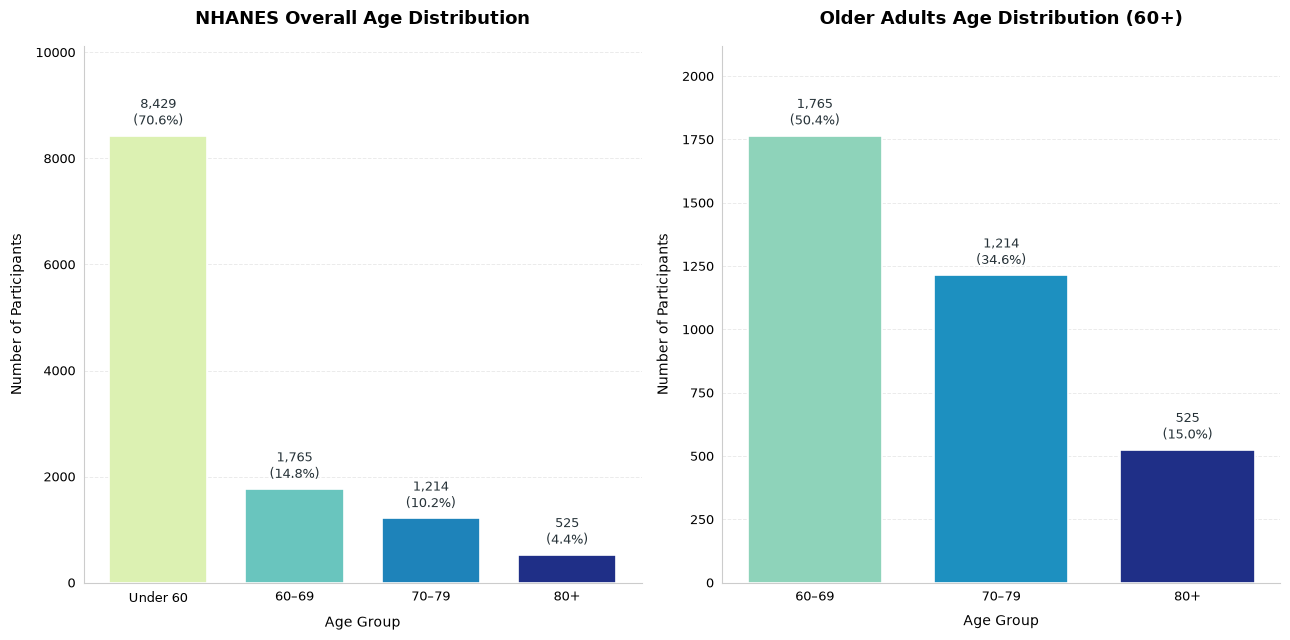

In [148]:
# Bar Charts: Age Distribution
# NHANES Overall vs Older Adults
bins = [-1, 59, 69, 79, 120]
labels = ["Under 60", "60–69", "70–79", "80+"]

overall_age = pd.cut(merged_clean_df["RIDAGEYR"], bins=bins, labels=labels)
older_age = pd.cut(older_adults_df["RIDAGEYR"], bins=bins, labels=labels)

overall_counts = overall_age.value_counts(sort=False).reindex(labels, fill_value=0)
older_counts = older_age.value_counts(sort=False).reindex(labels[1:], fill_value=0)
overall_pct = overall_counts / overall_age.notna().sum() * 100
older_pct = older_counts / older_age.notna().sum() * 100

overall_colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(overall_counts)))
older_colors = plt.cm.YlGnBu(np.linspace(0.35, 0.90, len(older_counts)))

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
plot_data = [
    (axes[0], overall_counts, overall_pct, overall_colors, "NHANES Overall Age Distribution"),
    (axes[1], older_counts, older_pct, older_colors, "Older Adults Age Distribution (60+)")]

for ax, counts, percentages, colors, title in plot_data:
    bars = ax.bar(counts.index.astype(str), counts.values, color=colors, edgecolor="white", linewidth=1.2, width=0.72)
    for bar, count, pct in zip(bars, counts.values, percentages.values):
        ax.annotate(f"{count:,}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontsize=9, color="#263238")
    ax.set_title(title, fontsize=13, fontweight="bold", loc="center", pad=16)
    ax.set_xlabel("Age Group", fontsize=10, labelpad=8)
    ax.set_ylabel("Number of Participants", fontsize=10, labelpad=8)
    ax.tick_params(axis="both", labelsize=9, length=0, pad=6)
    ax.set_ylim(0, counts.max() * 1.20 if counts.max() > 0 else 1)
    ax.set_axisbelow(True)
    ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
    ax.grid(axis="x", visible=False)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    for spine in ["left", "bottom"]:
        ax.spines[spine].set_color("#CCCCCC")

fig.tight_layout()
plt.show()

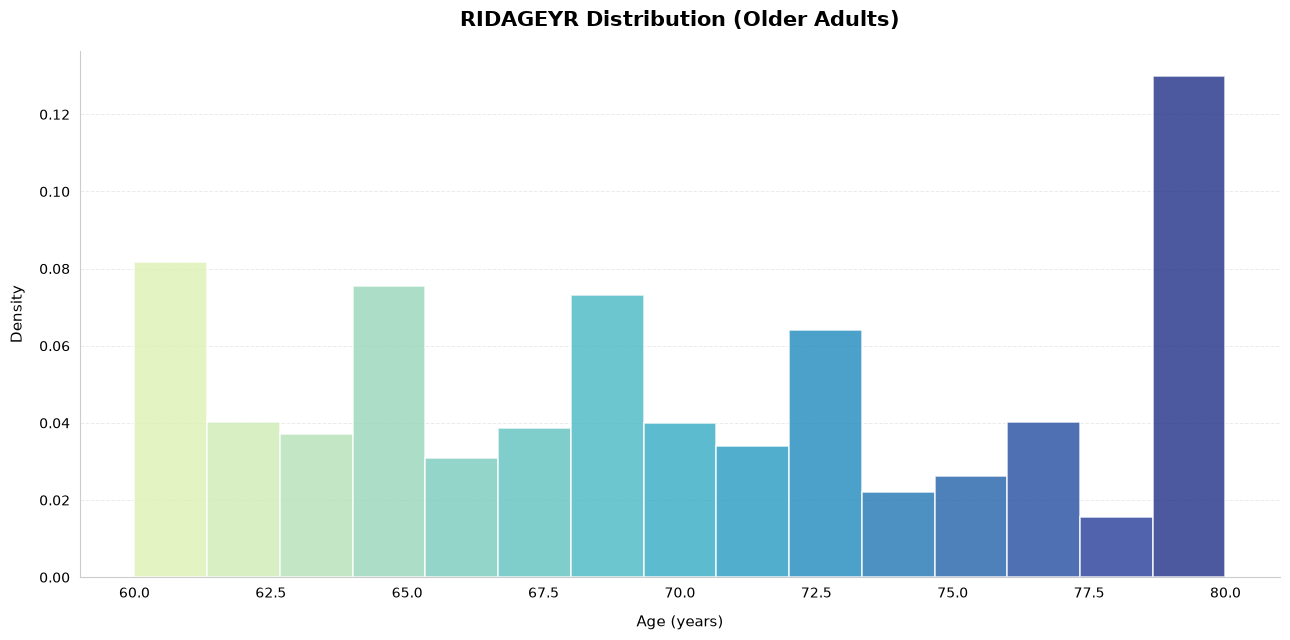

In [149]:
# Histogram: Age Distribution (Older Adults)
age = older_adults_df["RIDAGEYR"].dropna()
fig, ax = plt.subplots(figsize=(13, 6.5))
counts, bin_edges, patches = ax.hist(age, bins=15, density=True, alpha=0.8, edgecolor="white", linewidth=1.2)
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)
ax.set_title("RIDAGEYR Distribution (Older Adults)", fontsize=15, fontweight="bold", loc="center", pad=18)
ax.set_xlabel("Age (years)", fontsize=11, labelpad=10)
ax.set_ylabel("Density", fontsize=11, labelpad=10)
ax.tick_params(axis="both", labelsize=10, length=0, pad=7)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="x", visible=False)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")
fig.tight_layout()
plt.show()

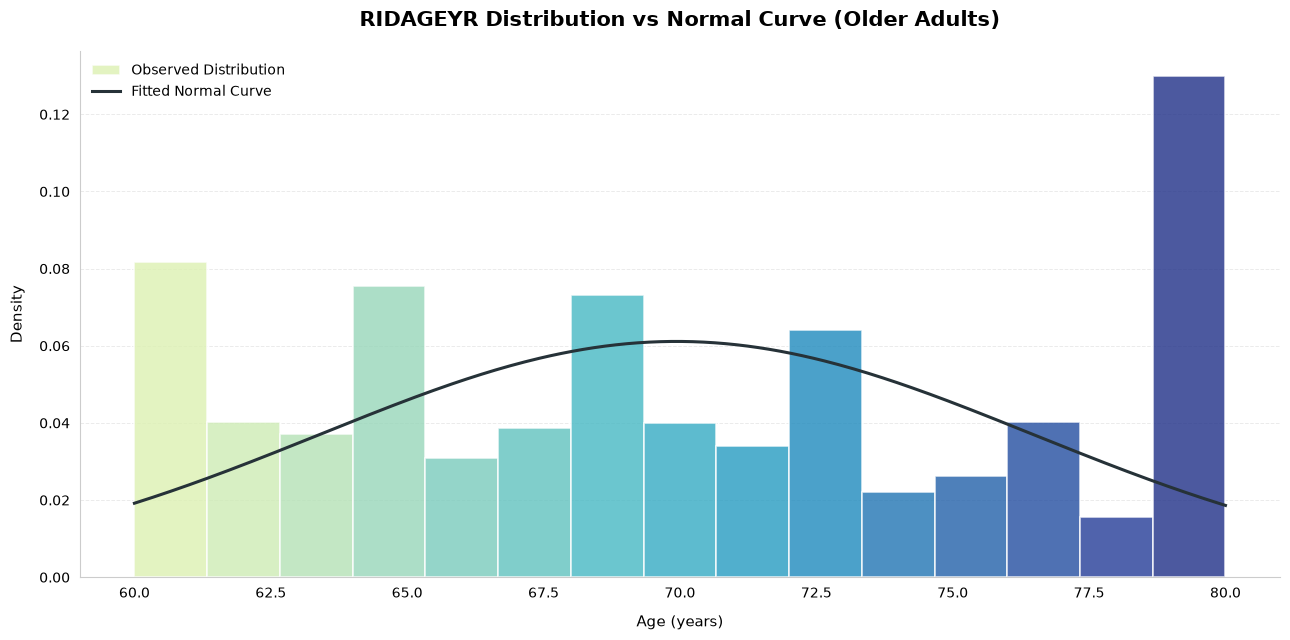

In [150]:
# Histogram: Age Distribution vs Fitted Normal Curve (Older Adults)
age = older_adults_df["RIDAGEYR"].dropna()
mean_age, std_age = age.mean(), age.std()
x = np.linspace(age.min(), age.max(), 300)
normal_curve = norm.pdf(x, mean_age, std_age)

fig, ax = plt.subplots(figsize=(13, 6.5))
counts, bin_edges, patches = ax.hist(age, bins=15, density=True, alpha=0.8, edgecolor="white", linewidth=1.2, label="Observed Distribution")

colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

ax.plot(x, normal_curve, color="#263238", linewidth=2.2, label="Fitted Normal Curve")
ax.set_title("RIDAGEYR Distribution vs Normal Curve (Older Adults)", fontsize=15, fontweight="bold", loc="center", pad=18)
ax.set_xlabel("Age (years)", fontsize=11, labelpad=10)
ax.set_ylabel("Density", fontsize=11, labelpad=10)
ax.tick_params(axis="both", labelsize=10, length=0, pad=7)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="x", visible=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

ax.legend(frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

In [151]:
age = older_adults_df["RIDAGEYR"].dropna()
print(f"Mean: {age.mean():.2f}")
print(f"Median: {age.median():.2f}")
print(f"SD: {age.std():.2f}")
print(f"Skewness: {age.skew():.3f}")

Mean: 69.94
Median: 69.00
SD: 6.53
Skewness: 0.173


#### 6.1.2 INDFMPIR: Ratio of family income to poverty

In [152]:
# Summarise income among older adults
income_summary = older_adults_df["INDFMPIR"].describe()
display(income_summary)

count    2902.000000
mean        2.965524
std         1.609807
min         0.000000
25%         1.510000
50%         2.870000
75%         4.920000
max         5.000000
Name: INDFMPIR, dtype: float64

In [153]:
# Descriptive statistics for INDFMPIR
income = older_adults_df["INDFMPIR"].dropna()
print(f"Mean:   {income.mean():.2f}")
print(f"Median: {income.median():.2f}")
print(f"SD: {income.std():.2f}")
print(f"Skewness: {income.skew():.3f}")
print(f"Minimum: {income.min():.2f}")
print(f"Maximum: {income.max():.2f}")

Mean:   2.97
Median: 2.87
SD: 1.61
Skewness: -0.037
Minimum: 0.00
Maximum: 5.00


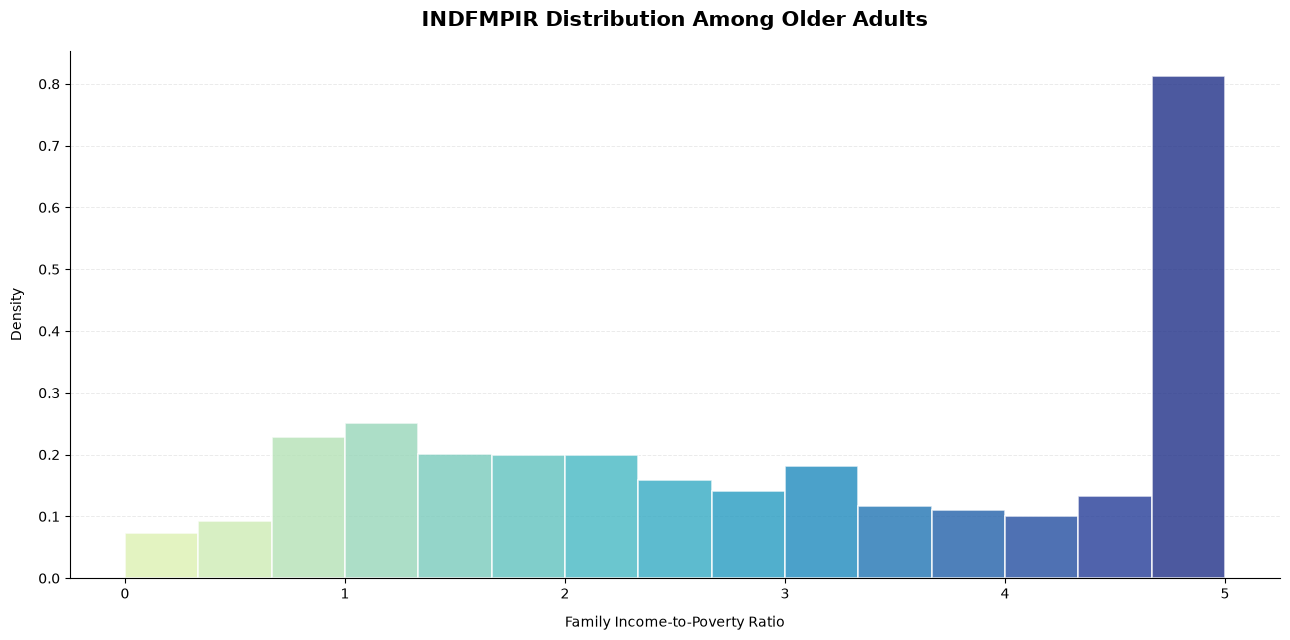

In [154]:
# Histogram: INDFMPIR Distribution Among Older Adults
fig, ax = plt.subplots(figsize=(13, 6.5))
counts, bins, patches = ax.hist(income, bins=15, density=True, alpha=0.8, edgecolor="white", linewidth=1.2)

# Apply YlGnBu colour gradient
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

# Chart title and labels
ax.set_title("INDFMPIR Distribution Among Older Adults", fontsize=15, fontweight="bold", pad=18)
ax.set_xlabel("Family Income-to-Poverty Ratio", labelpad=10)
ax.set_ylabel("Density", labelpad=10)

# Grid formatting
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="x", visible=False)

# Remove top and right borders
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

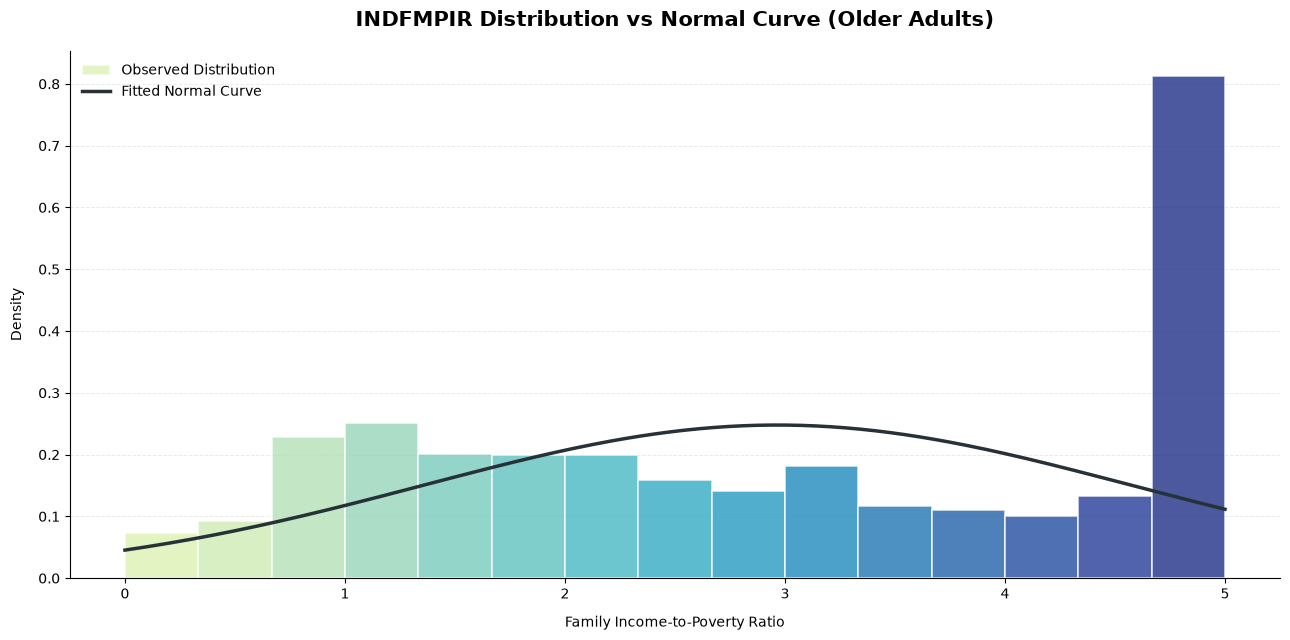

In [155]:
# Calculate mean and standard deviation
mean_income = income.mean()
std_income = income.std()
x = np.linspace(income.min(), income.max(), 300)
normal_curve = norm.pdf(x, mean_income, std_income)

# Plot histogram and fitted Normal curve
fig, ax = plt.subplots(figsize=(13, 6.5))
counts, bins, patches = ax.hist(income, bins=15, density=True, alpha=0.8, edgecolor="white", linewidth=1.2, label="Observed Distribution")
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)
ax.plot(x, normal_curve, color="#263238", linewidth=2.5, label="Fitted Normal Curve")
ax.set_title("INDFMPIR Distribution vs Normal Curve (Older Adults)", fontsize=15, fontweight="bold", pad=18)
ax.set_xlabel("Family Income-to-Poverty Ratio", labelpad=10)
ax.set_ylabel("Density", labelpad=10)
ax.legend(frameon=False)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

#### 6.1.3 PHQ-9: Depression Score

In [156]:
# Summarise PHQ-9 total scores
display(phq9_complete_df["PHQ9_Total"].describe().to_frame().round(2))

,PHQ9_Total
count,2394.00
mean,3.36
std,4.30
min,0.00
25%,0.00
50%,2.00
75%,5.00
max,26.00


In [157]:
# Descriptive statistics of PHQ-9 total scores
phq9_scores = phq9_complete_df["PHQ9_Total"].dropna()
print(f"Mean:      {phq9_scores.mean():.2f}")
print(f"Median:    {phq9_scores.median():.2f}")
print(f"SD:        {phq9_scores.std():.2f}")
print(f"Skewness:  {phq9_scores.skew():.3f}")
print(f"Minimum:   {phq9_scores.min():.2f}")
print(f"Maximum:   {phq9_scores.max():.2f}")

Mean:      3.36
Median:    2.00
SD:        4.30
Skewness:  1.994
Minimum:   0.00
Maximum:   26.00


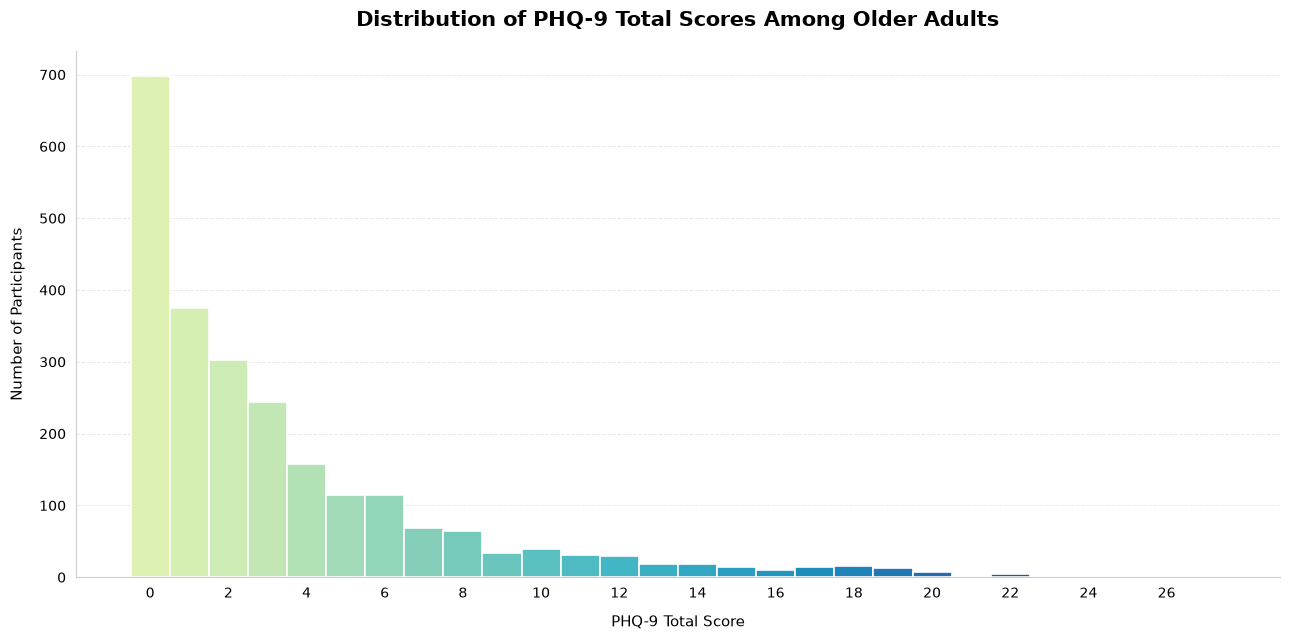

In [158]:
# Histogram: Distribution of PHQ-9 Total Scores Among Older Adults
fig, ax = plt.subplots(figsize=(13, 6.5))
counts, bin_edges, patches = ax.hist(phq9_complete_df["PHQ9_Total"], bins=np.arange(-0.5, 28.5, 1), edgecolor="white", linewidth=1.2)

colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

ax.set_title("Distribution of PHQ-9 Total Scores Among Older Adults", fontsize=15, fontweight="bold", loc="center", pad=18)
ax.set_xlabel("PHQ-9 Total Score", fontsize=11, labelpad=10)
ax.set_ylabel("Number of Participants", fontsize=11, labelpad=10)
ax.set_xticks(range(0, 28, 2))
ax.tick_params(axis="both", labelsize=10, length=0, pad=7)
ax.set_axisbelow(True)
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="x", visible=False)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#CCCCCC")

fig.tight_layout()
plt.show()

In [159]:
# Descriptive statistics and quartiles
variables = {
    "RIDAGEYR": older_adults_df["RIDAGEYR"],
    "INDFMPIR": older_adults_df["INDFMPIR"],
    "PHQ9_Total": phq9_complete_df["PHQ9_Total"]
}
summary = pd.DataFrame({name: series.dropna().describe(percentiles=[0.25, 0.50, 0.75]) for name, series in variables.items()}).T
summary = summary.rename(columns={
    "count": "N", "mean": "Mean", "std": "SD", "min": "Minimum", 
    "25%": "Q1 (25%)", "50%": "Median (Q2)", "75%": "Q3 (75%)", 
    "max": "Maximum"})
display(summary.round(2))

,N,Mean,SD,Minimum,Q1 (25%),Median (Q2),Q3 (75%),Maximum
RIDAGEYR,3504.0,69.94,6.53,60.0,64.00,69.00,75.00,80.0
INDFMPIR,2902.0,2.97,1.61,0.0,1.51,2.87,4.92,5.0
PHQ9_Total,2394.0,3.36,4.30,0.0,0.00,2.00,5.00,26.0


### 6.2 Summarise Categorical Variables

#### 6.2.1. Categorical Demographics Variables

In [160]:
# Summarise categorical variables Gender and Race
categorical_vars = ["RIAGENDR", "RIDRETH3"]
categorical_summary = []

for col in categorical_vars:
    counts = older_adults_df[col].value_counts(dropna=False).sort_index()
    percentages = counts / len(older_adults_df) * 100
    for category, count in counts.items():
        categorical_summary.append({
            "Variable": col,
            "Category_Code": "Missing" if pd.isna(category) else category,
            "Count": int(count),
            "Percentage (%)": round(percentages.loc[category], 2)})
categorical_summary_df = pd.DataFrame(categorical_summary)
display(categorical_summary_df.style.hide(axis="index"))

Variable,Category_Code,Count,Percentage (%)
RIAGENDR,1.000000,1589,45.350000
RIAGENDR,2.000000,1915,54.650000
RIDRETH3,1.000000,146,4.170000
RIDRETH3,2.000000,276,7.880000
RIDRETH3,3.000000,2343,66.870000
RIDRETH3,4.000000,376,10.730000
RIDRETH3,6.000000,157,4.480000
RIDRETH3,7.000000,206,5.880000


In [161]:
# Define NHANES category labels
gender_labels = {1: "Male", 2: "Female"}
race_labels = {
    1: "Mexican American",
    2: "Other Hispanic",
    3: "Non-Hispanic White",
    4: "Non-Hispanic Black",
    6: "Non-Hispanic Asian",
    7: "Other Race, Including Multi-Racial"
}

# Create labelled columns while preserving original codes
older_adults_df["Gender"] = older_adults_df["RIAGENDR"].map(gender_labels)
older_adults_df["Race_Ethnicity"] = older_adults_df["RIDRETH3"].map(race_labels)

In [162]:
# Check original codes and missing values
for col in ["RIAGENDR", "RIDRETH3"]:
    print(f"\n{col}")
    print("Unique values:", sorted(older_adults_df[col].dropna().unique()))
    print("Missing values:", older_adults_df[col].isna().sum())

# Check for unmapped codes
print("\nUnmapped Gender codes:", older_adults_df.loc[older_adults_df["RIAGENDR"].notna() & older_adults_df["Gender"].isna(), "RIAGENDR"].unique())
print("Unmapped Race/Ethnicity codes:", older_adults_df.loc[older_adults_df["RIDRETH3"].notna() & older_adults_df["Race_Ethnicity"].isna(), "RIDRETH3"].unique())


RIAGENDR
Unique values: [np.float64(1.0), np.float64(2.0)]
Missing values: 0

RIDRETH3
Unique values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(6.0), np.float64(7.0)]
Missing values: 0

Unmapped Gender codes: []
Unmapped Race/Ethnicity codes: []


In [163]:
# Define labelled categorical variables
categorical_vars = ["Gender", "Race_Ethnicity"]

# Generate count and percentage summary
categorical_summary = []
for col in categorical_vars:
    values = older_adults_df[col].fillna("Missing")
    counts = values.value_counts(dropna=False)
    percentages = values.value_counts(normalize=True, dropna=False) * 100

    for category, count in counts.items():
        categorical_summary.append({
            "Variable": col,
            "Category": category,
            "Count": count,
            "Percentage (%)": round(percentages[category], 2)})

categorical_summary_df = pd.DataFrame(categorical_summary)
display(categorical_summary_df.style.hide(axis="index"))

Variable,Category,Count,Percentage (%)
Gender,Female,1915,54.650000
Gender,Male,1589,45.350000
Race_Ethnicity,Non-Hispanic White,2343,66.870000
Race_Ethnicity,Non-Hispanic Black,376,10.730000
Race_Ethnicity,Other Hispanic,276,7.880000
Race_Ethnicity,"Other Race, Including Multi-Racial",206,5.880000
Race_Ethnicity,Non-Hispanic Asian,157,4.480000
Race_Ethnicity,Mexican American,146,4.170000


##### Population Pyramid: Age and Gender Distribution of NHANES Participants

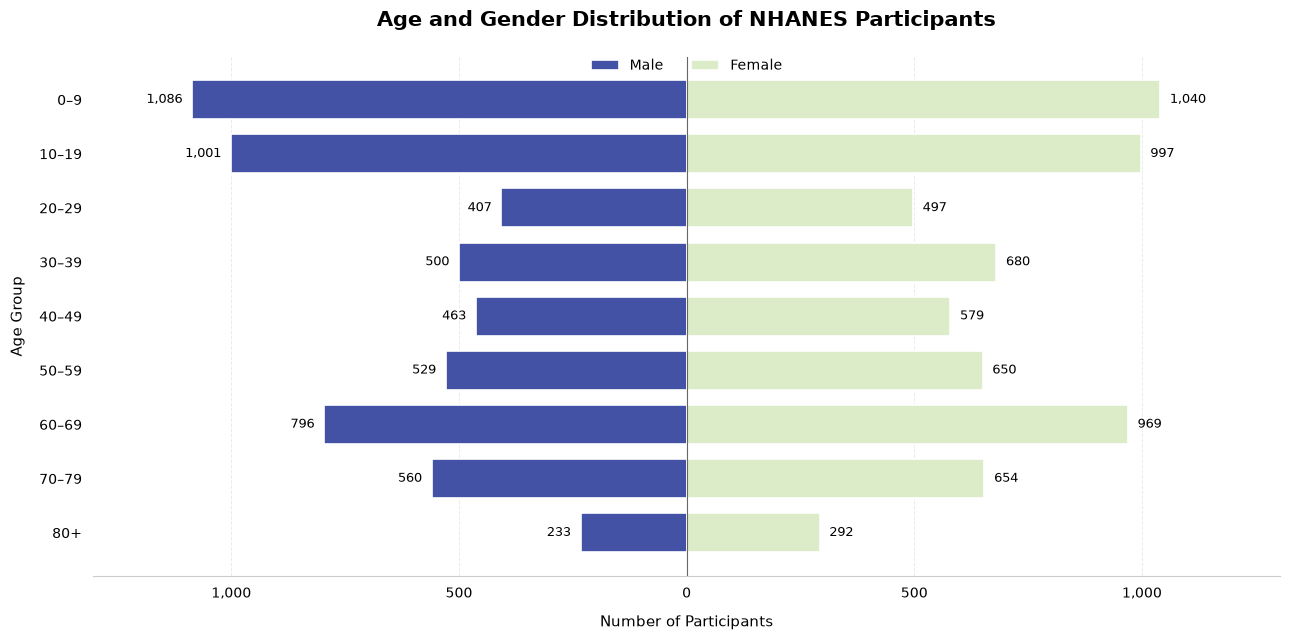

In [164]:
# Population Pyramid: Age and Gender Distribution of NHANES Participants

# Prepare age and gender counts
age_gender_counts = pd.crosstab(age_groups, demographic_df["Genders"]).reindex(age_groups.cat.categories, fill_value=0)
male, female = age_gender_counts["Male"].to_numpy(), age_gender_counts["Female"].to_numpy()
y = np.arange(len(age_gender_counts))

# Create figure
fig, ax = plt.subplots(figsize=(13, 6.5))
bar_height = 0.72
male_color, female_color = "#4352A5", "#DCECC9"

# Plot bars
ax.barh(y, -male, height=bar_height, color=male_color, edgecolor="white", linewidth=1.2, label="Male")
ax.barh(y, female, height=bar_height, color=female_color, edgecolor="white", linewidth=1.2, label="Female")

# Add count labels outside bars
for i, (m, f) in enumerate(zip(male, female)):
    ax.annotate(f"{m:,}", (-m, i), xytext=(-7, 0), textcoords="offset points", ha="right", va="center", fontsize=9)
    ax.annotate(f"{f:,}", (f, i), xytext=(7, 0), textcoords="offset points", ha="left", va="center", fontsize=9)

# Axis formatting
limit = max(male.max(), female.max()) * 1.20
ax.set_xlim(-limit, limit)
ax.set_yticks(y)
ax.set_yticklabels(age_gender_counts.index.astype(str))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{abs(int(x)):,}"))

# Title and labels
ax.set_title("Age and Gender Distribution of NHANES Participants", fontsize=15, fontweight="bold", pad=22)
ax.set_xlabel("Number of Participants", fontsize=11, labelpad=10)
ax.set_ylabel("Age Group", fontsize=11, labelpad=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=10)

# Centre line and grid
ax.axvline(0, color="#666666", linewidth=0.8)
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.25)
ax.set_axisbelow(True)

# Clean spines and ticks
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")
ax.tick_params(axis="both", labelsize=10, length=0, pad=8)

fig.tight_layout()
plt.show()

In [165]:
# Prepare age groups for older adults
age_bins = [59, 69, 79, 120]
age_labels = ["60–69", "70–79", "80+"]
older_adults_df["Age_Group"] = pd.cut(
    older_adults_df["RIDAGEYR"],
    bins=age_bins,
    labels=age_labels,
    right=True,
    include_lowest=True
)

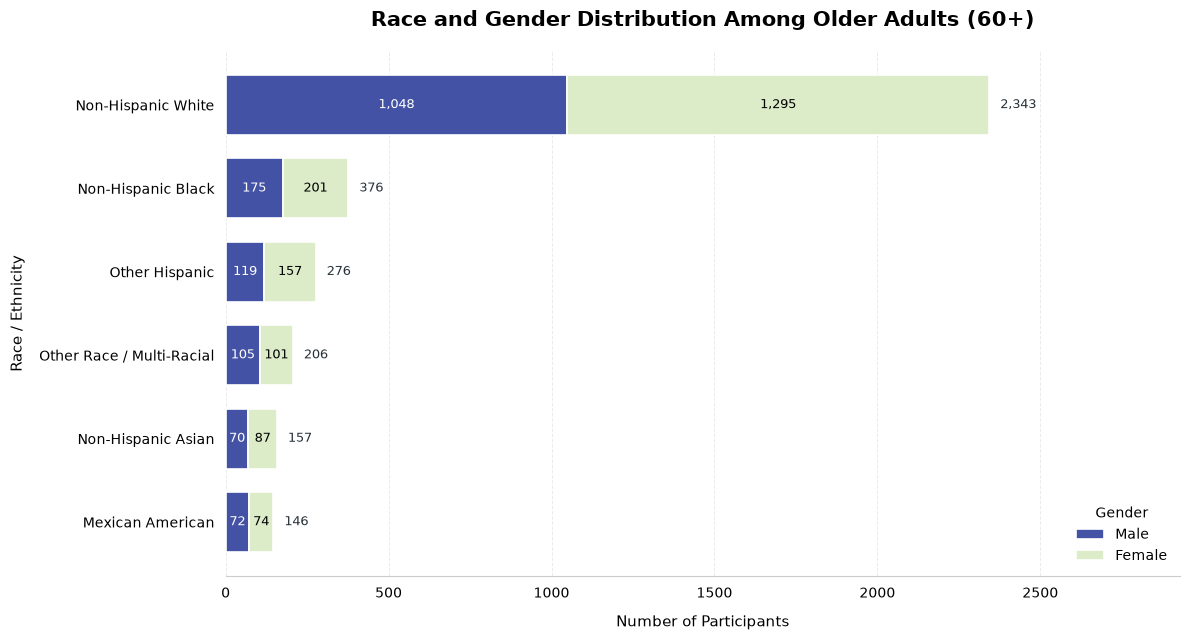

In [166]:
# Horizontal Stacked Bar Chart: Race and Gender Distribution Among Older Adults (60+)

# Define category labels
race_labels = {1: "Mexican American", 2: "Other Hispanic", 3: "Non-Hispanic White", 4: "Non-Hispanic Black", 6: "Non-Hispanic Asian", 7: "Other Race / Multi-Racial"}

# Create labelled race column
race_gender_df = older_adults_df.copy()
race_gender_df["Race_Ethnicity"] = race_gender_df["RIDRETH3"].map(race_labels)

# Count race by gender
race_gender = pd.crosstab(race_gender_df["Race_Ethnicity"], race_gender_df["RIAGENDR"]).rename(columns={1: "Male", 2: "Female"})
race_gender = race_gender.reindex(list(race_labels.values()), fill_value=0)

# Sort by total count: lowest to highest
race_gender["Total"] = race_gender.sum(axis=1)
race_gender = race_gender.sort_values("Total", ascending=True)

# Calculate gender totals
male_total = race_gender["Male"].sum()
female_total = race_gender["Female"].sum()
grand_total = race_gender["Total"].sum()

# Create figure
fig, ax = plt.subplots(figsize=(12, 6.5))
male_color, female_color = "#4352A5", "#DCECC9"

# Plot horizontal stacked bars
ax.barh(race_gender.index, race_gender["Male"], color=male_color, edgecolor="white", linewidth=1.2, height=0.72, label="Male")
ax.barh(race_gender.index, race_gender["Female"], left=race_gender["Male"], color=female_color, edgecolor="white", linewidth=1.2, height=0.72, label="Female")

# Add Male and Female count labels
for i, (male, female) in enumerate(zip(race_gender["Male"], race_gender["Female"])):
    if male > 0:
        ax.text(male / 2, i, f"{male:,}", ha="center", va="center", fontsize=9, color="white")
    if female > 0:
        ax.text(male + female / 2, i, f"{female:,}", ha="center", va="center", fontsize=9, color="black")

# Add total labels
for i, total in enumerate(race_gender["Total"]):
    ax.annotate(f"{total:,}", (total, i), xytext=(8, 0), textcoords="offset points", ha="left", va="center", fontsize=9, color="#263238")

# Axis formatting
ax.set_xlim(0, race_gender["Total"].max() * 1.25)
ax.set_title("Race and Gender Distribution Among Older Adults (60+)", fontsize=15, fontweight="bold", loc="center", pad=18)
ax.set_xlabel("Number of Participants", fontsize=11, labelpad=10)
ax.set_ylabel("Race / Ethnicity", fontsize=11, labelpad=10)

# Legend
ax.legend(title="Gender", frameon=False, loc="lower right")

# Grid and spines
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="y", visible=False)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")
ax.tick_params(axis="both", labelsize=10, length=0, pad=8)

fig.tight_layout()
plt.show()

#### 6.2.2 Categorical Health Variables

In [167]:
# Define selected categorical health variables
health_categorical_vars = [
    "MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D",
    "MCQ160E", "MCQ160F", "MCQ160P", "MCQ220",
    "PAD790U", "PAD810U", "ALQ111", "ALQ121", "ALQ151"
]

# Check available variables once
available_vars = [
    col for col in health_categorical_vars
    if col in older_adults_df.columns
]
missing_vars = [
    col for col in health_categorical_vars
    if col not in older_adults_df.columns
]

print("Available variables:", available_vars)
print("Variables not found:", missing_vars)

if missing_vars:
    raise ValueError(f"Selected categorical variables not found: {missing_vars}")


Available variables: ['MCQ160A', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ160P', 'MCQ220', 'PAD790U', 'PAD810U', 'ALQ111', 'ALQ121', 'ALQ151']
Variables not found: []


In [168]:
# Define NHANES category labels
# Medical conditions: MCQ_L
yes_no_labels = {1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"}
# Physical activity frequency units: PAQ_L
activity_unit_labels = {"b'D'": "Day", "b'W'": "Week", "b'M'": "Month", "b'Y'": "Year", "b''": "Missing / Blank response"}
# Alcohol consumption: ALQ_L
alcohol_frequency_labels = {
    0: "Never in the past 12 months", 1: "Every day", 
    2: "Nearly every day", 3: "3–4 times per week", 
    4: "2 times per week", 5: "Once per week", 
    6: "2–3 times per month", 7: "Once per month", 
    8: "7–11 times in the past year", 9: "3–6 times in the past year", 
    10: "1–2 times in the past year", 77: "Refused", 99: "Don't know"}
# Define variable groups consistently for checks, labels, summaries, and graphs
mcq_vars = ["MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F", "MCQ160P", "MCQ220"]
paq_vars = ["PAD790U", "PAD810U"]
alq_yes_no_vars = ["ALQ111", "ALQ151"]
alq_frequency_vars = ["ALQ121"]

In [169]:
# Labels are applied together in the next cell

In [170]:
# Apply labels while preserving original variables
for col in mcq_vars + alq_yes_no_vars:
    older_adults_df[f"{col}_Label"] = older_adults_df[col].map(yes_no_labels).fillna("Missing / Unrecognised")
for col in paq_vars:
    older_adults_df[f"{col}_Label"] = older_adults_df[col].map(activity_unit_labels).fillna("Missing / Unrecognised")
for col in alq_frequency_vars:
    older_adults_df[f"{col}_Label"] = older_adults_df[col].map(alcohol_frequency_labels).fillna("Missing / Unrecognised")

In [171]:
# Consolidated categorical-variable quality summary
# Classify only questionnaire skips that can be identified from the documented routing.
def is_blank_unit(series):
    text = series.astype("string").str.strip()
    return series.isna() | text.isin(["", "b''", "''"])

quality_rows = []
n_total = len(older_adults_df)

# Medical-condition variables: valid Yes/No, special responses, missing, and unexpected values.
for col in mcq_vars:
    raw = older_adults_df[col]
    quality_rows.append({"Variable": col, "Valid_n": int(raw.isin([1, 2]).sum()), "Refused_n": int(raw.eq(7).sum()), "Dont_know_n": int(raw.eq(9).sum()), "Structural_missing_n": 0, "Actual_missing_n": int(raw.isna().sum()), "Blank_unresolved_n": 0, "Unexpected_code_n": int((raw.notna() & ~raw.isin([1, 2, 7, 9])).sum())})

# Physical activity unit variables: blank unit is structural when reported frequency = 0.
for unit_col, freq_col in [("PAD790U", "PAD790Q"), ("PAD810U", "PAD810Q")]:
    raw = older_adults_df[unit_col]
    freq = older_adults_df[freq_col]
    blank = is_blank_unit(raw)
    blank_text = raw.astype("string").str.strip().isin(["", "b''", "''"])
    structural = blank & freq.eq(0)
    actual_missing = raw.isna() & ~structural
    unresolved_blank = blank_text & ~freq.eq(0)
    valid_units = raw.astype("string").str.strip().isin(["b'D'", "b'W'", "b'M'", "b'Y'", "D", "W", "M", "Y"])
    quality_rows.append({"Variable": unit_col, "Valid_n": int(valid_units.sum()), "Refused_n": 0, "Dont_know_n": 0, "Structural_missing_n": int(structural.sum()), "Actual_missing_n": int(actual_missing.sum()), "Blank_unresolved_n": int(unresolved_blank.sum()), "Unexpected_code_n": int((~blank & ~valid_units).sum())})

# ALQ111: lifetime alcohol-use screener.
alq111 = older_adults_df["ALQ111"]
quality_rows.append({"Variable": "ALQ111", "Valid_n": int(alq111.isin([1, 2]).sum()), "Refused_n": int(alq111.eq(7).sum()), "Dont_know_n": int(alq111.eq(9).sum()), "Structural_missing_n": 0, "Actual_missing_n": int(alq111.isna().sum()), "Blank_unresolved_n": 0, "Unexpected_code_n": int((alq111.notna() & ~alq111.isin([1, 2, 7, 9])).sum())})

# ALQ121: missing is structural for lifetime abstainers (ALQ111 = No).
alq121 = older_adults_df["ALQ121"]
alq111 = older_adults_df["ALQ111"]
alq121_missing = alq121.isna()
alq121_structural = alq121_missing & alq111.eq(2)
alq121_actual = alq121_missing & alq111.eq(1)
alq121_unresolved = alq121_missing & ~alq111.isin([1, 2])
quality_rows.append({"Variable": "ALQ121", "Valid_n": int(alq121.between(0, 10).sum()), "Refused_n": int(alq121.eq(77).sum()), "Dont_know_n": int(alq121.eq(99).sum()), "Structural_missing_n": int(alq121_structural.sum()), "Actual_missing_n": int(alq121_actual.sum()), "Blank_unresolved_n": int(alq121_unresolved.sum()), "Unexpected_code_n": int((alq121.notna() & ~alq121.isin(list(range(0, 11)) + [77, 99])).sum())})

# ALQ151: retain blank records as unresolved until the complete questionnaire route is verified.
alq151 = older_adults_df["ALQ151"]
quality_rows.append({"Variable": "ALQ151", "Valid_n": int(alq151.isin([1, 2]).sum()), "Refused_n": int(alq151.eq(7).sum()), "Dont_know_n": int(alq151.eq(9).sum()), "Structural_missing_n": 0, "Actual_missing_n": 0, "Blank_unresolved_n": int(alq151.isna().sum()), "Unexpected_code_n": int((alq151.notna() & ~alq151.isin([1, 2, 7, 9])).sum())})

categorical_quality_summary = pd.DataFrame(quality_rows)
categorical_quality_summary["Total_n"] = n_total
categorical_quality_summary["Valid_Percentage (%)"] = (categorical_quality_summary["Valid_n"] / n_total * 100).round(2)
categorical_quality_summary["Missing_or_Unresolved_n"] = categorical_quality_summary["Structural_missing_n"] + categorical_quality_summary["Actual_missing_n"] + categorical_quality_summary["Blank_unresolved_n"]
display(categorical_quality_summary.style.hide(axis="index"))

# Targeted ALQ skip-pattern checks (no full-dataset recheck).
print("ALQ121 missingness by ALQ111 lifetime alcohol response:")
alq121_skip_check = pd.DataFrame({"ALQ111": alq111.map({1: "Yes", 2: "No", 7: "Refused", 9: "Don't know"}).fillna("Missing"), "ALQ121_Status": np.where(alq121.isna(), "Missing", "Answered")})
display(alq121_skip_check.groupby(["ALQ111", "ALQ121_Status"], dropna=False).size().unstack(fill_value=0))

print("ALQ151 missingness by ALQ121 response (diagnostic only; do not infer structural missing from ALQ121 alone):")
alq151_skip_check = pd.DataFrame({"ALQ121_Response": alq121.map(alcohol_frequency_labels).fillna("Missing / Unrecognised"), "ALQ151_Status": np.where(alq151.isna(), "Missing", "Answered")})
display(alq151_skip_check.groupby(["ALQ121_Response", "ALQ151_Status"], dropna=False).size().unstack(fill_value=0))

Variable,Valid_n,Refused_n,Dont_know_n,Structural_missing_n,Actual_missing_n,Blank_unresolved_n,Unexpected_code_n,Total_n,Valid_Percentage (%),Missing_or_Unresolved_n
MCQ160A,3492,0,12,0,0,0,0,3504,99.660000,0
MCQ160B,3489,0,15,0,0,0,0,3504,99.570000,0
MCQ160C,3478,0,25,0,1,0,0,3504,99.260000,1
MCQ160D,3485,0,19,0,0,0,0,3504,99.460000,0
MCQ160E,3493,0,11,0,0,0,0,3504,99.690000,0
MCQ160F,3488,0,15,0,1,0,0,3504,99.540000,1
MCQ160P,3494,0,9,0,1,0,0,3504,99.710000,1
MCQ220,3498,1,4,0,1,0,0,3504,99.830000,1
PAD790U,2559,0,0,919,0,26,0,3504,73.030000,945
PAD810U,1116,0,0,2365,0,23,0,3504,31.850000,2388


ALQ121 missingness by ALQ111 lifetime alcohol response:


ALQ121_Status,Answered,Missing
ALQ111,,
Don't know,4,0
Missing,0,1089
No,0,251
Yes,2160,0


ALQ151 missingness by ALQ121 response (diagnostic only; do not infer structural missing from ALQ121 alone):


ALQ151_Status,Answered,Missing
ALQ121_Response,,
1–2 times in the past year,222,1
2 times per week,174,2
2–3 times per month,186,0
3–4 times per week,206,0
3–6 times in the past year,214,1
7–11 times in the past year,97,0
Don't know,3,0
Every day,106,1
Missing / Unrecognised,0,1340


In [172]:
# Define labelled variable groups
mcq_label_vars = [f"{col}_Label" for col in mcq_vars]
paq_label_vars = [f"{col}_Label" for col in paq_vars]
alq_yes_no_label_vars = [f"{col}_Label" for col in alq_yes_no_vars]
alq_frequency_label_vars = [f"{col}_Label" for col in alq_frequency_vars]

# Check available labelled variables
all_labelled_vars = (
    mcq_label_vars + paq_label_vars +
    alq_yes_no_label_vars + alq_frequency_label_vars)

available_labelled_vars = [
    col for col in all_labelled_vars
    if col in older_adults_df.columns]

print("Available labelled variables:", available_labelled_vars)

Available labelled variables: ['MCQ160A_Label', 'MCQ160B_Label', 'MCQ160C_Label', 'MCQ160D_Label', 'MCQ160E_Label', 'MCQ160F_Label', 'MCQ160P_Label', 'MCQ220_Label', 'PAD790U_Label', 'PAD810U_Label', 'ALQ111_Label', 'ALQ151_Label', 'ALQ121_Label']


##### Graph: Medical Conditions

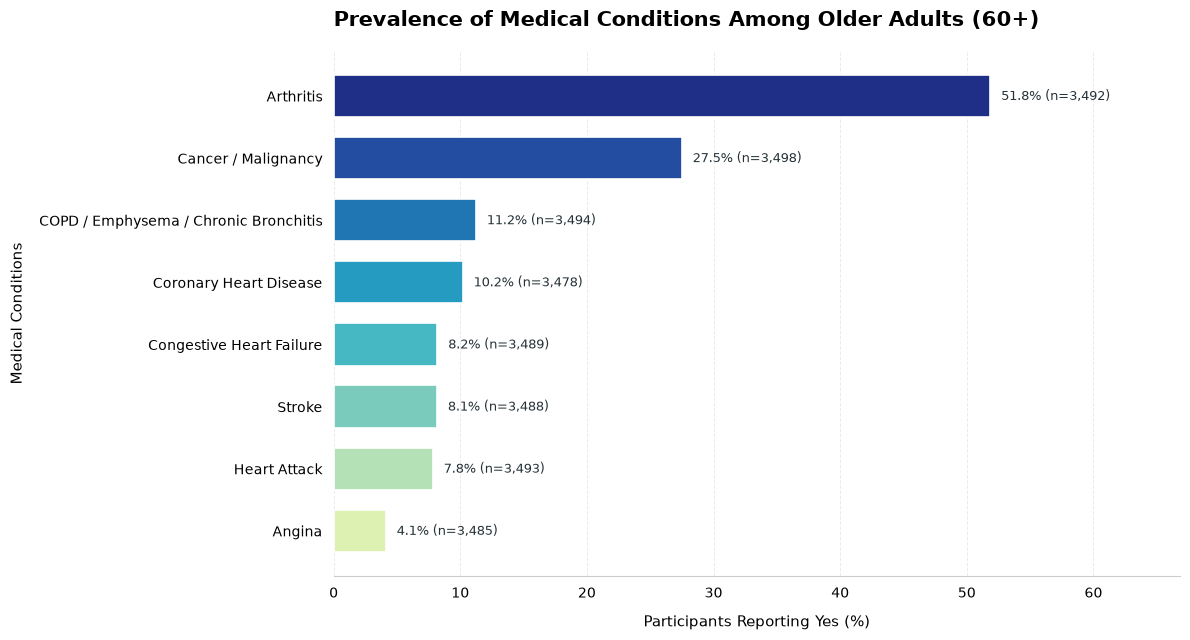

In [173]:
# Graph 1: Medical Conditions — Percentage and Sample Size
medical_condition_labels = {"MCQ160A": "Arthritis", "MCQ160B": "Congestive Heart Failure", "MCQ160C": "Coronary Heart Disease", "MCQ160D": "Angina", "MCQ160E": "Heart Attack", "MCQ160F": "Stroke", "MCQ160P": "COPD / Emphysema / Chronic Bronchitis", "MCQ220": "Cancer / Malignancy"}
# Calculate Yes percentage using valid Yes/No responses only.
medical_summary = []
for col in mcq_vars:
    labels = older_adults_df[f"{col}_Label"]
    yes_count = int(labels.eq("Yes").sum())
    no_count = int(labels.eq("No").sum())
    valid_n = yes_count + no_count
    yes_percentage = yes_count / valid_n * 100 if valid_n else 0
    medical_summary.append({"Medical Condition": medical_condition_labels[col], "Yes_Count": yes_count, "Valid_n": valid_n, "Yes_Percentage": yes_percentage})
medical_summary_df = pd.DataFrame(medical_summary).sort_values("Yes_Percentage", ascending=True)
# Create figure
fig, ax = plt.subplots(figsize=(12, 6.5))
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(medical_summary_df)))
bars = ax.barh(medical_summary_df["Medical Condition"], medical_summary_df["Yes_Percentage"], color=colors, edgecolor="white", linewidth=1.2, height=0.68)
# Add percentage and valid sample-size labels
for bar, percentage, n in zip(bars, medical_summary_df["Yes_Percentage"], medical_summary_df["Valid_n"]):
    ax.annotate(f"{percentage:.1f}% (n={n:,})", xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(8, 0), textcoords="offset points", ha="left", va="center", fontsize=9, color="#263238")
ax.set_title("Prevalence of Medical Conditions Among Older Adults (60+)", fontsize=15, fontweight="bold", loc="left", pad=18)
ax.set_xlabel("Participants Reporting Yes (%)", fontsize=11, labelpad=10)
ax.set_ylabel("Medical Conditions", fontsize=11, labelpad=10)
ax.set_xlim(0, medical_summary_df["Yes_Percentage"].max() + 15)
ax.tick_params(axis="both", labelsize=10, length=0, pad=8)
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="y", visible=False)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")
fig.tight_layout()
plt.show()

##### Physical Activity

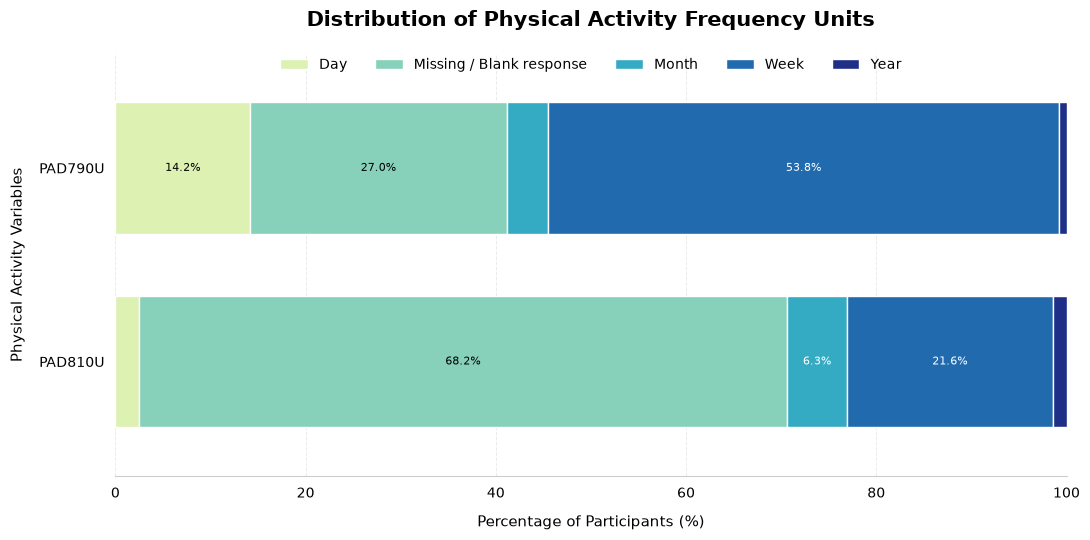

In [174]:
# Horizontal Stacked Bar Chart: Physical Activity Frequency Units

# Calculate percentage distribution
paq_summary = pd.DataFrame({col: older_adults_df[col].value_counts(normalize=True, dropna=False) * 100 for col in paq_label_vars if col in older_adults_df.columns}).T.fillna(0)

# Remove suffix from variable names
paq_summary.index = paq_summary.index.str.replace("_Label", "", regex=False)

# Create figure
fig, ax = plt.subplots(figsize=(11, 5.5))
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(paq_summary.columns)))

# Plot horizontal stacked bars
paq_summary.plot(kind="barh", stacked=True, ax=ax, color=colors, edgecolor="white", linewidth=1.0, width=0.68)

# Add percentage labels inside segments
for i, container in enumerate(ax.containers):
    label_color = "black" if i < 2 else "white"
    labels = [f"{bar.get_width():.1f}%" if bar.get_width() >= 5 else "" for bar in container]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8, color=label_color)

# Title and labels
ax.set_title("Distribution of Physical Activity Frequency Units", fontsize=15, fontweight="bold", loc="center", pad=20)
ax.set_xlabel("Percentage of Participants (%)", fontsize=11, labelpad=10)
ax.set_ylabel("Physical Activity Variables", fontsize=11, labelpad=10)

# Axis formatting
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.tick_params(axis="both", labelsize=10, length=0, pad=8)

# Legend
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.02), ncol=5, frameon=False, fontsize=10)

# Grid and spines
ax.set_axisbelow(True)
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.25)
ax.grid(axis="y", visible=False)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

fig.tight_layout()
plt.show()

##### Alcohol Consumption

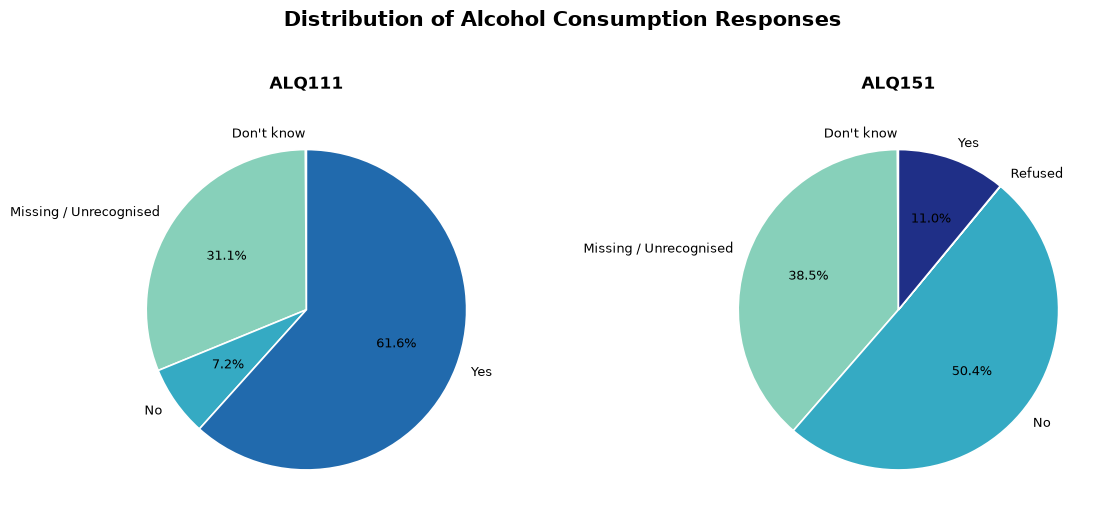

In [175]:
# Calculate percentage distribution
alq_binary_summary = pd.DataFrame({col: older_adults_df[col].value_counts(normalize=True, dropna=False) * 100 for col in alq_yes_no_label_vars if col in older_adults_df.columns}).T.fillna(0)
# Remove suffix from variable names
alq_binary_summary.index = alq_binary_summary.index.str.replace("_Label", "", regex=False)
# Define colour palette
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, alq_binary_summary.shape[1]))
# Create pie charts
fig, axes = plt.subplots(1, len(alq_binary_summary), figsize=(6 * len(alq_binary_summary), 5))
if len(alq_binary_summary) == 1:
    axes = [axes]
for ax, (variable, values) in zip(axes, alq_binary_summary.iterrows()):
    values = values[values > 0]
    ax.pie(values, labels=values.index, autopct=lambda p: f"{p:.1f}%" if p >= 5 else "", startangle=90, colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 1.2}, textprops={"fontsize": 9})
    ax.set_title(variable, fontweight="bold", fontsize=12, pad=15)
fig.suptitle("Distribution of Alcohol Consumption Responses", fontsize=15, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

##### Alcohol Frequency

ALQ121_Label
Refused                         0.03
Don't know                      0.09
7–11 times in the past year     2.77
Every day                       3.05
Once per month                  3.54
Once per week                   3.88
Nearly every day                4.74
2 times per week                5.02
2–3 times per month             5.31
3–4 times per week              5.88
3–6 times in the past year      6.14
1–2 times in the past year      6.36
Never in the past 12 months    14.95
Missing / Unrecognised         38.24
Name: proportion, dtype: float64


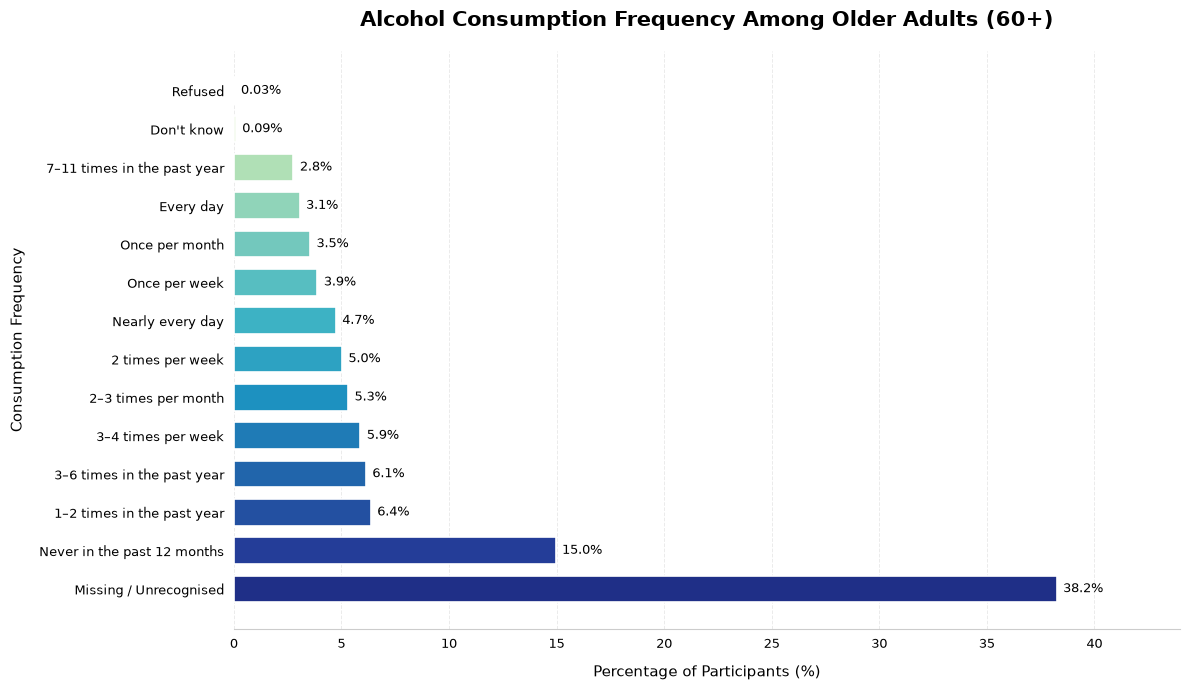

In [176]:
# Calculate alcohol frequency distribution
alq_frequency_summary = older_adults_df["ALQ121_Label"].value_counts(normalize=True) * 100
# Define logical category order
frequency_order = ["Never in the past 12 months", "Every day", "Nearly every day", "3–4 times per week", "2 times per week", "Once per week", "2–3 times per month", "Once per month", "7–11 times in the past year", "3–6 times in the past year", "1–2 times in the past year", "Refused", "Don't know", "Missing / Unrecognised"]
# Reorder and sort categories by frequency (lowest to highest)
alq_frequency_summary = alq_frequency_summary.reindex(frequency_order, fill_value=0).sort_values(ascending=True)
# Verify frequency distribution
print(alq_frequency_summary.round(2))
# Define gradient colours
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(alq_frequency_summary)))
# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(alq_frequency_summary.index, alq_frequency_summary.values, color=colors, edgecolor="white", linewidth=1.2, height=0.7)
# Add percentage labels
for bar, value in zip(bars, alq_frequency_summary.values):
    label = f"{value:.2f}%" if value < 1 else f"{value:.1f}%"
    ax.text(value + 0.3, bar.get_y() + bar.get_height() / 2, label, va="center", fontsize=9)
# Chart title and labels
ax.set_title("Alcohol Consumption Frequency Among Older Adults (60+)", fontsize=15, fontweight="bold", pad=18)
ax.set_xlabel("Percentage of Participants (%)", fontsize=11, labelpad=10)
ax.set_ylabel("Consumption Frequency", fontsize=11, labelpad=10)
# Axis formatting
ax.set_xlim(0, alq_frequency_summary.max() * 1.15)
ax.tick_params(axis="both", labelsize=9, length=0, pad=7)
ax.invert_yaxis()
# Grid and spines
ax.grid(axis="x", linestyle="--", linewidth=0.7, alpha=0.25)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")
plt.tight_layout()
plt.show()

### 6.3 Binomial Distribution

In [177]:
# Define binary depression status
phq9_complete_df["Depression_Status"] = (
    phq9_complete_df["PHQ9_Total"] >= 10
).astype(int)

# Summarise depression status
status_summary = (
    phq9_complete_df["Depression_Status"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Below threshold", 1: "PHQ-9 >= 10"})
    .to_frame("Count")
)

status_summary["Percentage (%)"] = (
    status_summary["Count"] /
    len(phq9_complete_df) * 100
).round(2)

display(status_summary)

,Count,Percentage (%)
Depression_Status,,
Below threshold,2171,90.69
PHQ-9 >= 10,223,9.31


#### Model definition

Let (X = 100 ) be the number of older adults with a PHQ-9 score of 10 or above in a random sample of 100 older adults with complete PHQ-9 responses.

A Binomial model is appropriate for this illustrative count because each sampled person has two possible outcomes (below threshold / PHQ-9 ≥ 10), the sample size is fixed at 100, and the probability is estimated from the complete-case dataset. The threshold indicates possible moderate-or-higher depressive symptoms for screening purposes; it is not a clinical diagnosis.

X ~ Binomial(n = 100,p = ^{p})

The model assumes independent observations and a constant probability. These assumptions are an approximation: NHANES uses a complex survey design, and the estimated sample proportion is not a design-adjusted population estimate.

In [178]:
# Estimate the probability from complete PHQ-9 cases
phq9_n = len(phq9_complete_df)
depression_cases = int(phq9_complete_df["PHQ9_Total"].ge(10).sum())
p_hat = depression_cases / phq9_n

# Define the illustrative Binomial model
n_trials = 100
binomial_mean = n_trials * p_hat
binomial_variance = n_trials * p_hat * (1 - p_hat)
binomial_sd = np.sqrt(binomial_variance)

print(f"Complete PHQ-9 cases: {phq9_n:,}")
print(f"PHQ-9 >= 10 cases: {depression_cases:,}")
print(f"Estimated probability (p): {p_hat:.4f} ({p_hat * 100:.2f}%)")
print(f"Model: X ~ Binomial(n={n_trials}, p={p_hat:.4f})")
print(f"Expected number, E(X): {binomial_mean:.2f}")
print(f"Variance, Var(X): {binomial_variance:.2f}")
print(f"Standard deviation: {binomial_sd:.2f}")

# Calculate selected probabilities
binomial_probabilities = pd.DataFrame({
    "Event": ["P(X = 0)", "P(X <= 5)", "P(5 <= X <= 15)", "P(X >= 15)"],
    "Probability": [
        binom.pmf(0, n_trials, p_hat),
        binom.cdf(5, n_trials, p_hat),
        binom.cdf(15, n_trials, p_hat) - binom.cdf(4, n_trials, p_hat),
        binom.sf(14, n_trials, p_hat)]})

binomial_probabilities["Percentage (%)"] = (binomial_probabilities["Probability"] * 100).round(2)
display(binomial_probabilities.round(4))

Complete PHQ-9 cases: 2,394
PHQ-9 >= 10 cases: 223
Estimated probability (p): 0.0931 (9.31%)
Model: X ~ Binomial(n=100, p=0.0931)
Expected number, E(X): 9.31
Variance, Var(X): 8.45
Standard deviation: 2.91


,Event,Probability,Percentage (%)
0,P(X = 0),0.0001,0.01
1,P(X <= 5),0.0871,8.71
2,P(5 <= X <= 15),0.9391,93.91
3,P(X >= 15),0.0440,4.40


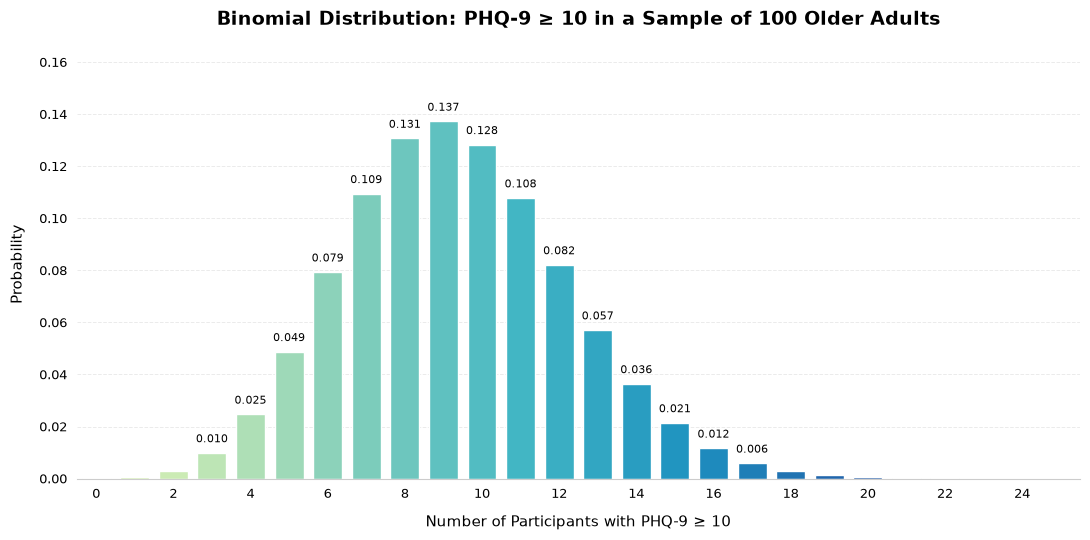

In [179]:
# Plot the Binomial probability mass function
x_binomial = np.arange(0, 26)
pmf_binomial = binom.pmf(x_binomial, n_trials, p_hat)
# Define gradient colours
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(x_binomial)))
# Create bar chart
fig, ax = plt.subplots(figsize=(11, 5.5))
bars = ax.bar(x_binomial, pmf_binomial, width=0.75, color=colors, edgecolor="white", linewidth=1.0)
# Add probability labels
for bar, value in zip(bars, pmf_binomial):
    if value >= 0.005:
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.003, f"{value:.3f}", ha="center", va="bottom", fontsize=8)
# Chart title and labels
ax.set_title("Binomial Distribution: PHQ-9 ≥ 10 in a Sample of 100 Older Adults", fontsize=14, fontweight="bold", pad=18)
ax.set_xlabel("Number of Participants with PHQ-9 ≥ 10", fontsize=11, labelpad=10)
ax.set_ylabel("Probability", fontsize=11, labelpad=10)
# Axis formatting
ax.set_xticks(np.arange(0, 26, 2))
ax.tick_params(axis="both", labelsize=9, length=0, pad=7)
ax.set_xlim(-0.5, 25.5)
ax.set_ylim(0, pmf_binomial.max() * 1.2)
# Grid and spines
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")
plt.tight_layout()
plt.show()

#### Interpretation
Within this dataset, 223 out of 2,394 complete cases scored \(\ge \) 10 on the PHQ-9, yielding an estimated success probability of \(\hat p = 0.0931\) (9.31%). For a hypothetical sample of 100 older adults, the model yields an expected positive count of 9.31 with a standard deviation of approximately 2.91. The derived probability mass function (PMF) and specific cumulative probabilities quantify the expected range of counts under this framework. Crucially, this setup serves strictly as an illustrative sample-level model rather than an individual-level risk forecast for developing depression, and it does not represent a design-adjusted NHANES population estimate.

### 6.4 Poisson distribution

#### Model Definition
This analysis models the number of self- and proxy-reported medical conditions per older adult as a discrete count variable. Seven conditions were selected from the NHANES MCQ_L dataset: 
1. Arthritis
2. Congestive heart failure
3. Coronary heart disease
4. Angina
5. Heart attack
6. Stroke
7. Chronic obstructive pulmonary disease (COPD), emphysema, or chronic bronchitis. 
Each condition corresponds to an NHANES variable (MCQ160A, MCQ160B, MCQ160C, MCQ160D, MCQ160E, MCQ160F, and MCQ160P). , response of 1  "Yes" and 2 "No". Inclusion was restricted to participants with valid responses (1 or 2) across all seven items; missing, unknown, or refused responses were excluded.

The count variable and theoretical Poisson framework are defined as:

(X= Number of selected medical conditions,X ~ Poisson(lambda)

The Poisson distribution assumes independent events occurring at a constant average rate. However, these assumptions are often violated empirically due to the clinical co-occurrence of chronic conditions. Furthermore, the empirical count is strictly bounded between 0 and 7, whereas the theoretical Poisson distribution is unbounded. Consequently, model suitability must be rigorously evaluated using the observed sample data.

In [180]:
# Create a count of selected medical conditions using complete valid responses only
mcq_condition_vars = ["MCQ160A", "MCQ160B", "MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F", "MCQ160P"]
mcq_valid = older_adults_df[mcq_condition_vars].isin([1, 2]).all(axis=1)
medical_condition_count = older_adults_df.loc[mcq_valid, mcq_condition_vars].eq(1).sum(axis=1)
poisson_n = len(medical_condition_count)
lambda_hat = medical_condition_count.mean()
observed_variance = medical_condition_count.var()
observed_counts = medical_condition_count.value_counts().reindex(range(len(mcq_condition_vars) + 1), fill_value=0).rename_axis("Number of conditions").to_frame("Observed count")
observed_counts["Observed (%)"] = (observed_counts["Observed count"] / poisson_n * 100).round(2)
print(f"Older adults with 7 valid Yes/No responses: {poisson_n:,}")
print(f"Mean count (lambda): {lambda_hat:.3f}")
print(f"Observed variance: {observed_variance:.3f}")
print(f"Variance-to-mean ratio: {observed_variance / lambda_hat:.3f}")
display(observed_counts)

Older adults with 7 valid Yes/No responses: 3,409
Mean count (lambda): 0.993
Observed variance: 1.242
Variance-to-mean ratio: 1.250


,Observed count,Observed (%)
Number of conditions,,
0,1279,37.52
1,1407,41.27
2,407,11.94
3,174,5.10
4,88,2.58
5,36,1.06
6,15,0.44
7,3,0.09


In [181]:
# Calculate Poisson expected frequencies
poisson_categories = [0, 1, 2, 3, "4+"]
observed_grouped = np.array([(medical_condition_count == i).sum() for i in range(4)] + [(medical_condition_count >= 4).sum()])
expected_grouped = np.array([poisson_n * poisson.pmf(i, lambda_hat) for i in range(4)] + [poisson_n * poisson.sf(3, lambda_hat)])

poisson_fit = pd.DataFrame({"Number of conditions": poisson_categories, "Observed": observed_grouped, "Expected (Poisson)": expected_grouped})
poisson_fit["Observed (%)"] = poisson_fit["Observed"] / poisson_n * 100
poisson_fit["Expected (%)"] = poisson_fit["Expected (Poisson)"] / poisson_n * 100
display(poisson_fit.round(2))

# Check expected frequencies
print("Minimum expected frequency:", expected_grouped.min())
print("All expected frequencies >= 5:", (expected_grouped >= 5).all())

# Pearson goodness-of-fit test
if (expected_grouped >= 5).all():
    poisson_chi2, poisson_p = chisquare(f_obs=observed_grouped, f_exp=expected_grouped, ddof=1)
    poisson_df = len(observed_grouped) - 1 - 1
    print(f"Chi-square statistic: {poisson_chi2:.2f}")
    print(f"Degrees of freedom: {poisson_df}")
    print(f"p-value: {poisson_p:.4e}")
else:
    print("Expected frequencies are too small for the usual chi-square approximation.")

,Number of conditions,Observed,Expected (Poisson),Observed (%),Expected (%)
0,0,1279,1262.59,37.52,37.04
1,1,1407,1254.07,41.27,36.79
2,2,407,622.81,11.94,18.27
3,3,174,206.20,5.10,6.05
4,4+,142,63.33,4.17,1.86


Minimum expected frequency: 63.32992592895063
All expected frequencies >= 5: True
Chi-square statistic: 196.39
Degrees of freedom: 3
p-value: 2.5361e-42


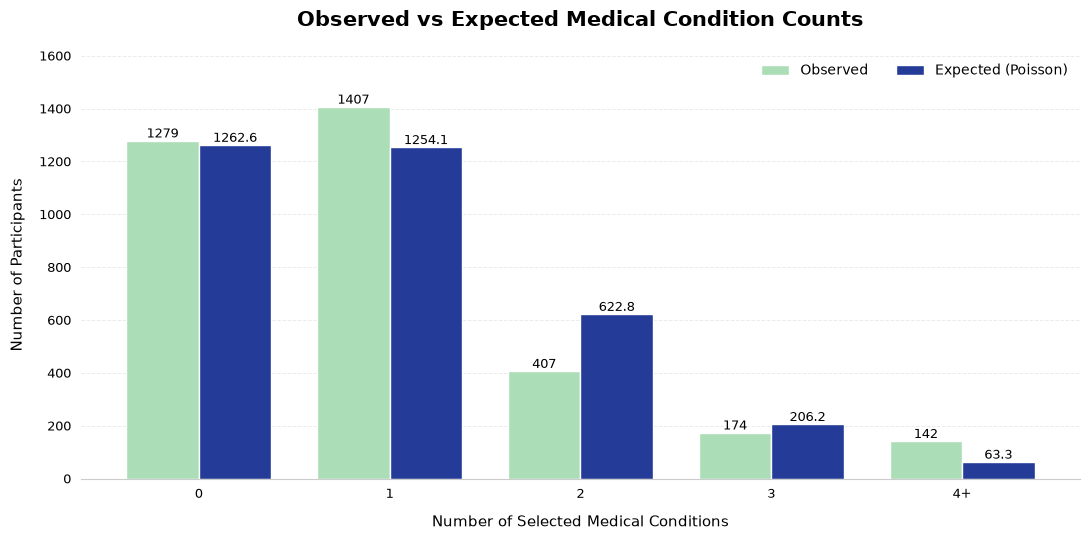

In [182]:
# Compare observed and expected frequencies
x_pos = np.arange(len(poisson_categories))
width = 0.38

# Define gradient colours
colors = plt.cm.YlGnBu(np.linspace(0.30, 0.85, 2))

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(11, 5.5))
bars_observed = ax.bar(x_pos - width / 2, observed_grouped, width, label="Observed", color=colors[0], edgecolor="white", linewidth=1.0)
bars_expected = ax.bar(x_pos + width / 2, expected_grouped, width, label="Expected (Poisson)", color=colors[1], edgecolor="white", linewidth=1.0)

# Add value labels
for bars in [bars_observed, bars_expected]:
    for bar in bars:
        value = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, value + 0.5, f"{value:.1f}" if value % 1 else f"{value:.0f}", ha="center", va="bottom", fontsize=9)

# Chart title and labels
ax.set_title("Observed vs Expected Medical Condition Counts", fontsize=15, fontweight="bold", pad=18)
ax.set_xlabel("Number of Selected Medical Conditions", fontsize=11, labelpad=10)
ax.set_ylabel("Number of Participants", fontsize=11, labelpad=10)

# Axis formatting
ax.set_xticks(x_pos)
ax.set_xticklabels(["0", "1", "2", "3", "4+"])
ax.tick_params(axis="both", labelsize=9, length=0, pad=7)
ax.set_ylim(0, max(max(observed_grouped), max(expected_grouped)) * 1.15)

# Legend
ax.legend(loc="upper right", ncol=2, frameon=False, fontsize=10)

# Grid and spines
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

plt.tight_layout()
plt.show()

#### Interpretation

For the 3,409 older adults with valid responses to all seven conditions, the estimated \(\lambda\) is 0.993, while the sample variance is 1.242 (variance-to-mean ratio = 1.25). The variance therefore exceeds the mean, indicating overdispersion relative to the Poisson equidispersion assumption. The grouped goodness-of-fit test gives \(\chi^2=196.39\), with 3 degrees of freedom and \(p<0.001\); the observed frequencies differ substantially from the fitted Poisson frequencies. The Poisson distribution is therefore a poor fit for this selected condition count. Possible dependence between chronic conditions, overdispersion, the 0–7 upper bound, self-reporting, and complete-case selection limit its use.

#### Model selection and assessment

INDFMPIR (family income-to-poverty ratio) is selected because its observed skewness is close to zero compared with the other continuous/numeric candidates. However, it is bounded between 0 and 5, and values of 5 represent a top-coded category (5 or more). Therefore, near-zero skewness alone does not establish Normality.

Assessment uses a histogram with a fitted Normal curve, a Q-Q plot, and empirical proportions within one and two standard deviations of the mean. The empirical proportions are compared with the Normal reference values of approximately 68.27% and 95.45%.

In [183]:
# Prepare non-missing INDFMPIR observations
income = older_adults_df["INDFMPIR"].dropna()
income_mean = income.mean()
income_sd = income.std()
income_skewness = income.skew()
income_z = (income - income_mean) / income_sd

within_1sd = income_z.abs().le(1).mean()
within_2sd = income_z.abs().le(2).mean()
normal_1sd = norm.cdf(1) - norm.cdf(-1)
normal_2sd = norm.cdf(2) - norm.cdf(-2)

normal_assessment = pd.DataFrame({
    "Measure": [
        "Sample size", "Mean", "Standard deviation", 
        "Skewness", "Minimum", "Maximum", 
        "At top-coded value (5.00)", "Within ±1 SD: observed", 
        "Within ±1 SD: Normal reference", "Within ±2 SD: observed", 
        "Within ±2 SD: Normal reference"],
    "Value": [len(income), income_mean, income_sd, income_skewness, income.min(), income.max(), int(income.eq(5).sum()), within_1sd * 100, normal_1sd * 100, within_2sd * 100, normal_2sd * 100]})
display(normal_assessment.round(2))

,Measure,Value
0,Sample size,2902.00
1,Mean,2.97
2,Standard deviation,1.61
3,Skewness,-0.04
4,Minimum,0.00
5,Maximum,5.00
6,At top-coded value (5.00),709.00
7,Within ±1 SD: observed,50.10
8,Within ±1 SD: Normal reference,68.27
9,Within ±2 SD: observed,100.00


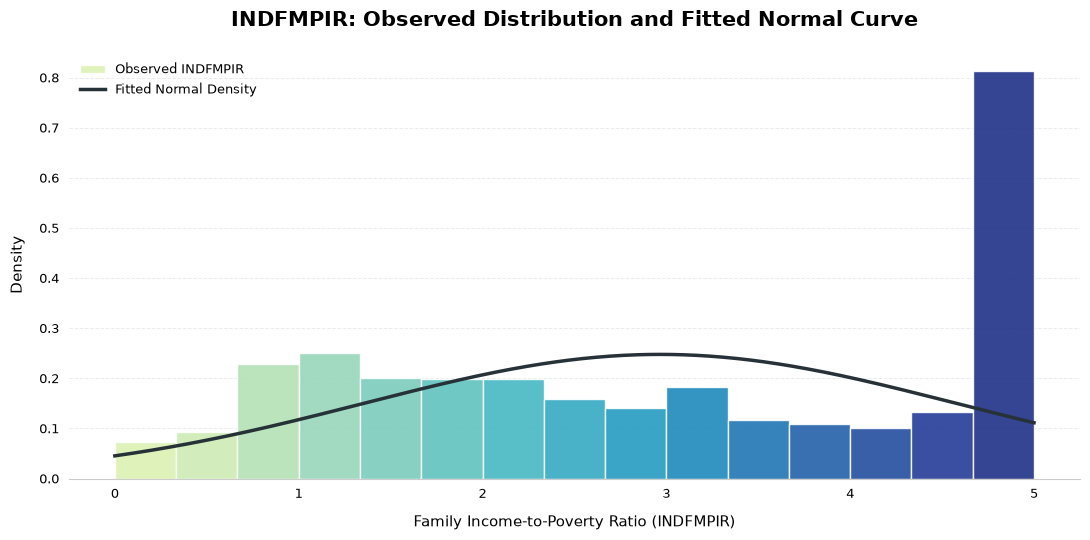

In [184]:
# Histogram with fitted Normal density curve
x_normal = np.linspace(income.min(), income.max(), 400)
normal_density = norm.pdf(x_normal, income_mean, income_sd)

# Create histogram
fig, ax = plt.subplots(figsize=(11, 5.5))
n, bins, patches = ax.hist(income, bins=15, density=True, edgecolor="white", linewidth=1.0, alpha=0.9, label="Observed INDFMPIR")

# Apply YlGnBu gradient to each histogram bar
colors = plt.cm.YlGnBu(np.linspace(0.18, 0.90, len(patches)))
for patch, color in zip(patches, colors):
    patch.set_facecolor(color)

# Add fitted Normal density curve
ax.plot(x_normal, normal_density, color="#263238", linewidth=2.5, label="Fitted Normal Density")

# Chart title and labels
ax.set_title("INDFMPIR: Observed Distribution and Fitted Normal Curve", fontsize=15, fontweight="bold", pad=18)
ax.set_xlabel("Family Income-to-Poverty Ratio (INDFMPIR)", fontsize=11, labelpad=10)
ax.set_ylabel("Density", fontsize=11, labelpad=10)

# Axis formatting
ax.tick_params(axis="both", labelsize=9, length=0, pad=7)

# Legend: right side
ax.legend(loc="upper left", frameon=False, fontsize=9)

# Grid and spines
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.25)
ax.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#CCCCCC")

plt.tight_layout()
plt.show()

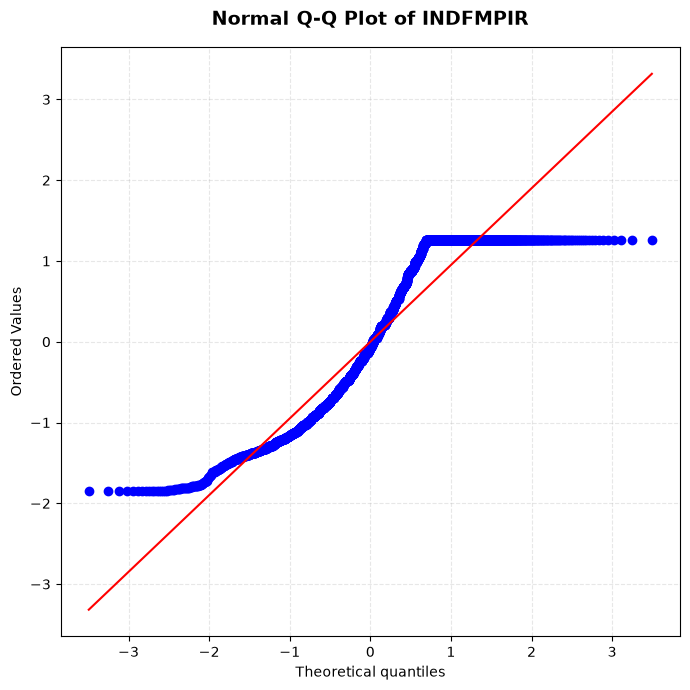

In [185]:
# Normal Q-Q plot
fig, ax = plt.subplots(figsize=(7, 7))
probplot(income_z, dist="norm", plot=ax)
ax.set_title("Normal Q-Q Plot of INDFMPIR", fontsize=14, fontweight="bold", pad=16)
ax.grid(linestyle="--", alpha=0.3)
fig.tight_layout()
plt.show()

#### Interpretation

INDFMPIR has near-zero skewness (-0.037), but the other diagnostics do not support a Normal model. Only about 50.1% of observations fall within ±1 SD, compared with the Normal reference of 68.3%; 100.0% fall within ±2 SD, compared with 95.45%. The Q-Q plot shows a clear departure from the reference line, particularly at the tails, and 709 observations are at the top-coded value of 5.00. Therefore, INDFMPIR is the closest-to-symmetric candidate among the selected numeric variables, but it is **not well described by an unbounded Normal distribution**. The fitted curve is a comparison reference only.

### Comparison and critical discussion

In [186]:
# Final validation checks for Section 6
required_columns = {
    "older_adults_df": ["RIDAGEYR", "INDFMPIR"] + mcq_condition_vars,
    "phq9_complete_df": ["PHQ9_Total"]
}
for frame_name, columns in required_columns.items():
    frame = globals()[frame_name]
    missing_columns = [col for col in columns if col not in frame.columns]
    assert not missing_columns, f"{frame_name} is missing columns: {missing_columns}"

assert phq9_n > 0 and 0 <= p_hat <= 1
assert len(medical_condition_count) > 0
assert medical_condition_count.between(0, len(mcq_condition_vars)).all()
assert income_sd > 0
assert np.isclose(observed_grouped.sum(), poisson_n)
assert np.isclose(expected_grouped.sum(), poisson_n)

print("Section 6 validation passed.")
print(f"Numerical analysis: age n={older_adults_df['RIDAGEYR'].notna().sum():,}; "
      f"INDFMPIR n={len(income):,}; PHQ-9 n={phq9_n:,}")
print(f"Binomial: n={n_trials}, p={p_hat:.4f}")
print(f"Poisson: n={poisson_n:,}, lambda={lambda_hat:.3f}, "
      f"variance={observed_variance:.3f}, chi-square p={poisson_p:.3e}")
print(f"Normal candidate: INDFMPIR skewness={income_skewness:.3f}")

Section 6 validation passed.
Numerical analysis: age n=3,504; INDFMPIR n=2,902; PHQ-9 n=2,394
Binomial: n=100, p=0.0931
Poisson: n=3,409, lambda=0.993, variance=1.242, chi-square p=2.536e-42
Normal candidate: INDFMPIR skewness=-0.037


In [188]:
# Export missing values report for all datasets
#missing_report = []

#for name, df in datasets.items():
#    data_cols = [col for col in df.columns if col != "SEQN"]
#    missing_cells = int(df[data_cols].isna().sum().sum())
#    total_cells = len(df) * len(data_cols)

#    missing_report.append({
#        "Rows": len(df),
#        "Columns": len(df.columns),
#        "Missing_SEQN": int(df["SEQN"].isna().sum()),
#        "Missing_Cells": missing_cells,
#        "Missing_Cell_Percentage(%)": round(missing_cells / total_cells * 100, 2) if total_cells > 0 else 0
#    })

# Create summary DataFrame
#missing_values_report = pd.DataFrame(missing_report)

# Display report
#display(missing_values_report)

# Export to CSV
#missing_values_report.to_csv("missing_values_report.csv", index=False, encoding="utf-8-sig")
#print("Export completed: missing_values_report.csv")

In [189]:
# Export cleaning quality summary
#cleaning_quality_summary = categorical_quality_summary.copy()

# Display results
#display(cleaning_quality_summary)

# Export CSV
#cleaning_quality_summary.to_csv("cleaning_quality_summary.csv", index=False, encoding="utf-8-sig")
#print("Export completed: cleaning_quality_summary.csv")

In [190]:
# Create data dictionary for all datasets
#data_dictionary = []
#for name, df in datasets.items():
 #   for col in df.columns:
  #      data_dictionary.append({
  #          "Source_File": name,
  #          "Variable": col,
  #          "Data_Type": str(df[col].dtype),
  #          "Missing_Count": df[col].isna().sum(),
  #          "Missing_Percentage": round(df[col].isna().mean() * 100, 2),
  #          "Unique_Values": df[col].nunique(),
  #          "Sample_Values": str(df[col].dropna().unique()[:5])
  #      })

#data_dictionary = pd.DataFrame(data_dictionary)
#display(data_dictionary)

In [191]:
# Export data dictionary
#data_dictionary.to_csv("data_dictionary.csv", index=False, encoding="utf-8-sig")